# MẠNG 1D-TCN NHẸ VÀ LƯỢNG TỬ HÓA INT8 CHO ƯỚC LƯỢNG NHỊP TIM TỪ PPG VÀ GIA TỐC TRÊN PPG-DaLiA

**Sinh viên:** Đinh Lê Hoàng Danh · **MSSV:** 23110082  
**Lớp học phần:** AIOT331185_01CLC · **Giảng viên:** ThS. Hồ Nhựt Minh

### Tóm tắt

Đề tài khảo sát ước lượng nhịp tim từ PPG cổ tay và gia tốc ba trục bằng
mạng tích chập giãn 1D nhẹ, sau đó đánh giá lượng tử hóa tĩnh 8 bit trên CPU.
PPG-DaLiA được chia theo người thành Train S1–S10, Validation S11–S12 và
Test S13–S15. Đối chứng gồm FFT, IBI, mạng PPG-only, mạng PPG+ACC FP32 và
phiên bản PTQ INT8; các cấu hình học sâu được đánh giá với seed 42/123/999.

Lần Run All ngày **05/10/2026** được trình bày trong notebook này cho MAE
Test macro theo người **4,816 ± 0,119 BPM** ở PPG+ACC FP32 và
**4,826 ± 0,127 BPM** ở INT8, tính mean ± sample std qua ba seed trên
**13.007 cửa sổ Test** mỗi seed. Cả hai đạt mục tiêu MAE ≤6,0 BPM.
Mạng PPG+ACC có **25.857 tham số**; tệp suy luận giảm từ **112.373 xuống
39.925 byte**, tương ứng **2,815 lần**, với ΔMAE trung bình **+0,010 BPM**.

PPG-only đạt **4,768 ± 0,080 BPM**. Thêm ACC làm MAE trung bình tăng
**0,048 BPM**, dù hai trong ba seed có cải thiện; kết quả chưa cho thấy
lợi ích ACC nhất quán và không chứng minh khử nhiễu dạng sóng.
INT8 có median latency thấp hơn ở cả ba seed, nhưng mean latency của
seed 123 cao hơn FP32. Kết quả thể hiện đánh đổi sai số–dung lượng–thời gian
trên CPU máy tính với tiền xử lý ngoại tuyến, trong phạm vi giao thức môn học.

**Từ khóa:** PPG, gia tốc, hồi quy nhịp tim, Conv1D giãn, PTQ, INT8, PPG-DaLiA.


### Mục lục

0. Môi trường thực nghiệm  
1. Đặt vấn đề và mục tiêu nghiên cứu  
2. Dữ liệu, nhãn tham chiếu và phân chia theo người  
3. Tiền xử lý tín hiệu và tập cửa sổ chung  
4. Phân tích đặc điểm dữ liệu  
5. Đối chuẩn FFT và IBI  
6. Kiến trúc mạng tích chập giãn 1D  
7. Huấn luyện và lựa chọn checkpoint  
8. Lượng tử hóa tĩnh 8 bit  
9. Giao thức đánh giá và chỉ số  
10. Dung lượng tệp và thời gian suy luận CPU  
11. Phân tích sai số và trường hợp thất bại  
12. Trình diễn pipeline và phương án firmware giả lập  
13. Kết quả, thảo luận và giới hạn nghiên cứu  
14. Tài liệu tham khảo


## 0. Môi trường thực nghiệm

Huấn luyện sử dụng Python **3.11.15**, PyTorch **2.10.0+cu126** và GPU
**NVIDIA GeForce RTX 4050 Laptop 6 GB**. PTQ và benchmark suy luận sử dụng
CPU **12th Gen Intel(R) Core(TM) i5-12450H**, hệ điều hành **Windows 11 Home
Single Language**, backend **oneDNN**, một luồng tính toán. Chuỗi định danh
`Windows-10-10.0.26300-SP0` trong trường `platform_python` là giá trị do
Python trả về; tên hệ điều hành được đối chiếu riêng trong metadata runtime.
Thời gian đo là thời gian mạng trên CPU, tách khỏi quá trình huấn luyện GPU.

Nguồn thực nghiệm của các bảng, hình và kết luận trong notebook là workspace
`20261005T080438565912Z-f1bf0c7c`, được tạo từ thực nghiệm ngày 05/10/2026.
Workspace lưu snapshot mã/cấu hình/môi trường, manifest, thống kê chuẩn hóa,
lịch sử huấn luyện, trọng số, dự đoán và kết quả theo cùng nguồn.
Lần chạy này được chọn làm **kết quả chính của project**; model và results
chọn lọc trong `published/` được sao chép từ cùng nguồn. Bộ kết quả ngày
04/10/2026 ở root và bản published trước sửa được lưu riêng để truy vết,
không được ghép vào thống kê của lần chạy này.

Notebook trình bày dữ liệu gốc, tiền xử lý, EDA, E0–E4, phân tích và replay.
Mã có nhánh chuẩn bị môi trường và lưu đầu ra trên Google Colab/Drive;
các số đo báo cáo ở đây được tạo trên laptop nêu trên.


In [1]:
from pathlib import Path
import os, sys, json, shutil, subprocess
IN_COLAB = "google.colab" in sys.modules
PROJECT_DIR = Path(os.environ.get("PPG_PROJECT_ROOT", "/content/IoT_DACK" if IN_COLAB else Path.cwd())).resolve()
REPO_URL = ""

In [2]:
if IN_COLAB and not (PROJECT_DIR / "pyproject.toml").is_file() and REPO_URL:
    subprocess.run(["git", "clone", REPO_URL, str(PROJECT_DIR)], check=True)
if not all((PROJECT_DIR / name).is_file() for name in ("pyproject.toml", "configs/default.toml")):
    raise FileNotFoundError("Open this notebook from the IoT_DACK repository root")
os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR / "src"))

In [3]:
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements-gpu-base.txt"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    PERSIST_DIR = Path("/content/drive/MyDrive/IoT_DACK_outputs")
else:
    PERSIST_DIR = Path(os.environ["PPG_PERSIST_DIR"]) if os.environ.get("PPG_PERSIST_DIR") else None

In [4]:
print({"notebook_python": sys.version, "project": str(PROJECT_DIR), "colab": IN_COLAB})

{'notebook_python': '3.11.15 (main, Jun 23 2026, 15:20:37) [MSC v.1944 64 bit (AMD64)]', 'project': 'D:\\IoT_DACK', 'colab': False}


NumPy và Pandas được sử dụng cho dữ liệu và bảng kết quả; SciPy thực hiện lọc,
hạ mẫu và phát hiện đỉnh; PyTorch đảm nhiệm huấn luyện, PTQ và suy luận.
Các biểu đồ tín hiệu, đặc điểm dữ liệu và sai số được dựng bằng Matplotlib.


In [5]:
from __future__ import annotations
import copy
import json
import math
import os

In [6]:
import platform
import random
import subprocess
import sys
import time

In [7]:
import warnings
from pathlib import Path
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import numpy as np
import pandas as pd

In [8]:
import scipy
from scipy import signal as sp_signal
import matplotlib
if "get_ipython" in globals():
    get_ipython().run_line_magic("matplotlib", "inline")
else: matplotlib.use("Agg")
import matplotlib.pyplot as plt


In [9]:
import torch
from torch import nn
from torch.ao.quantization import QuantStub, DeQuantStub, fuse_modules
from torch.ao.quantization import get_default_qconfig, prepare, convert
from ppg_iot.config import ROOT, SUBJECTS, SPLITS, load_config, project_path

In [10]:
from ppg_iot.provenance import RunRecorder, hash_object, sha256_file, write_json, now_utc, code_snapshot, fingerprint
from ppg_iot.data.loader import load_subject, dataset_root
from ppg_iot.data.alignment import validate_alignment
from ppg_iot.execution import create_notebook_workspace, require_unlocked
from ppg_iot.data.preprocessing import filter_continuous, normalize_ppg, normalize_acc
from ppg_iot.metrics import join_predictions, compute_metrics, train_median_fallback
from ppg_iot.metrics import paired_subset_metrics, summarize_seeds, ACTIVITIES
from ppg_iot.hardware import environment_names


In [11]:
assert sys.version_info[:2] == (3, 11) and torch.__version__.split("+")[0] == "2.10.0"

In [12]:
assert torch.cuda.is_available(), "Select the verified RTX 4050 GPU kernel or a compatible Colab GPU runtime"

In [13]:
from IPython.display import display, Markdown
from ppg_iot.data.alignment import validate_alignment
from ppg_iot.provenance import fingerprint
NOTEBOOK_PATH = PROJECT_DIR / "DinhLeHoangDanh_DoAn_PPG_DaLiA.ipynb"

In [14]:
def export_notebook_functions():
    book = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
    sources = ["".join(cell["source"]) for cell in book["cells"]
               if cell["metadata"].get("ppg_project", {}).get("workflow_source")]
    target = PROJECT_DIR / "src/ppg_iot/notebook_workflow.py"
    payload = chr(34)*3 + "Auxiliary export of main notebook scientific cells." + chr(34)*3 + "\n" + "\n\n".join(sources) + "\n"
    target.write_text(payload, encoding="utf-8")
    return {"export": str(target), "n_source_cells": len(sources)}

In [15]:
def persist_outputs():
    if PERSIST_DIR:
        shutil.copytree(PROJECT_DIR, PERSIST_DIR / PROJECT_DIR.name, dirs_exist_ok=True)


In [16]:
def run_stage(name):
    calls = {"eda": lambda: analysis_stage(CTX), "baseline": lambda: baseline_stage(CTX),
        "benchmark_review": lambda: review_benchmark(CTX),
        "pilot": lambda: training_stage(CTX, kind="pilot", seeds=(42,), resume=True),
        "train": lambda: training_stage(CTX, resume=True), "ptq": lambda: ptq_stage(CTX),
        "lock": lambda: lock_protocol(CTX), "evaluate": lambda: evaluation_stage(CTX),
        "diagnostic": lambda: evaluation_stage(CTX, split="all"),
        "benchmark": lambda: benchmark_stage(CTX), "report_assets": lambda: report_assets_stage(CTX),
        "demo": lambda: demo_stage(CTX)}
    result = calls[name]()
    persist_outputs()
    return result


In [17]:
def show_table(relative, limit=20):
    frame = pd.read_csv(PROJECT_DIR / relative, float_precision="round_trip")
    display(frame.head(limit))

In [18]:
def show_json(relative):
    display(read_json(PROJECT_DIR / relative))

In [19]:
def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

In [20]:
def read_frame(path):
    """Preserve reference values exactly across CSV round trips."""
    return pd.read_csv(path, float_precision="round_trip")

In [21]:
def cached_arrays(ctx,subject):
    return ctx["arrays"][subject]

In [22]:
def log_test_access(ctx, access_type, *, status="started", detail=None):
    path = ctx["root"] / "results/test_access.jsonl"
    record = {"at": now_utc(), "access_type": access_type, "status": status,
              "subjects": list(SPLITS["test"]), "detail": detail,
              "preprocess_hash": ctx["index"]["preprocess_hash"]}
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("a", encoding="utf-8") as stream:
        stream.write(json.dumps(record, ensure_ascii=False, allow_nan=False) + "\n")

In [23]:
def notebook_download(url,path):
    import urllib.request
    path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_name(path.name+".part")
    request=urllib.request.Request(url,headers={"User-Agent":"PPG-DaLiA-final-project/1.0"})
    total=0
    with urllib.request.urlopen(request,timeout=45) as response, temporary.open("wb") as output:
        while chunk:=response.read(1024*1024):
            output.write(chunk); total+=len(chunk)
            if total%(256*1024*1024)<1024*1024: print(f"Downloaded {total//1024**2} MiB",flush=True)
    if not total: raise RuntimeError(f"Empty download: {url}")
    temporary.replace(path)
    return path

In [24]:
def notebook_zip_members(archive):
    import re
    members={}
    for item in archive.infolist():
        match=re.fullmatch(r"(?:[^/]+/)*(S(?:[1-9]|1[0-5]))/\1\.pkl",item.filename)
        if match:
            if match[1] in members: raise ValueError(f"Duplicate source member: {match[1]}")
            members[match[1]]=item
    if set(members)!=set(SUBJECTS): raise ValueError("Source archive must contain all 15 subjects")
    return members

In [25]:
def notebook_extract_subjects(archive,data_root):
    import shutil
    sources={}
    for subject,member in notebook_zip_members(archive).items():
        target=data_root/subject/f"{subject}.pkl"; target.parent.mkdir(parents=True,exist_ok=True)
        temporary=target.with_name(target.name+".part")
        with archive.open(member) as source,temporary.open("wb") as output:
            shutil.copyfileobj(source,output,length=1024*1024)
        if temporary.stat().st_size!=member.file_size: raise ValueError(f"Truncated {subject}")
        temporary.replace(target)
        sources[subject]={**fingerprint(target),"archive_member":member.filename,
                          "zip_crc32":f"{member.CRC:08x}"}
        print(f"{subject}: extracted and ZIP CRC verified",flush=True)
    return sources

In [26]:
def notebook_write_source_report(root,readme,sources):
    result={"schema_version":1,"acquired_at":now_utc(),"dataset":"PPG-DaLiA",
        "dataset_page":"https://archive.ics.uci.edu/dataset/495/ppg%2Bdalia",
        "license":"Scientific/non-commercial use with attribution (author host)",
        "archive":{"url":"https://uni-siegen.sciebo.de/s/pfHzlTepXkiJ4JpP/download",
                   "selection":"15 synchronized pickles; member CRC verified; partial range source"},
        "readme":{**fingerprint(readme),"url":"https://archive.ics.uci.edu/ml/machine-learning-databases/00495/readme.pdf"},
        "subjects":sources,"scope":"official synchronized pickles; no evaluation performed"}
    report=root/"results/data_sources.json"; report.parent.mkdir(parents=True,exist_ok=True)
    write_json(report,result)
    return result

In [27]:
def notebook_local_source_report(root,data_root):
    sources={s:fingerprint(data_root/s/f"{s}.pkl") for s in SUBJECTS}
    readme=data_root/"readme.pdf"
    if not readme.is_file():
        base="https://archive.ics.uci.edu/ml/machine-learning-databases/00495/"
        readme=notebook_download(base+"readme.pdf",readme)
    report={"schema_version":1,"acquired_at":now_utc(),"dataset":"PPG-DaLiA",
        "origin":"locally supplied synchronized pickles; archive origin/CRC not independently verified",
        "readme":fingerprint(readme),"subjects":sources,
        "scope":"Actual file hashes; schema/alignment checked by the loader"}
    write_json(root/"results/data_sources.json",report)
    return report


In [28]:
def notebook_acquire_if_missing(root):
    import zipfile
    from ppg_iot.data.remote_zip import HTTPRangeFile
    require_unlocked(root)
    data_root=dataset_root(); report=root/"results/data_sources.json"
    missing=[s for s in SUBJECTS if not (data_root/s/f"{s}.pkl").is_file()]
    if not missing:
        return read_json(report) if report.is_file() else notebook_local_source_report(root,data_root)
    base="https://archive.ics.uci.edu/ml/machine-learning-databases/00495/"
    readme=notebook_download(base+"readme.pdf",data_root/"readme.pdf")
    remote=HTTPRangeFile("https://uni-siegen.sciebo.de/s/pfHzlTepXkiJ4JpP/download")
    try:
        with zipfile.ZipFile(remote) as archive:
            sources=notebook_extract_subjects(archive,data_root)
    finally: remote.close()
    return notebook_write_source_report(root,readme,sources)


In [29]:
def notebook_load_raw_subjects(root):
    sources=notebook_acquire_if_missing(root)
    records={}
    for subject,source in sources["subjects"].items():
        if subject not in SUBJECTS: raise ValueError(f"Unexpected dataset subject: {subject}")
        record=load_subject(subject,dataset_root(),source)
        validate_alignment(record)
        records[subject]=record
        print(f"{subject}: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified",flush=True)
    if set(records)!=set(SUBJECTS): raise ValueError("Need all 15 synchronized subjects")
    return sources,records

In [30]:
def notebook_source_tables(sources,records):
    inventory=[]; alignment=[]
    for subject in SUBJECTS:
        record=records[subject]
        duration=len(record.ppg64)/record.ppg_hz
        inventory.append({"subject_id":subject,"source_sha256":record.source_sha256,
            "ppg_samples":len(record.ppg64),"acc_samples":len(record.acc32),
            "ecg_samples":record.ecg_sample_count,"hr_windows":len(record.hr_labels),
            "activity_codes":list(map(int,np.unique(record.activity_labels))),
            "duration_seconds":duration,"finite_ppg":bool(np.isfinite(record.ppg64).all()),
            "finite_acc":bool(np.isfinite(record.acc32).all()),
            "finite_hr":bool(np.isfinite(record.hr_labels).all()),
            "nonfinite_ppg_samples":int((~np.isfinite(record.ppg64)).sum()),
            "nonfinite_acc_values":int((~np.isfinite(record.acc32)).sum()),
            "invalid_hr_labels":int((~np.isfinite(record.hr_labels)|(record.hr_labels<=0)).sum()),
            "schema":record.schema_details,
            "split":next(key for key,values in SPLITS.items() if subject in values)})
        alignment.append({"subject_id":subject,"passed":True,"ppg_hz":record.ppg_hz,
            "acc_hz":record.acc_hz,"ecg_hz":record.ecg_hz,"activity_hz":record.activity_hz,
            "hr_windows":len(record.hr_labels),"first_hr":float(record.hr_labels[0]),
            "middle_hr":float(record.hr_labels[len(record.hr_labels)//2]),
            "last_hr":float(record.hr_labels[-1]),"label_seconds":"[2*i, 2*i+8)"})
    return pd.DataFrame(inventory),{"schema_version":1,"passed":True,
        "scope":"15 original subjects; exact sampled-rate alignment; ECG-derived HR labels",
        "readme_sha256":sources["readme"]["sha256"],"subjects":alignment}

In [31]:
def notebook_write_source_checks(root,inventory,alignment):
    require_unlocked(root)
    inventory_path=root/"results/data_inventory.json"
    alignment_path=root/"results/alignment.json"
    write_json(inventory_path,{"schema_version":1,"passed":True,"gate":"G02",
        "subjects":inventory.to_dict("records"),"errors":[]})
    write_json(alignment_path,alignment)
    return {"inventory":inventory_path,"alignment":alignment_path,
            "inventory_sha256":sha256_file(inventory_path),
            "alignment_sha256":sha256_file(alignment_path)}


In [32]:
def notebook_record_user_decision(ctx):
    review=ctx["root"]/"results/benchmark_review.json"
    decision={"schema_version":1,"decision":"use_original_ecg_final32",
        "authorized_by":"user","user_message":"Chốt dùng ECG gốc và giao thức cuối kỳ để train",
        "reference_verified":False,"review_sha256":sha256_file(review),
        "scope":"Use original ECG-derived HR labels and the final-project 32 Hz protocol; retain D01 benchmark as unverified."}
    path=ctx["root"]/"results/benchmark_source_decision.json"
    write_json(path,decision)
    return decision

In [33]:
def filter_subject_ppg(record,config):
    from scipy.signal import butter,resample_poly,sosfiltfilt
    band=config["filter"]["band_hz"]
    sos=butter(config["filter"]["prototype_order"],band,btype="bandpass",
               fs=record.ppg_hz,output="sos")
    filtered=sosfiltfilt(sos,record.ppg64,padtype="odd",padlen=None)
    output=resample_poly(filtered,up=1,down=2,window=("kaiser",5.0),padtype="constant")
    if len(output)!=len(record.acc32) or not np.isfinite(output).all():
        raise ValueError(f"{record.subject_id}: invalid 64→32 Hz filtered signal")
    return output

In [34]:
def merge_acc_moments(state,values):
    count,mean,moment=state
    current_count=len(values)
    current_mean=values.mean(axis=0)
    current_moment=np.square(values-current_mean).sum(axis=0)
    delta=current_mean-mean
    total=count+current_count
    return (total,mean+delta*current_count/total,
            moment+current_moment+delta**2*count*current_count/total)

In [35]:
def fit_notebook_acc_statistics(records,epsilon=1e-8):
    state=(0,np.zeros(3,dtype=np.float64),np.zeros(3,dtype=np.float64))
    subjects=[]
    for subject in SPLITS["train"]:
        record=records[subject]
        values=record.acc32.astype(np.float64,copy=False)
        state=merge_acc_moments(state,values)
        subjects.append({"subject_id":subject,"samples":len(values),
                         "source_sha256":record.source_sha256})
    count,mean,moment=state
    std=np.sqrt(moment/count)
    stats={"schema_version":1,"fit_split":"train","domain":"continuous_aligned_record",
        "ddof":0,"epsilon":epsilon,"n_samples_per_axis":count,"mean":mean.tolist(),
        "std":std.tolist(),"denominator":np.maximum(std,epsilon).tolist(),"subjects":subjects}
    stats["sha256"]=hash_object(stats)
    return stats

In [36]:
def normalize_notebook_acc(values,stats):
    unhashed={key:value for key,value in stats.items() if key!="sha256"}
    if stats["sha256"]!=hash_object(unhashed) or stats["fit_split"]!="train":
        raise ValueError("ACC normalization must use frozen Train-only statistics")
    result=(values-np.asarray(stats["mean"]))/np.asarray(stats["denominator"])
    if not np.isfinite(result).all(): raise ValueError("Nonfinite normalized ACC")
    return result.astype(np.float32)

In [37]:
def normalize_notebook_ppg(window,epsilon=1e-8):
    if window.shape!=(256,) or not np.isfinite(window).all():
        raise ValueError("One finite 8 s PPG window at 32 Hz is required")
    scale=max(float(window.std(ddof=0)),epsilon)
    return ((window-window.mean())/scale).astype(np.float32)

In [38]:
def assign_window_activity(labels,start_s,end_s,fs=4,min_fraction=.8):
    begin,stop=int(np.floor(start_s*fs)),int(np.ceil(end_s*fs))
    indices=np.arange(begin,stop)
    durations=np.maximum(0,np.minimum((indices+1)/fs,end_s)-np.maximum(indices/fs,start_s))
    codes=np.unique(labels[begin:stop])
    totals=np.array([durations[labels[begin:stop]==code].sum() for code in codes])
    dominant=int(codes[np.argmax(totals)]); fraction=float(totals.max()/(end_s-start_s))
    if dominant not in range(9): status,activity="unknown",None
    elif dominant>0 and fraction>=min_fraction: status,activity="assigned",dominant
    else: status,activity="mixed_transition",None
    return {"activity_id":activity,"activity_fraction":fraction,
            "activity_status":status,"dominant_activity_code":dominant}

In [39]:
def notebook_build_manifest(record,filtered,preprocess_hash,config):
    split=next(name for name,ids in SPLITS.items() if record.subject_id in ids)
    rows=[]
    for index,reference in enumerate(record.hr_labels):
        start=2*index; end=start+8
        p0,p1=start*32,end*32
        if p1>len(filtered): raise ValueError("Incomplete final label window")
        activity=assign_window_activity(record.activity_labels,start,end,
                                         min_fraction=config["signal"]["activity_min_fraction"])
        reason="nonfinite_hr_reference" if not np.isfinite(reference) else (
               "nonpositive_hr_reference" if reference<=0 else "")
        rows.append({"window_id":f"{config['run']['protocol_version']}:{record.subject_id}:{index:06d}",
            "subject_id":record.subject_id,"split":split,"label_index":index,
            "start_s":start,"end_s":end,"ppg_start_idx":p0,"ppg_end_idx":p1,
            "acc_start_idx":p0,"acc_end_idx":p1,"ppg_native_start_idx":p0*2,"ppg_native_end_idx":p1*2,
            "hr_ref_bpm":float(reference),**activity,"eligible":not reason,
            "exclusion_reason":reason,"ppg_flat":bool(filtered[p0:p1].std(ddof=0)==0),
            "source_sha256":record.source_sha256,"preprocess_hash":preprocess_hash})
    return pd.DataFrame(rows)

In [40]:
def notebook_preprocess_records(root,records,config):
    stats=fit_notebook_acc_statistics(records,config["signal"]["normalization_epsilon"])
    filtered={subject:filter_subject_ppg(record,config) for subject,record in records.items()}
    source_hashes={subject:records[subject].source_sha256 for subject in SUBJECTS}
    recipe={"config_sha256":hash_object(config),"alignment":"ECG labels 8 s/2 s; PPG 64→32 Hz",
        "filter":"Butterworth order 2, 0.5-4 Hz, SOS zero-phase on full subject; polyphase 1/2",
        "window":"256 samples at 32 Hz; 8 seconds; 2-second step; PPG bounds use actual 32 Hz indices",
        "sources":source_hashes,"stats_sha256":stats["sha256"],
        "normalization":"PPG per-window population; ACC continuous Train-only population"}
    preprocess_hash=hash_object(recipe)
    manifest=pd.concat([notebook_build_manifest(records[s],filtered[s],preprocess_hash,config)
                        for s in SUBJECTS],ignore_index=True)
    if manifest.window_id.duplicated().any(): raise ValueError("Duplicate common manifest IDs")
    return stats,filtered,manifest,preprocess_hash,recipe

In [41]:
def notebook_write_cache(root,records,stats,filtered,manifest,preprocess_hash,recipe,config):
    out=root/"results/manifests"; out.mkdir(parents=True,exist_ok=True)
    cache=root/"data/processed"/preprocess_hash; cache.mkdir(parents=True,exist_ok=True)
    entries={}
    for subject in SUBJECTS:
        ppg_path=cache/f"{subject}_ppg32.npy"
        acc_path=cache/f"{subject}_acc32_normalized.npy"
        acc=normalize_notebook_acc(records[subject].acc32,stats)
        np.save(ppg_path,filtered[subject],allow_pickle=False)
        np.save(acc_path,acc,allow_pickle=False)
        entries[subject]={"source_sha256":records[subject].source_sha256,
            "ppg32":{"file":ppg_path.name,"sha256":sha256_file(ppg_path)},
            "acc32_normalized":{"file":acc_path.name,"sha256":sha256_file(acc_path)}}
    manifest_path=out/"windows.csv"; manifest.to_csv(manifest_path,index=False)
    stats_path=out/"acc_stats.json"; write_json(stats_path,stats)
    recipe_path=out/"preprocessing.json"; write_json(recipe_path,{"preprocess_hash":preprocess_hash,"recipe":recipe})
    return cache,out,entries,manifest_path,stats_path,recipe_path

In [42]:
def notebook_write_indices(root,records,cache,out,entries,manifest_path,stats_path,recipe_path,
                           preprocess_hash,inventory,alignment,manifest):
    index_path=cache/"processed_index.json"
    index={"schema_version":1,"passed":True,"preprocess_hash":preprocess_hash,"subjects":entries,
           "manifest_sha256":sha256_file(manifest_path),"acc_stats_sha256":sha256_file(stats_path)}
    write_json(index_path,index)
    pointer={"cache_relative_path":index_path.relative_to(root).as_posix(),
        "index_sha256":sha256_file(index_path),"preprocess_hash":preprocess_hash,
        "manifest_sha256":sha256_file(manifest_path)}
    write_json(out/"processed_index.json",pointer)
    write_json(out/"checks.json",{"gate":"G03","passed":True,"n_subjects":len(records),
        "n_candidates":len(manifest),
        "n_eligible":int(inventory.eligible_windows.sum()),
        "preprocess_hash":preprocess_hash,"manifest_sha256":sha256_file(manifest_path)})
    write_json(root/"results/data_inventory.json",{"schema_version":1,"passed":True,
        "gate":"G02","subjects":inventory.to_dict("records"),"errors":[]})
    write_json(root/"results/alignment.json",alignment)
    return index_path,pointer

In [43]:
def notebook_prepare_project(root,sources,records,inventory,alignment):
    require_unlocked(root)
    config=load_config(root/"configs/default.toml",root=root)
    stats,filtered,manifest,preprocess_hash,recipe=notebook_preprocess_records(root,records,config)
    inventory=inventory.assign(eligible_windows=[
        int(manifest.loc[manifest.subject_id==subject,"eligible"].sum()) for subject in SUBJECTS])
    cache,out,entries,manifest_path,stats_path,recipe_path=notebook_write_cache(
        root,records,stats,filtered,manifest,preprocess_hash,recipe,config)
    index_path,pointer=notebook_write_indices(root,records,cache,out,entries,manifest_path,
        stats_path,recipe_path,preprocess_hash,inventory,alignment,manifest)
    arrays={subject:{"ppg32":filtered[subject],
        "acc32_normalized":normalize_notebook_acc(records[subject].acc32,stats)} for subject in SUBJECTS}
    ctx={"root":root,"config":config,"manifest":manifest,"manifest_path":manifest_path,
        "index":read_json(index_path),"index_path":index_path,"cache":cache,"stats":stats,
        "arrays":arrays,"raw_records":records,"sources":sources,"inventory":inventory}
    return ctx,inventory

In [44]:
from ppg_iot.provenance import write_json

In [45]:
export_notebook_functions()
SOURCE_PROJECT_DIR = PROJECT_DIR
os.environ.setdefault("PPG_DALIA_DIR", str(dataset_root()))
PROJECT_DIR = create_notebook_workspace(SOURCE_PROJECT_DIR, NOTEBOOK_PATH,
    run_id=os.environ.get("PPG_EXECUTION_ID"), resume_run=os.environ.get("PPG_RESUME_RUN"))
print({"execution_workspace": str(PROJECT_DIR), "dataset": str(dataset_root())})


{'execution_workspace': 'D:\\IoT_DACK\\results\\notebook_runs\\20261005T080438565912Z-f1bf0c7c', 'dataset': 'D:\\IoT_DACK\\data\\raw'}


## 1. Đặt vấn đề và mục tiêu nghiên cứu

PPG cổ tay phù hợp với thiết bị đeo nhưng chịu ảnh hưởng của chuyển động.
Thành phần chuyển động có thể chồng lấp với dải tần nhịp mạch, gây sai số cho
các phương pháp tìm đỉnh phổ hoặc đếm đỉnh [1], [2]. Đề tài khảo sát một mô hình
học sâu đa cảm biến nhỏ gọn, trong đó ACC cung cấp thông tin chuyển động bổ trợ
cho PPG và PTQ giảm dung lượng tệp suy luận sau huấn luyện.

Với cửa sổ 8 giây ở 32 Hz, đầu vào $x\in\mathbb R^{4\times256}$ gồm PPG,
ACCx, ACCy và ACCz; đầu ra $f_\theta(x)$ là một giá trị HR, đơn vị BPM.
Ba nội dung được khảo sát là mức cải thiện so với DSP, đóng góp dự đoán của
ACC và đánh đổi accuracy–dung lượng–latency khi chuyển FP32 sang 8 bit.

| Mã | Phương pháp | Thiết kế đối chứng |
|---|---|---|
| E0 | FFT trên PPG đã lọc | Đối chuẩn miền tần số |
| E1 | IBI từ đỉnh PPG | Pure IBI và phương án dự phòng median HR Train |
| E2 | Mạng PPG-only FP32 | Đối chứng đầu vào cảm biến, ba seed |
| E3 | Mạng PPG+ACC FP32 | Mô hình đề xuất, ba seed |
| E4 | PTQ tĩnh 8 bit từ từng E3 | Ba cặp checkpoint, cùng calibration |

Chỉ tiêu thiết kế gồm MAE Test macro trung bình ba seed **≤6,0 BPM**, tệp
suy luận FP32 **<150.000 byte**, tỷ số dung lượng FP32/INT8 **≥2,5** và mức
tăng MAE trung bình sau PTQ **≤0,5 BPM**. Latency CPU được đo thực nghiệm;
đề cương không đặt ngưỡng bắt buộc về tốc độ hoặc cam kết chạy trên MCU.


## 2. Dữ liệu, nhãn tham chiếu và phân chia theo người

PPG-DaLiA gồm 15 người và tám hoạt động thường nhật [1]. PPG cổ tay có tần số
64 Hz, ACC ba trục 32 Hz, ECG ngực 700 Hz và nhãn hoạt động 4 Hz. Nhãn HR do
bộ dữ liệu cung cấp là trung bình nhịp tim tức thời từ ECG trong cửa sổ 8 giây,
bước 2 giây. Nhãn thứ $i$ tương ứng khoảng thời gian $[2i,2i+8)$.
ECG đóng vai trò nguồn nhãn tham chiếu; đặc trưng đầu vào mạng chỉ gồm PPG/ACC.

Các bản ghi đồng bộ gốc được kiểm tra schema, SHA-256, độ dài tín hiệu và miền
thời gian tương ứng với nhãn HR. Việc khớp tần số sau hạ mẫu được kết hợp với
kiểm tra căn chỉnh trên miền thời gian, thay vì xem hạ mẫu là bằng chứng đồng bộ.
Nguồn tải từng thành viên ZIP có CRC và SHA-256 riêng; phương thức tải range
không cung cấp xác minh checksum toàn bộ ZIP.

| Tập | Người | Số cửa sổ | Vai trò |
|---|---|---:|---|
| Train | S1–S10 | 43.215 | Huấn luyện, thống kê ACC, IBI fallback và calibration |
| Validation | S11–S12 | 8.475 | Lựa chọn checkpoint và kiểm tra PTQ |
| Test | S13–S15 | 13.007 | Đánh giá cấu hình cuối |

Phân chia theo người ngăn các cửa sổ chồng lấn của cùng bản ghi xuất hiện ở
nhiều tập. S13–S15 là Test kế thừa từ bài giữa kỳ, đã có số tham chiếu được
quan sát; giao thức 10/2/3 này khác với LOSO trên toàn bộ 15 người.


In [46]:
NOTEBOOK_SOURCES, NOTEBOOK_RECORDS = notebook_load_raw_subjects(PROJECT_DIR)
SOURCE_INVENTORY, ALIGNMENT_SUMMARY = notebook_source_tables(NOTEBOOK_SOURCES, NOTEBOOK_RECORDS)
SOURCE_CHECKS = notebook_write_source_checks(PROJECT_DIR, SOURCE_INVENTORY, ALIGNMENT_SUMMARY)

S1: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S10: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S11: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S12: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S13: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S14: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S15: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S2: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S3: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S4: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S5: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S6: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S7: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S8: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified
S9: source SHA and raw PPG/ACC/ECG/HR/activity alignment verified


In [47]:
display(SOURCE_INVENTORY)

,subject_id,source_sha256,ppg_samples,acc_samples,ecg_samples,hr_windows,activity_codes,duration_seconds,finite_ppg,finite_acc,finite_hr,nonfinite_ppg_samples,nonfinite_acc_values,invalid_hr_labels,schema,split
0,S1,e4a35dfe711368d447a2a383e5dd98191594928ccb2ca8...,589568,294784,6448400,4603,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",9212.0,True,True,True,0,0,0,"{'root_keys': ['activity', 'label', 'questionn...",train
1,S2,5655a60bbc7c5e560f64bc238218284613c9528ae9e3c5...,525120,262560,5743500,4099,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",8205.0,True,True,True,0,0,0,"{'root_keys': ['activity', 'label', 'questionn...",train
2,S3,0fe923d3a7e7fd60e5245e655a9c1d0a1c2c106ea3128e...,559424,279712,6118700,4367,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",8741.0,True,True,True,0,0,0,"{'root_keys': ['activity', 'label', 'questionn...",train
3,S4,539c0f112507a5b8b21d90f648f932ad4ba8acaeb76fb3...,585600,292800,6405000,4572,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",9150.0,True,True,True,0,0,0,"{'root_keys': ['activity', 'label', 'questionn...",train
4,S5,e9593717aa524e4c0ab37ba5603f7e6190fff1385251d5...,595520,297760,6513500,4649,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",9305.0,True,True,True,0,0,0,"{'root_keys': ['activity', 'label', 'questionn...",train
5,S6,c9fece7217d0ffd648e55ec9d139237bfb37b9958efb6c...,336000,168000,3675000,2622,"[0, 1, 2, 3, 4, 5]",5250.0,True,True,True,0,0,0,"{'root_keys': ['activity', 'label', 'questionn...",train
6,S7,ea669d42137d1a90127bb7be3c5c5613f636a00814cd04...,597952,298976,6540100,4668,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",9343.0,True,True,True,0,0,0,"{'root_keys': ['activity', 'label', 'questionn...",train
7,S8,4072e197ff7ddbd184d721b6643215dd7101af93e1a9c0...,517120,258560,5656000,4037,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",8080.0,True,True,True,0,0,0,"{'root_keys': ['activity', 'label', 'questionn...",train
8,S9,68853d6ae4cc5d22dcf0b3a693a367305a6c28287cf524...,547840,273920,5992000,4277,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",8560.0,True,True,True,0,0,0,"{'root_keys': ['activity', 'label', 'questionn...",train
9,S10,bed48c8e38bdaed8fbd5e3f662b49d240119a98dfe4619...,681472,340736,7453600,5321,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",10648.0,True,True,True,0,0,0,"{'root_keys': ['activity', 'label', 'questionn...",train


In [48]:
display(pd.DataFrame(ALIGNMENT_SUMMARY["subjects"]))

,subject_id,passed,ppg_hz,acc_hz,ecg_hz,activity_hz,hr_windows,first_hr,middle_hr,last_hr,label_seconds
0,S1,True,64,32,700,4,4603,49.611369,81.056769,87.411399,"[2*i, 2*i+8)"
1,S2,True,64,32,700,4,4099,70.922966,90.141340,96.844385,"[2*i, 2*i+8)"
2,S3,True,64,32,700,4,4367,52.904906,95.104725,72.964915,"[2*i, 2*i+8)"
3,S4,True,64,32,700,4,4572,69.331336,98.252055,88.221438,"[2*i, 2*i+8)"
4,S5,True,64,32,700,4,4649,96.090614,127.373402,124.205674,"[2*i, 2*i+8)"
5,S6,True,64,32,700,4,2622,105.036031,134.726498,92.268942,"[2*i, 2*i+8)"
6,S7,True,64,32,700,4,4668,54.717641,104.999651,76.354141,"[2*i, 2*i+8)"
7,S8,True,64,32,700,4,4037,57.915168,72.513397,59.623349,"[2*i, 2*i+8)"
8,S9,True,64,32,700,4,4277,66.603108,98.567749,74.635166,"[2*i, 2*i+8)"
9,S10,True,64,32,700,4,5321,64.282356,100.178493,85.709338,"[2*i, 2*i+8)"


## 3. Tiền xử lý tín hiệu và tập cửa sổ chung

PPG được lọc liên tục riêng từng người bằng Butterworth bandpass 0,5–4 Hz,
prototype order $N=2$, dạng SOS và `sosfiltfilt`. Tiếp theo,
`resample_poly(1,2)` hạ PPG từ 64 xuống 32 Hz; ACC giữ ở 32 Hz.
Lọc trước phân đoạn hạn chế tác động biên tại từng cửa sổ. Phép lọc hai chiều
trên toàn bản ghi sử dụng ngữ cảnh tương lai, vì vậy pipeline hiện tại là ngoại tuyến.

Cửa sổ dài 8 giây, bước 2 giây tạo tensor $(C,256)$, với $C=1$ cho E2 và $C=4$
cho E3/E4. PPG được z-score bằng mean/std của chính cửa sổ; ACC sử dụng mean/std
từng trục tính trên chuỗi Train liên tục và đóng băng cho Validation, Test và calibration:

$$z_{PPG}=\frac{x-\mu_w}{\max(\sigma_w,10^{-8})},\qquad
z_{ACC,j}=\frac{a_j-\mu_{Train,j}}{\max(\sigma_{Train,j},10^{-8})}.$$

Độ lệch chuẩn dùng quy ước population, `ddof=0`. Nhãn hoạt động được gán khi
một hoạt động chiếm ít nhất 80% thời lượng cửa sổ; các cửa sổ chuyển tiếp hoặc
không rõ hoạt động vẫn được giữ trong đánh giá tổng.

Manifest chung lưu người, tập, ID cửa sổ, thời gian, chỉ số mẫu, HR tham chiếu,
hoạt động và nguồn dữ liệu. Cả **64.697 cửa sổ** có nhãn hợp lệ được giữ;
mặt nạ dữ liệu dùng chung cho E0–E4 và không phụ thuộc sai số dự đoán.


In [49]:
from scipy.signal import butter, resample_poly, sosfiltfilt
from ppg_iot.data.schema import SubjectRecord
from ppg_iot.data.alignment import validate_alignment, label_interval, sample_bounds

In [50]:
def preflight(record: SubjectRecord) -> None:
    if not np.isfinite(record.ppg64).all() or not np.isfinite(record.acc32).all():
        raise ValueError(f"{record.subject_id}: non-finite continuous signal before filtering")

In [51]:
def filter_continuous(record: SubjectRecord, config: dict) -> np.ndarray:
    preflight(record)
    settings = config["filter"]
    sos = butter(settings["prototype_order"], settings["band_hz"], btype="bandpass",
                 fs=record.ppg_hz, output="sos")
    filtered = sosfiltfilt(sos, record.ppg64, padtype="odd", padlen=None)
    result = resample_poly(filtered, up=1, down=2, window=("kaiser", 5.0),
                           padtype="constant")
    if len(result) != len(record.acc32) or not np.isfinite(result).all():
        raise ValueError(f"{record.subject_id}: resampling output domain/values are invalid")
    return result

In [52]:
def fit_acc_statistics(records: dict[str, SubjectRecord], epsilon: float = 1e-8) -> dict:
    count, mean, moment = 0, np.zeros(3, dtype=np.float64), np.zeros(3, dtype=np.float64)
    sources = []
    # Merge population moments; every continuous sample contributes exactly once.
    for subject in SPLITS["train"]:
        if subject not in records:
            continue
        record = records[subject]
        if record.subject_id != subject:
            raise ValueError("Record dictionary has a mismatched subject key")
        preflight(record)
        x = record.acc32.astype(np.float64, copy=False)
        n, current_mean = len(x), x.mean(axis=0)
        current_moment = np.square(x - current_mean).sum(axis=0)
        delta = current_mean - mean
        total = count + n
        moment += current_moment + delta**2 * count * n / total
        mean += delta * n / total
        count = total
        sources.append({"subject_id": subject, "n_continuous_samples": n,
                        "source_sha256": record.source_sha256})
    if not count:
        raise ValueError("No continuous Train samples for ACC normalization")
    std = np.sqrt(moment / count)
    result = {"schema_version": 1, "fit_split": "train", "domain": "continuous_aligned_record",
              "ddof": 0, "epsilon": epsilon, "n_samples_per_axis": count,
              "mean": mean.tolist(), "std": std.tolist(),
              "denominator": np.maximum(std, epsilon).tolist(), "subjects": sources}
    result["sha256"] = hash_object(result)
    return result

In [53]:
def normalize_acc(acc: np.ndarray, stats: dict) -> np.ndarray:
    unhashed = {key: value for key, value in stats.items() if key != "sha256"}
    if stats.get("sha256") != hash_object(unhashed) or stats.get("fit_split") != "train":
        raise ValueError("ACC statistics are stale or do not come from Train")
    result = (acc - np.asarray(stats["mean"])) / np.asarray(stats["denominator"])
    if not np.isfinite(result).all():
        raise ValueError("Non-finite normalized ACC")
    return result.astype(np.float32)

In [54]:
def normalize_ppg(window: np.ndarray, epsilon: float = 1e-8) -> np.ndarray:
    if window.ndim != 1 or len(window) != 256 or not np.isfinite(window).all():
        raise ValueError("PPG normalization requires one finite 256-sample window")
    return ((window - window.mean()) / max(float(window.std(ddof=0)), epsilon)).astype(np.float32)

In [55]:
def assign_activity(labels: np.ndarray, start_s: float, end_s: float, *,
                    fs: float = 4, min_fraction: float = 0.8) -> dict:
    if not 0 <= start_s < end_s <= len(labels) / fs or fs <= 0:
        raise ValueError("Activity interval is outside its time domain")
    begin, stop = int(np.floor(start_s * fs)), int(np.ceil(end_s * fs))
    indices = np.arange(begin, stop)
    overlap = np.maximum(0, np.minimum((indices + 1) / fs, end_s)
                         - np.maximum(indices / fs, start_s))
    codes = np.unique(labels[begin:stop])
    durations = np.array([overlap[labels[begin:stop] == code].sum() for code in codes])
    if not np.isclose(durations.sum(), end_s - start_s, rtol=0, atol=1e-9):
        raise ValueError("Activity timeline does not cover the window")
    # np.unique sorts codes, so a duration tie picks the smallest code.
    dominant = int(codes[np.argmax(durations)])
    fraction = float(durations.max() / (end_s - start_s))
    if dominant not in range(0, 9):
        status, activity = "unknown", None
    elif dominant in range(1, 9) and fraction >= min_fraction:
        status, activity = "assigned", dominant
    else:
        status, activity = "mixed_transition", None
    return {"activity_id": activity, "activity_fraction": fraction,
            "activity_status": status, "dominant_activity_code": dominant}

In [56]:
def build_manifest(record: SubjectRecord, ppg32: np.ndarray, *,
                   preprocess_hash: str, protocol_version: str,
                   activity_min_fraction: float = 0.8) -> pd.DataFrame:
    validate_alignment(record)
    if len(ppg32) != len(record.acc32) or not np.isfinite(ppg32).all():
        raise ValueError("Preprocessed PPG must match the complete aligned ACC domain")
    split = next(name for name, ids in SPLITS.items() if record.subject_id in ids)
    rows = []
    for index, reference in enumerate(record.hr_labels):
        start, end = label_interval(record, index)
        p0, p1 = sample_bounds(record, index, 32)
        activity = assign_activity(record.activity_labels, start, end,
                                   min_fraction=activity_min_fraction)
        reason = ("nonfinite_hr_reference" if not np.isfinite(reference) else
                  "nonpositive_hr_reference" if reference <= 0 else "")
        rows.append({"window_id": f"{protocol_version}:{record.subject_id}:{index:06d}",
                     "subject_id": record.subject_id, "split": split, "label_index": index,
                     "start_s": start, "end_s": end, "ppg_start_idx": p0, "ppg_end_idx": p1,
                     "acc_start_idx": p0, "acc_end_idx": p1,
                     "ppg_native_start_idx": 2 * p0, "ppg_native_end_idx": 2 * p1,
                     "hr_ref_bpm": float(reference), **activity,
                     "eligible": not reason, "exclusion_reason": reason,
                     "ppg_flat": bool(ppg32[p0:p1].std(ddof=0) == 0),
                     "source_sha256": record.source_sha256, "preprocess_hash": preprocess_hash})
    return pd.DataFrame(rows)

In [57]:
def window_counts(manifest: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for (subject, split), frame in manifest.groupby(["subject_id", "split"], sort=False):
        rows.append({"subject_id": subject, "split": split, "group": "all",
                     "n_candidates": len(frame), "n_eligible": int(frame.eligible.sum()),
                     "n_excluded": int((~frame.eligible).sum())})
        for activity in range(1, 9):
            group = frame.loc[(frame.activity_status == "assigned") & (frame.activity_id == activity)]
            rows.append({"subject_id": subject, "split": split, "group": f"activity_{activity}",
                         "n_candidates": len(group), "n_eligible": int(group.eligible.sum()),
                         "n_excluded": int((~group.eligible).sum())})
        for status in ("mixed_transition", "unknown"):
            group = frame.loc[frame.activity_status == status]
            rows.append({"subject_id": subject, "split": split, "group": status,
                         "n_candidates": len(group), "n_eligible": int(group.eligible.sum()),
                         "n_excluded": int((~group.eligible).sum())})
    return pd.DataFrame(rows)

In [58]:
CTX, DATA_INVENTORY = notebook_prepare_project(
    PROJECT_DIR, NOTEBOOK_SOURCES, NOTEBOOK_RECORDS, SOURCE_INVENTORY, ALIGNMENT_SUMMARY)
persist_outputs()
display(DATA_INVENTORY[["subject_id", "split", "eligible_windows"]])

,subject_id,split,eligible_windows
0,S1,train,4603
1,S2,train,4099
2,S3,train,4367
3,S4,train,4572
4,S5,train,4649
5,S6,train,2622
6,S7,train,4668
7,S8,train,4037
8,S9,train,4277
9,S10,train,5321


In [59]:
show_json("results/manifests/checks.json")

{'gate': 'G03',
 'manifest_sha256': '1a89dcdaccd8be309080460178673905b20fcbfa5a8d9c9a2acc75f341a663cb',
 'n_candidates': 64697,
 'n_eligible': 64697,
 'n_subjects': 15,
 'passed': True,
 'preprocess_hash': 'b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2abf9827eb885bfa543'}

In [60]:
show_json("results/manifests/acc_stats.json")

{'ddof': 0,
 'denominator': [0.34673081660677757, 0.6456679926676054, 0.40261875658216867],
 'domain': 'continuous_aligned_record',
 'epsilon': 1e-08,
 'fit_split': 'train',
 'mean': [-0.5246827092052628, 0.06263526046604388, 0.37042255098619553],
 'n_samples_per_axis': 2767808,
 'schema_version': 1,
 'sha256': '33837bf96f1c2712e5138e641389bb0a1e94414e3f44aeb749e9a844cee302ab',
 'std': [0.34673081660677757, 0.6456679926676054, 0.40261875658216867],
 'subjects': [{'samples': 294784,
   'source_sha256': 'e4a35dfe711368d447a2a383e5dd98191594928ccb2ca8deeeda06cd6e628c14',
   'subject_id': 'S1'},
  {'samples': 262560,
   'source_sha256': '5655a60bbc7c5e560f64bc238218284613c9528ae9e3c5517946d476fa8e4399',
   'subject_id': 'S2'},
  {'samples': 279712,
   'source_sha256': '0fe923d3a7e7fd60e5245e655a9c1d0a1c2c106ea3128e2dfe79ba0f2266f799',
   'subject_id': 'S3'},
  {'samples': 292800,
   'source_sha256': '539c0f112507a5b8b21d90f648f932ad4ba8acaeb76fb3b06d1d06b033cafda2',
   'subject_id': 'S4'},

In [61]:
display(CTX["manifest"].head(8))

,window_id,subject_id,split,label_index,start_s,end_s,ppg_start_idx,ppg_end_idx,acc_start_idx,acc_end_idx,...,hr_ref_bpm,activity_id,activity_fraction,activity_status,dominant_activity_code,eligible,exclusion_reason,ppg_flat,source_sha256,preprocess_hash
0,final_32hz_v1:S1:000000,S1,train,0,0,8,0,256,0,256,...,49.611369,NaN,1.0,mixed_transition,0,True,,False,e4a35dfe711368d447a2a383e5dd98191594928ccb2ca8...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...
1,final_32hz_v1:S1:000001,S1,train,1,2,10,64,320,64,320,...,50.323992,NaN,1.0,mixed_transition,0,True,,False,e4a35dfe711368d447a2a383e5dd98191594928ccb2ca8...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...
2,final_32hz_v1:S1:000002,S1,train,2,4,12,128,384,128,384,...,52.708336,NaN,1.0,mixed_transition,0,True,,False,e4a35dfe711368d447a2a383e5dd98191594928ccb2ca8...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...
3,final_32hz_v1:S1:000003,S1,train,3,6,14,192,448,192,448,...,55.640794,NaN,1.0,mixed_transition,0,True,,False,e4a35dfe711368d447a2a383e5dd98191594928ccb2ca8...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...
4,final_32hz_v1:S1:000004,S1,train,4,8,16,256,512,256,512,...,57.658406,NaN,1.0,mixed_transition,0,True,,False,e4a35dfe711368d447a2a383e5dd98191594928ccb2ca8...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...
5,final_32hz_v1:S1:000005,S1,train,5,10,18,320,576,320,576,...,58.911550,NaN,1.0,mixed_transition,0,True,,False,e4a35dfe711368d447a2a383e5dd98191594928ccb2ca8...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...
6,final_32hz_v1:S1:000006,S1,train,6,12,20,384,640,384,640,...,57.976459,NaN,1.0,mixed_transition,0,True,,False,e4a35dfe711368d447a2a383e5dd98191594928ccb2ca8...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...
7,final_32hz_v1:S1:000007,S1,train,7,14,22,448,704,448,704,...,58.676292,NaN,1.0,mixed_transition,0,True,,False,e4a35dfe711368d447a2a383e5dd98191594928ccb2ca8...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...


In [62]:
display(window_counts(CTX["manifest"]))

,subject_id,split,group,n_candidates,n_eligible,n_excluded
0,S1,train,all,4603,4603,0
1,S1,train,activity_1,347,347,0
2,S1,train,activity_2,141,141,0
3,S1,train,activity_3,170,170,0
4,S1,train,activity_4,203,203,0
...,...,...,...,...,...,...
160,S15,test,activity_6,718,718,0
161,S15,test,activity_7,327,327,0
162,S15,test,activity_8,600,600,0
163,S15,test,mixed_transition,1043,1043,0


## 4. Phân tích đặc điểm dữ liệu

Phân tích khám phá mô tả thời lượng từng người, phân bố HR giữa các tập,
mức cân bằng tám hoạt động, tỷ lệ chuyển tiếp và chất lượng tín hiệu/nhãn.
Thời lượng hoạt động được tính trực tiếp từ nhãn 4 Hz; số cửa sổ phản ánh
phân đoạn chồng lấn và không được xem là thời lượng độc lập.

Motion RMS mô tả biến thiên ACC sau khi loại DC trong từng cửa sổ, theo đơn vị
của dữ liệu nguồn. Spectral entropy mô tả phân bố năng lượng PPG.
Các tương quan Spearman được tính trên Train nhằm khảo sát quan hệ giữa HR,
chuyển động và đặc điểm tín hiệu. Các kết quả tương quan là phân tích mô tả,
không xác lập quan hệ nhân quả hoặc được sử dụng để loại cửa sổ khó.

**Đính chính chú thích histogram HR:** trục tung trong ảnh lưu của lần
05/10/2026 biểu diễn **số cửa sổ trong mỗi bin**, vì histogram không chuẩn hóa
thành mật độ xác suất. Nhãn “Density” trong ảnh đó được hiểu là
“Windows per bin”; dữ liệu và độ cao các bin không thay đổi.


In [63]:
def save_figure(fig, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    return path

In [64]:
def _eda_subject_quality(record,frame,item):
    hr=record.hr_labels[np.isfinite(record.hr_labels)&(record.hr_labels>0)]
    return {"subject_id":record.subject_id,"split":frame.split.iloc[0],
        "duration_minutes":len(record.ppg64)/64/60,"n_hr_labels":len(record.hr_labels),
        "n_eligible":int(frame.eligible.sum()),"n_excluded":int((~frame.eligible).sum()),
        "nonfinite_ppg":item["nonfinite_ppg_samples"],
        "nonfinite_acc":item["nonfinite_acc_values"],"invalid_hr":item["invalid_hr_labels"],
        "hr_min":float(hr.min()),"hr_q05":float(np.quantile(hr,.05)),
        "hr_median":float(np.median(hr)),"hr_mean":float(hr.mean()),
        "hr_q95":float(np.quantile(hr,.95)),"hr_max":float(hr.max()),
        "source_sha256":record.source_sha256}

In [65]:
def _eda_activity_time(record,split):
    return [{"subject_id":record.subject_id,"split":split,"activity_code":code,
             "activity":ACTIVITIES.get(code,"transition"),
             "duration_minutes":float(np.sum(record.activity_labels==code)/4/60)}
            for code in range(9)]

In [66]:
def _eda_window_features(record,arrays,frame):
    rows=[]
    for row in frame.loc[frame.eligible].to_dict("records"):
        p0,p1=int(row["ppg_start_idx"]),int(row["ppg_end_idx"])
        ppg=arrays["ppg32"][p0:p1]; acc=record.acc32[p0:p1]
        power=abs(np.fft.rfft((ppg-ppg.mean())*np.hanning(256)))**2
        probability=power/max(float(power.sum()),1e-20)
        rows.append({"window_id":row["window_id"],"subject_id":record.subject_id,
            "split":row["split"],"hr_ref_bpm":row["hr_ref_bpm"],
            "activity_id":row["activity_id"],"activity_status":row["activity_status"],
            "ppg_std_filtered":float(ppg.std(ddof=0)),
            "motion_rms_source_units":float(np.sqrt(np.mean(np.sum((acc-acc.mean(0))**2,axis=1)))),
            "spectral_entropy":float(-np.sum(probability*np.log2(np.maximum(probability,1e-20))))})
    return rows

In [67]:
def _eda_waveform(ctx,record,arrays,frame,out):
    activity=1 if record.subject_id=="S1" else 7
    candidates=frame.loc[frame.eligible&(frame.activity_id==activity)]
    row=(candidates if len(candidates) else frame.loc[frame.eligible]).iloc[0]
    p0,p1=int(row.ppg_start_idx),int(row.ppg_end_idx); start=float(row.start_s)
    fig,axes=plt.subplots(3,1,figsize=(10,7),sharex=True)
    axes[0].plot(start+np.arange(512)/64,record.ppg64[2*p0:2*p1],color="#0072B2")
    axes[0].set_ylabel("Raw PPG")
    axes[1].plot(start+np.arange(256)/32,arrays["ppg32"][p0:p1],color="#D55E00")
    axes[1].set_ylabel("Filtered PPG")
    for axis,(style,color) in enumerate(zip(("-","--",":"),("#0072B2","#E69F00","#009E73"))):
        axes[2].plot(start+np.arange(256)/32,record.acc32[p0:p1,axis],style,color=color,label=f"ACC {axis}")
    axes[2].legend(); axes[2].set_xlabel("Time (s)"); axes[2].set_ylabel("ACC source units")
    fig.suptitle(f"{row.window_id} | {row.split} | ECG HR={row.hr_ref_bpm:.2f} BPM")
    return save_figure(fig,out/f"waveform_{record.subject_id}.png").relative_to(ctx["root"]).as_posix()

In [68]:
def _eda_collect_subjects(ctx,out):
    sources=ctx.get("sources") or read_json(ctx["root"]/"results/data_sources.json")
    inventory=ctx.get("inventory")
    if inventory is None: inventory=read_json(ctx["root"]/"results/data_inventory.json")["subjects"]
    if isinstance(inventory,pd.DataFrame): inventory=inventory.to_dict("records")
    quality,activities,descriptors,figures=[],[],[],[]
    for item in inventory:
        subject=item["subject_id"]
        record=ctx.get("raw_records",{}).get(subject)
        if record is None: record=load_subject(subject,dataset_root(),sources["subjects"][subject])
        arrays=cached_arrays(ctx,subject)
        frame=ctx["manifest"].loc[ctx["manifest"].subject_id==subject]
        quality.append(_eda_subject_quality(record,frame,item))
        activities.extend(_eda_activity_time(record,frame.split.iloc[0]))
        descriptors.extend(_eda_window_features(record,arrays,frame))
        if subject in ("S1","S11"): figures.append(_eda_waveform(ctx,record,arrays,frame,out))
        print(f"EDA {subject}: quality, activities, HR and motion",flush=True)
    tables={"subject_quality":pd.DataFrame(quality),"activity_duration":pd.DataFrame(activities),
            "window_descriptors":pd.DataFrame(descriptors)}
    return tables,figures

In [69]:
def _eda_duration_plot(ctx,tables,out):
    fig,axes=plt.subplots(1,2,figsize=(12,4)); q=tables["subject_quality"]
    split_colors={"train":"#0072B2","validation":"#E69F00","test":"#009E73"}
    axes[0].bar(q.subject_id,q.duration_minutes,color=[split_colors[s] for s in q.split],edgecolor="white")
    axes[0].tick_params(axis="x",rotation=45)
    axes[0].set_ylabel("Actual record duration (min)")
    groups=[ctx["manifest"].loc[ctx["manifest"].subject_id==s,"hr_ref_bpm"].dropna() for s in SUBJECTS]
    boxes=axes[1].boxplot(groups,tick_labels=list(SUBJECTS),showfliers=False,patch_artist=True)
    for i,box in enumerate(boxes["boxes"]): box.set_facecolor(split_colors["train" if i<10 else "validation" if i<12 else "test"]); box.set_alpha(.65)
    axes[1].tick_params(axis="x",rotation=45); axes[1].set_ylabel("ECG reference HR (BPM)")
    return save_figure(fig,out/"duration_hr_subjects.png").relative_to(ctx["root"]).as_posix()

In [70]:
def _eda_activity_plot(ctx,tables,out):
    matrix=tables["activity_duration"].pivot(index="subject_id",columns="activity",
                                           values="duration_minutes").reindex(SUBJECTS)
    fig,ax=plt.subplots(figsize=(11,5))
    image=ax.imshow(matrix.values,aspect="auto",cmap="viridis")
    ax.set_xticks(range(len(matrix.columns)),matrix.columns,rotation=45,ha="right")
    ax.set_yticks(range(15),SUBJECTS)
    fig.colorbar(image,ax=ax,label="Actual activity duration (min)")
    return save_figure(fig,out/"activity_duration_heatmap.png").relative_to(ctx["root"]).as_posix()

In [71]:
def _eda_hr_motion_plot(ctx,tables,out):
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    split_colors={"train":"#0072B2","validation":"#E69F00","test":"#009E73"}
    for split,style in zip(SPLITS,("-","--",":")):
        values=ctx["manifest"].loc[(ctx["manifest"].split==split)&ctx["manifest"].eligible,"hr_ref_bpm"]
        axes[0].hist(values,bins=np.arange(35,220,5),histtype="step",linewidth=1.8,
                     color=split_colors[split],linestyle=style,label=split,density=True)
    axes[0].set_xlabel("ECG HR (BPM)"); axes[0].set_ylabel("Density"); axes[0].legend()
    frame=tables["window_descriptors"]; sample=frame.iloc[::max(1,len(frame)//4000)]
    points=axes[1].scatter(sample.motion_rms_source_units,sample.hr_ref_bpm,s=7,c=sample.activity_id,cmap="turbo",alpha=.5)
    fig.colorbar(points,ax=axes[1],label="Activity ID")
    axes[1].set_xlabel("Motion RMS (source units)"); axes[1].set_ylabel("ECG HR (BPM)")
    return save_figure(fig,out/"hr_distribution_motion.png").relative_to(ctx["root"]).as_posix()

In [72]:
def _eda_save_tables(ctx,tables,out):
    evidence={}
    for name,frame in tables.items():
        path=out/f"{name}.csv"; frame.to_csv(path,index=False); evidence[name]=path
    counts=ctx["manifest"].groupby(["split","activity_status"],dropna=False).size().reset_index(name="n_windows")
    counts.to_csv(out/"eligibility_activity_counts.csv",index=False)
    evidence["counts"]=out/"eligibility_activity_counts.csv"
    train=tables["window_descriptors"].loc[tables["window_descriptors"].split=="train"]
    columns=["hr_ref_bpm","motion_rms_source_units","ppg_std_filtered","spectral_entropy"]
    train[columns].corr(method="spearman").to_csv(out/"train_only_spearman.csv")
    evidence["train_correlation"]=out/"train_only_spearman.csv"
    return evidence

In [73]:
def _eda_save_index(ctx,tables,figures,out):
    evidence=_eda_save_tables(ctx,tables,out)
    info={"passed":True,"scope":"descriptive EDA; Train-only correlations; no Test tuning",
          "n_subjects":15,"n_candidates":len(ctx["manifest"]),
          "n_eligible":int(ctx["manifest"].eligible.sum()),
          "tables":{k:p.relative_to(ctx["root"]).as_posix() for k,p in evidence.items()},
          "figures":figures,"notes":["Activity duration counted on original 4 Hz labels.",
              "Window counts overlap; they are not independent durations.",
              "Descriptive Test distributions cannot justify tuning."]}
    write_json(out/"index.json",info); evidence["index"]=out/"index.json"
    return info,evidence

In [74]:
def analysis_stage(ctx):
    out=ctx["root"]/"results/eda"
    run=RunRecorder(ctx["root"],out/"runs",ctx["config"],ecode="EDA",kind="final",
                    inputs={"manifest":ctx["manifest_path"]})
    log_test_access(ctx,"EDA_descriptive",detail={"run_id":run.record["run_id"],"selection":False})
    try:
        tables,figures=_eda_collect_subjects(ctx,out)
        for draw in (_eda_duration_plot,_eda_activity_plot,_eda_hr_motion_plot):
            figures.append(draw(ctx,tables,out))
        info,evidence=_eda_save_index(ctx,tables,figures,out)
        run.finish(evidence=evidence)
        log_test_access(ctx,"EDA_descriptive",status="complete")
        return {"summary":info,"tables":tables}
    except BaseException as error:
        run.finish(error=str(error))
        log_test_access(ctx,"EDA_descriptive",status="failed",detail=str(error))
        raise

In [75]:
EDA_RUN = run_stage("eda")
display(EDA_RUN["summary"])

EDA S1: quality, activities, HR and motion
EDA S2: quality, activities, HR and motion
EDA S3: quality, activities, HR and motion
EDA S4: quality, activities, HR and motion
EDA S5: quality, activities, HR and motion
EDA S6: quality, activities, HR and motion
EDA S7: quality, activities, HR and motion
EDA S8: quality, activities, HR and motion
EDA S9: quality, activities, HR and motion
EDA S10: quality, activities, HR and motion
EDA S11: quality, activities, HR and motion
EDA S12: quality, activities, HR and motion
EDA S13: quality, activities, HR and motion
EDA S14: quality, activities, HR and motion
EDA S15: quality, activities, HR and motion


{'passed': True,
 'scope': 'descriptive EDA; Train-only correlations; no Test tuning',
 'n_subjects': 15,
 'n_candidates': 64697,
 'n_eligible': 64697,
 'tables': {'subject_quality': 'results/eda/subject_quality.csv',
  'activity_duration': 'results/eda/activity_duration.csv',
  'window_descriptors': 'results/eda/window_descriptors.csv',
  'counts': 'results/eda/eligibility_activity_counts.csv',
  'train_correlation': 'results/eda/train_only_spearman.csv'},
 'figures': ['results/eda/waveform_S1.png',
  'results/eda/waveform_S11.png',
  'results/eda/duration_hr_subjects.png',
  'results/eda/activity_duration_heatmap.png',
  'results/eda/hr_distribution_motion.png'],
 'notes': ['Activity duration counted on original 4 Hz labels.',
  'Window counts overlap; they are not independent durations.',
  'Descriptive Test distributions cannot justify tuning.']}

In [76]:
display(EDA_RUN["tables"]["subject_quality"])

,subject_id,split,duration_minutes,n_hr_labels,n_eligible,n_excluded,nonfinite_ppg,nonfinite_acc,invalid_hr,hr_min,hr_q05,hr_median,hr_mean,hr_q95,hr_max,source_sha256
0,S1,train,153.533333,4603,4603,0,0,0,0,41.862467,50.777146,71.755020,74.838901,106.098336,150.154572,e4a35dfe711368d447a2a383e5dd98191594928ccb2ca8...
1,S2,train,136.750000,4099,4099,0,0,0,0,56.855197,63.337557,79.469677,82.485884,109.273951,149.248183,5655a60bbc7c5e560f64bc238218284613c9528ae9e3c5...
2,S3,train,145.683333,4367,4367,0,0,0,0,44.468146,58.193432,88.158551,89.012466,114.405717,148.717324,0fe923d3a7e7fd60e5245e655a9c1d0a1c2c106ea3128e...
3,S4,train,152.500000,4572,4572,0,0,0,0,56.155672,63.260413,86.651206,87.899031,114.353732,131.990315,539c0f112507a5b8b21d90f648f932ad4ba8acaeb76fb3...
4,S5,train,155.083333,4649,4649,0,0,0,0,82.466318,95.808192,121.926818,125.840112,164.529923,187.015425,e9593717aa524e4c0ab37ba5603f7e6190fff1385251d5...
5,S6,train,87.500000,2622,2622,0,0,0,0,76.850122,84.549038,120.915256,119.489899,162.052340,174.315643,c9fece7217d0ffd648e55ec9d139237bfb37b9958efb6c...
6,S7,train,155.716667,4668,4668,0,0,0,0,48.634693,53.311250,83.617199,86.686675,122.643999,152.913411,ea669d42137d1a90127bb7be3c5c5613f636a00814cd04...
7,S8,train,134.666667,4037,4037,0,0,0,0,45.398975,58.248420,73.400657,74.266810,99.597461,115.502742,4072e197ff7ddbd184d721b6643215dd7101af93e1a9c0...
8,S9,train,142.666667,4277,4277,0,0,0,0,54.846064,60.198084,80.867988,87.263414,129.675238,154.277230,68853d6ae4cc5d22dcf0b3a693a367305a6c28287cf524...
9,S10,train,177.466667,5321,5321,0,0,0,0,56.354167,63.319841,87.644663,87.515849,120.378806,146.372852,bed48c8e38bdaed8fbd5e3f662b49d240119a98dfe4619...


In [77]:
display(EDA_RUN["tables"]["activity_duration"])

,subject_id,split,activity_code,activity,duration_minutes
0,S1,train,0,transition,38.016667
1,S1,train,1,sitting,11.666667
2,S1,train,2,stairs,4.783333
3,S1,train,3,table_soccer,5.750000
4,S1,train,4,cycling,6.866667
...,...,...,...,...,...
130,S15,test,4,cycling,6.750000
131,S15,test,5,driving,13.083333
132,S15,test,6,lunch,24.000000
133,S15,test,7,walking,10.983333


In [78]:
display(CTX["manifest"].groupby(["split", "activity_status"], dropna=False).size().rename("n_windows").reset_index())

,split,activity_status,n_windows
0,test,assigned,9456
1,test,mixed_transition,3551
2,train,assigned,31035
3,train,mixed_transition,12180
4,validation,assigned,6434
5,validation,mixed_transition,2041


In [79]:
def plot_subject_profiles(quality, manifest):
    import matplotlib.pyplot as plt
    subjects = quality.subject_id.tolist()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].bar(subjects, quality.duration_minutes, color="#56B4E9")
    groups = [manifest.loc[manifest.subject_id == s, "hr_ref_bpm"].dropna() for s in subjects]
    axes[1].boxplot(groups, tick_labels=subjects, showfliers=False)
    axes[0].set_ylabel("Record duration (min)")
    axes[1].set_ylabel("ECG reference HR (BPM)")
    for ax in axes: ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    return fig

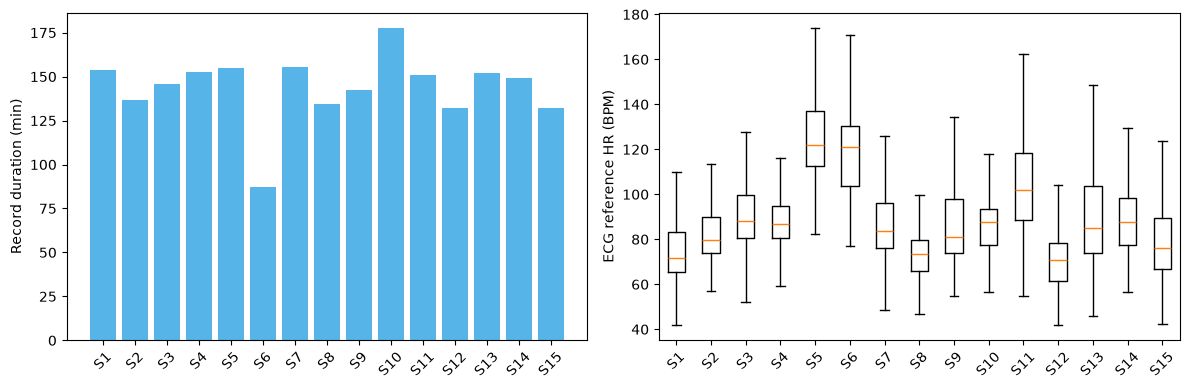

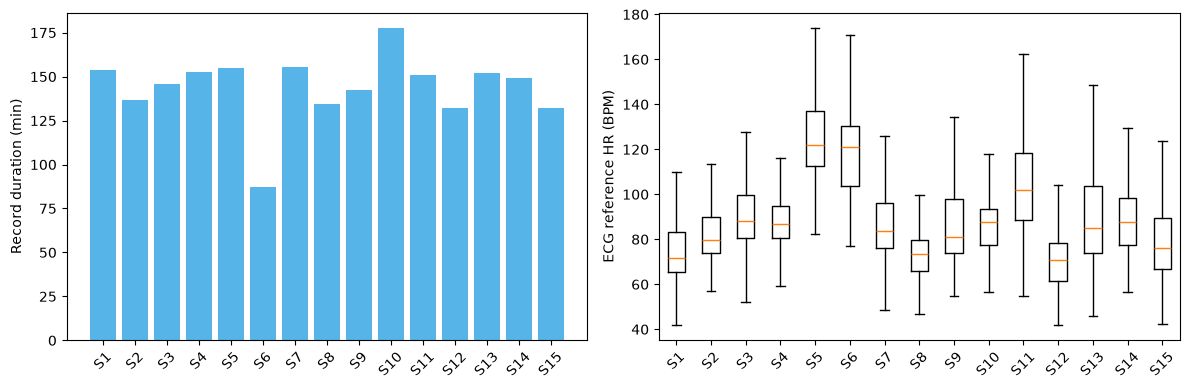

In [80]:
plot_subject_profiles(EDA_RUN['tables']['subject_quality'], CTX['manifest'])

In [81]:
def plot_activity_coverage(activity, subjects):
    import matplotlib.pyplot as plt
    matrix = activity.pivot(index="subject_id", columns="activity", values="duration_minutes").reindex(subjects)
    fig, ax = plt.subplots(figsize=(11, 5))
    image = ax.imshow(matrix.values, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(subjects)), subjects)
    fig.colorbar(image, ax=ax, label="Duration (min)")
    fig.tight_layout()
    return fig

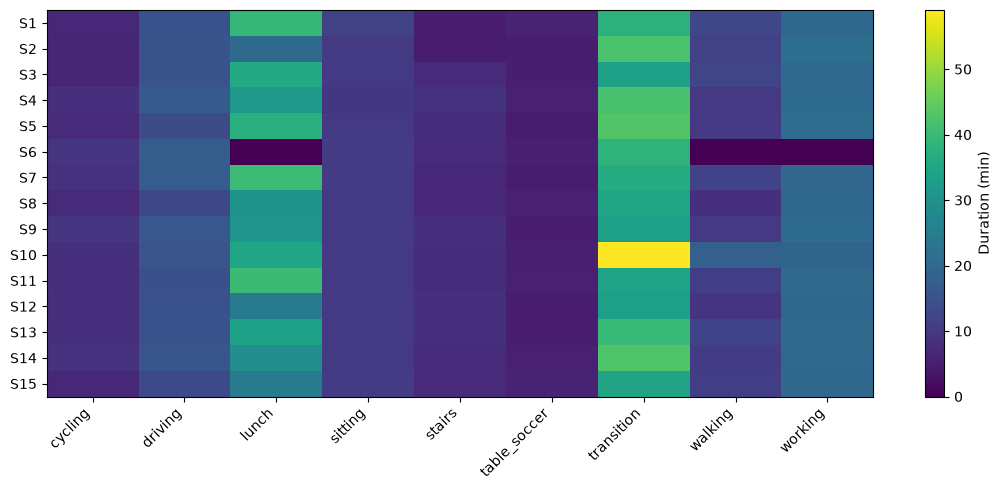

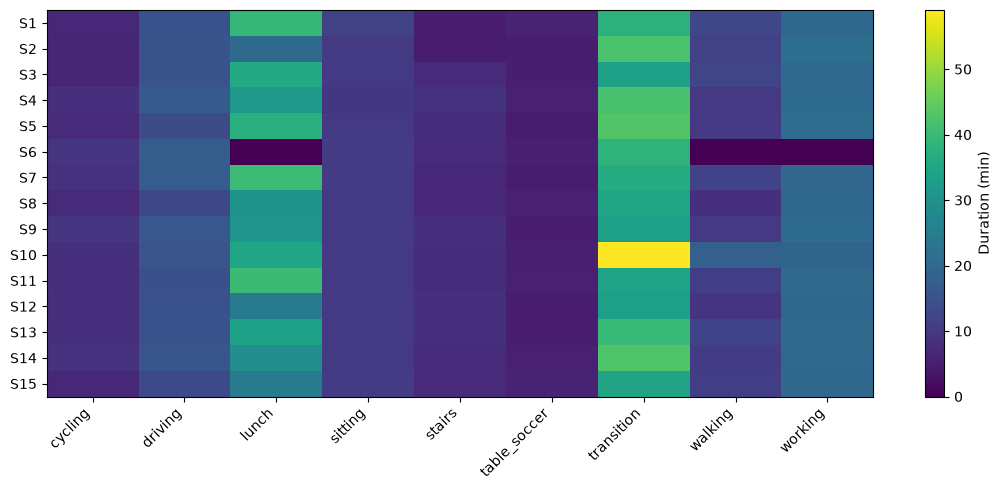

In [82]:
plot_activity_coverage(EDA_RUN['tables']['activity_duration'], SUBJECTS)

In [83]:
def plot_hr_and_motion(ctx, descriptors):
    import matplotlib.pyplot as plt
    frame = descriptors.iloc[::max(1, len(descriptors) // 4000)]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, style in zip(("train", "validation", "test"), ("-", "--", ":")):
        hr = ctx["manifest"].loc[(ctx["manifest"].split == name) & ctx["manifest"].eligible, "hr_ref_bpm"]
        axes[0].hist(hr, bins=35, histtype="step", linestyle=style, label=name)
    axes[0].set(xlabel="ECG HR (BPM)", ylabel="Windows per bin"); axes[0].legend()
    points = axes[1].scatter(frame.motion_rms_source_units, frame.hr_ref_bpm,
                             c=frame.activity_id, cmap="turbo", s=6, alpha=.55)
    axes[1].set(xlabel="ACC motion RMS (source units)", ylabel="ECG HR (BPM)")
    fig.colorbar(points, ax=axes[1], label="Activity code")
    fig.tight_layout()
    return fig

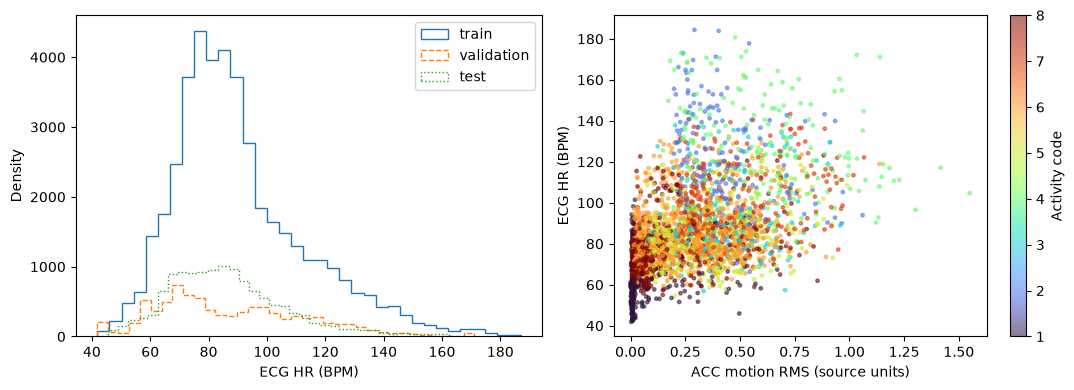

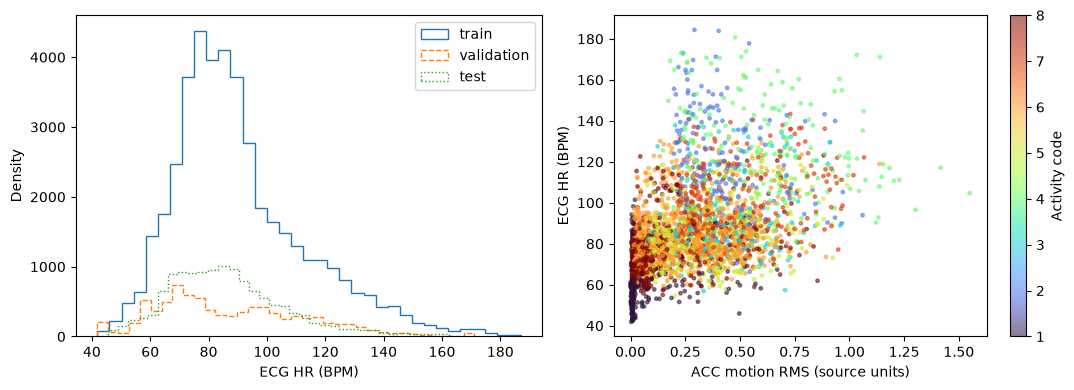

In [84]:
plot_hr_and_motion(CTX, EDA_RUN['tables']['window_descriptors'])

In [85]:
def plot_recorded_signals(ctx, subject):
    import matplotlib.pyplot as plt
    record = ctx["raw_records"][subject]
    arrays = cached_arrays(ctx, subject)
    candidates = ctx["manifest"].loc[(ctx["manifest"].subject_id == subject) & ctx["manifest"].eligible &
                                     (ctx["manifest"].activity_id == (1 if subject == "S1" else 7))]
    if candidates.empty: candidates = ctx["manifest"].loc[(ctx["manifest"].subject_id == subject) & ctx["manifest"].eligible]
    row = candidates.iloc[0]
    p0, p1, start = int(row.ppg_start_idx), int(row.ppg_end_idx), float(row.start_s)
    fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
    axes[0].plot(start + np.arange(512)/64, record.ppg64[2*p0:2*p1], color="#0072B2")
    axes[1].plot(start + np.arange(256)/32, arrays["ppg32"][p0:p1], color="#D55E00")
    for axis, color in zip(range(3), ("#0072B2", "#E69F00", "#009E73")):
        axes[2].plot(start + np.arange(256)/32, record.acc32[p0:p1, axis], color=color, label=f"ACC {axis}")
    for ax, label in zip(axes, ("Raw PPG · 64 Hz", "Filtered PPG · 32 Hz", "ACC · 32 Hz")): ax.set_ylabel(label)
    axes[2].set_xlabel("Time (s)"); axes[2].legend()
    fig.suptitle(f"{subject} · {row.activity_status} · ECG HR {row.hr_ref_bpm:.1f} BPM")
    fig.tight_layout()
    return fig

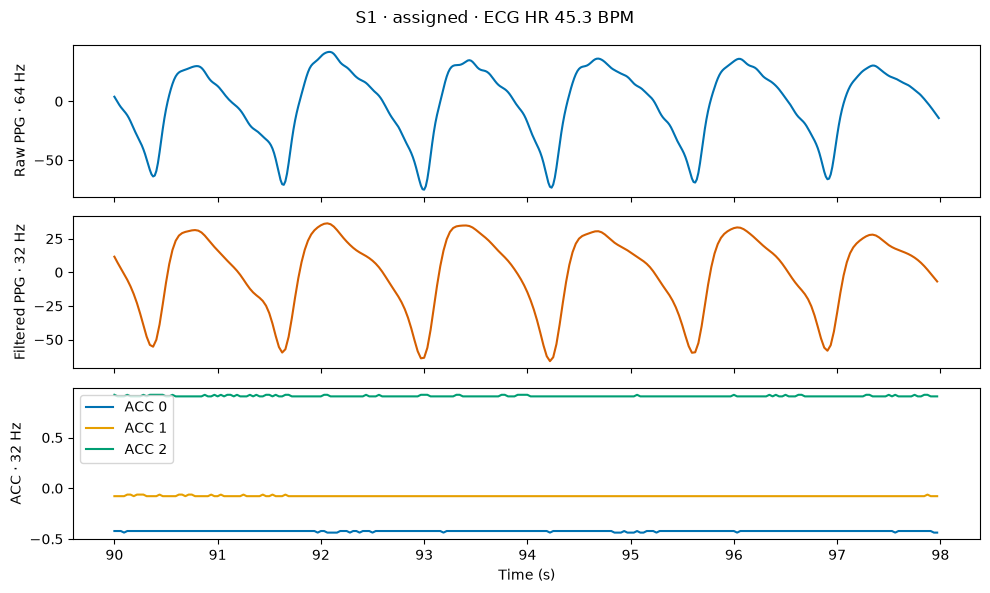

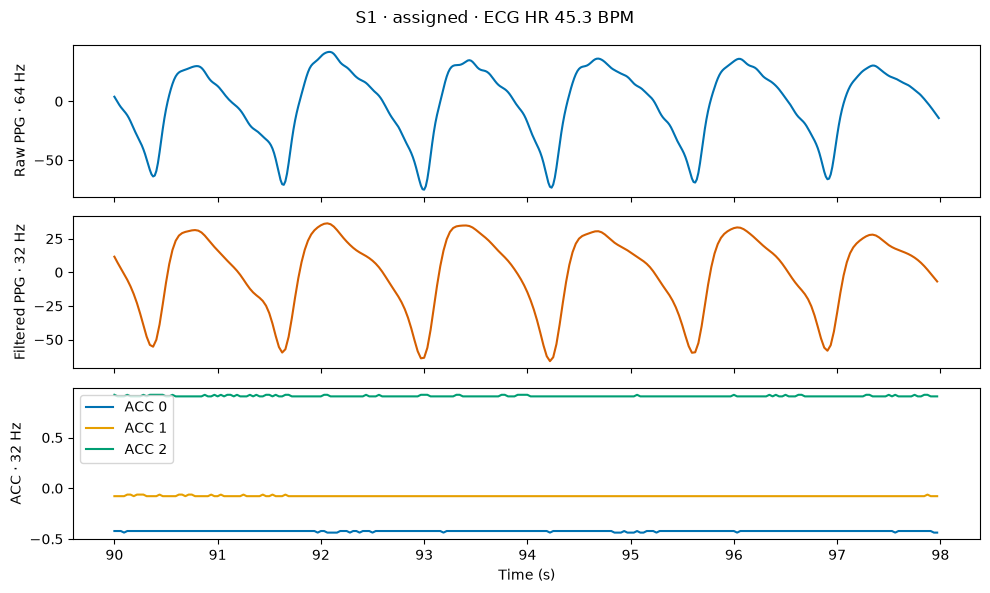

In [86]:
plot_recorded_signals(CTX, 'S1')

In [87]:
def plot_validation_signals(ctx):
    return plot_recorded_signals(ctx, "S11")

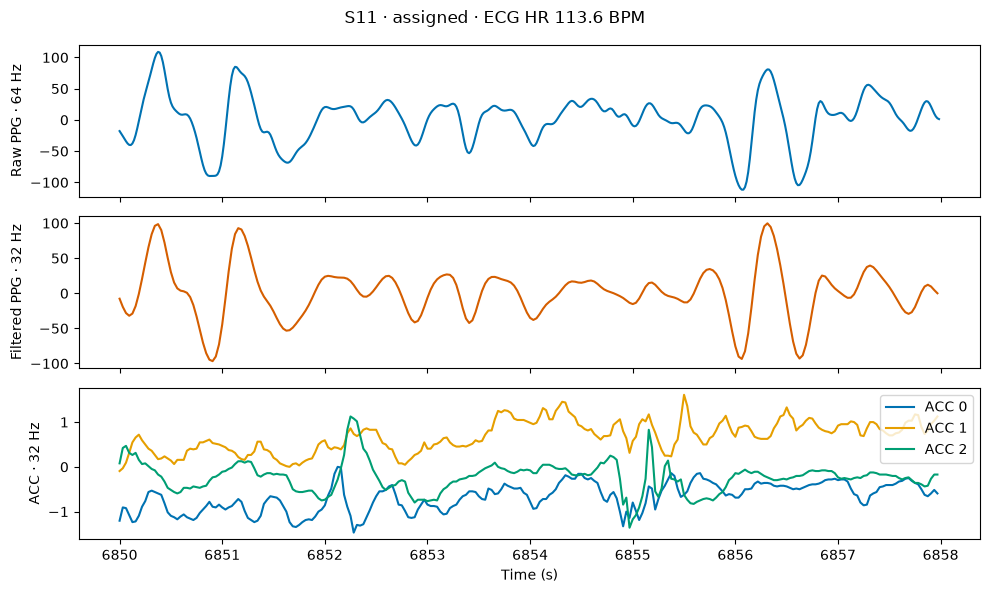

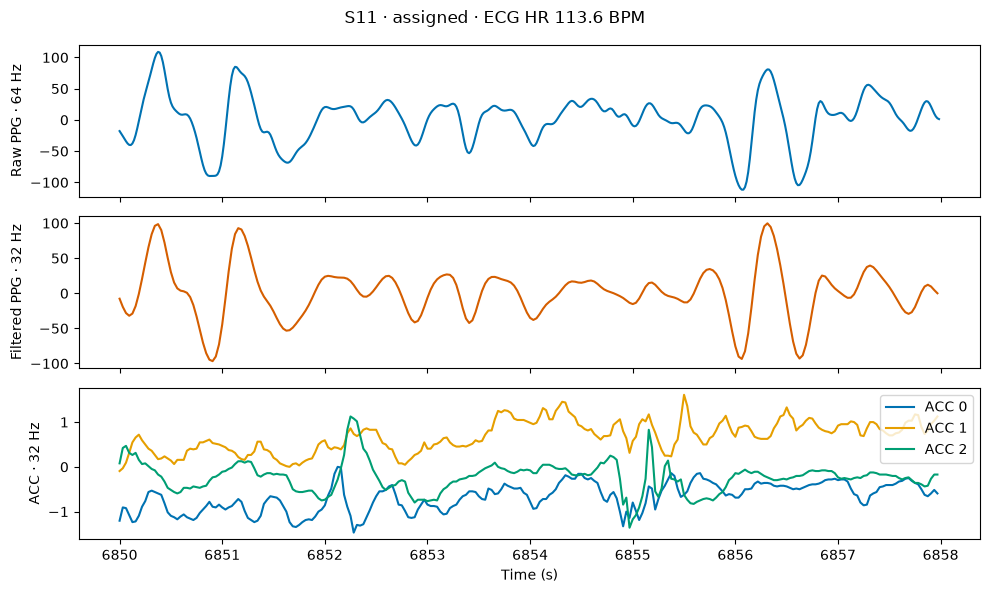

In [88]:
plot_validation_signals(CTX)

In [89]:
eda_train = EDA_RUN["tables"]["window_descriptors"].query("split == 'train'")
eda_columns = ["hr_ref_bpm", "motion_rms_source_units", "ppg_std_filtered", "spectral_entropy"]
display(eda_train[eda_columns].corr(method="spearman"))

,hr_ref_bpm,motion_rms_source_units,ppg_std_filtered,spectral_entropy
hr_ref_bpm,1.000000,0.471044,0.254596,0.254172
motion_rms_source_units,0.471044,1.000000,0.450270,0.515954
ppg_std_filtered,0.254596,0.450270,1.000000,0.253308
spectral_entropy,0.254172,0.515954,0.253308,1.000000


## 5. Đối chuẩn FFT và IBI

FFT thực hiện mean-centering, nhân cửa sổ Hann đối xứng và FFT 4096 điểm.
Đỉnh biên độ trong dải 0,6–3,5 Hz được chuyển thành HR bằng $HR=60f_{peak}$.
Zero-padding làm dày lưới tần số của phổ nhưng không bổ sung thông tin quan sát
ngoài cửa sổ 8 giây. E0 sử dụng PPG đã lọc, trước chuẩn hóa z-score.

IBI sử dụng `distance=round(0.33Fs)` và `prominence=0.3std`, với $Fs=32$ Hz
tại bước phát hiện đỉnh, tương ứng khoảng cách tối thiểu 11 mẫu.
Nếu có ít nhất hai đỉnh, $HR=60/\operatorname{mean}(IBI)$.
Pure IBI ghi coverage của các cửa sổ tính được; E1 full sử dụng median HR Train
làm dự phòng cho trường hợp thiếu đỉnh. Hai kết quả được lưu riêng cùng tập
con hợp lệ để phân biệt hiệu năng thuật toán và mức phủ dữ liệu.

Các thuật toán nhận tín hiệu PPG và tham số cố định; HR tham chiếu chỉ được
sử dụng sau dự đoán để tính sai số. Cửa sổ phẳng hoặc dự đoán sai lớn được giữ
trong manifest và các bảng coverage.


In [90]:
def fft_prediction(window, fs=32):
    """Hann, 4096 bins, amplitude peak in 0.6–3.5 Hz; flat windows retained."""
    window = np.asarray(window, dtype=np.float64)
    if window.ndim != 1 or not np.isfinite(window).all() or len(window) < 2 or fs <= 0:
        raise ValueError("FFT requires a complete finite signal")
    spectrum = np.abs(np.fft.rfft((window-window.mean()) *
                                sp_signal.windows.hann(len(window), sym=True), n=4096))
    frequencies = np.fft.rfftfreq(4096, d=1/fs)
    indices = np.flatnonzero((frequencies >= .6) & (frequencies <= 3.5))
    selected = indices[np.argmax(spectrum[indices])]
    return {"hr_pred_bpm": float(60*frequencies[selected]), "prediction_valid": True,
            "prediction_reason": "low_signal" if spectrum[indices].max() == 0 else "ok"}

In [91]:
def ibi_prediction(window, fs=32):
    """No reference information enters peak detection or IBI estimation."""
    window = np.asarray(window, dtype=np.float64)
    if window.ndim != 1 or not np.isfinite(window).all() or len(window) < 2 or fs <= 0:
        raise ValueError("IBI requires a complete finite signal")
    peaks, _ = sp_signal.find_peaks(window, distance=round(.33*fs),
                                    prominence=.3*window.std(ddof=0))
    valid = len(peaks) >= 2
    return {"hr_pred_bpm": float(60 / np.diff(peaks).mean() * fs) if valid else np.nan,
            "prediction_valid": valid, "prediction_reason": "ok" if valid else "insufficient_peaks",
            "peak_count": int(len(peaks))}

In [92]:
def _baseline_subject(ctx,subject,fallback):
    arrays=cached_arrays(ctx,subject)
    frame=ctx["manifest"].loc[ctx["manifest"].eligible&(ctx["manifest"].subject_id==subject)]
    fft_rows,ibi_rows,full_rows=[],[],[]
    for meta in frame.to_dict("records"):
        p0,p1=int(meta["ppg_start_idx"]),int(meta["ppg_end_idx"])
        window=arrays["ppg32"][p0:p1]
        fft=fft_prediction(window); ibi=ibi_prediction(window)
        full=dict(ibi,ibi_valid=ibi["prediction_valid"],used_fallback=not ibi["prediction_valid"],
                  prediction_valid=True)
        if full["used_fallback"]:
            full["hr_pred_bpm"]=fallback["hr_bpm"]
            full["prediction_reason"]="train_hr_median_fallback"
        fft_rows.append(dict(meta,**fft,ecode="E0"))
        ibi_rows.append(dict(meta,**ibi,ecode="E1_pure"))
        full_rows.append(dict(meta,**full,ecode="E1"))
    print(f"{subject}: {len(frame)} common FFT/IBI windows",flush=True)
    return fft_rows,ibi_rows,full_rows

In [93]:
def _baseline_save_method(ctx,run,name,rows):
    predictions=pd.DataFrame(rows)
    joined=join_predictions(ctx["manifest"],predictions,allow_invalid=name=="E1_pure")
    path=run.directory/f"{name}_predictions.csv"; predictions.to_csv(path,index=False)
    metrics={"all_subject_diagnostic":compute_metrics(joined,expected_subjects=list(SUBJECTS)),
             "splits":{split:compute_metrics(joined.loc[joined.split==split],
                        expected_subjects=list(subjects)) for split,subjects in SPLITS.items()}}
    metric_path=run.directory/f"{name}_metrics.json"; write_json(metric_path,metrics)
    record={"predictions":path.relative_to(ctx["root"]).as_posix(),
            "metrics":metric_path.relative_to(ctx["root"]).as_posix(),
            "predictions_sha256":sha256_file(path)}
    return record,{f"{name}_predictions":path,f"{name}_metrics":metric_path}

In [94]:
def _baseline_save_index(ctx,run,rows,fallback):
    methods={}; evidence={}
    for name,values in zip(("E0","E1_pure","E1"),rows):
        methods[name],files=_baseline_save_method(ctx,run,name,values)
        evidence.update(files)
    index={"passed":True,"gate":"G04_real_data","protocol":ctx["config"]["baseline"],
           "preprocess_hash":ctx["index"]["preprocess_hash"],
           "manifest_sha256":sha256_file(ctx["manifest_path"]),
           "run_id":run.record["run_id"],"methods":methods,"fallback":fallback}
    path=ctx["root"]/"results/baselines/index.json"; write_json(path,index)
    write_json(run.directory/"fallback.json",fallback)
    evidence["index"]=path
    return index,evidence

In [95]:
def baseline_stage(ctx):
    run=RunRecorder(ctx["root"],ctx["root"]/"results/baselines/runs",ctx["config"],
                    ecode="E0-E1",kind="final",inputs={"manifest":ctx["manifest_path"]})
    log_test_access(ctx,"DSP_baseline_diagnostic",detail={"run_id":run.record["run_id"],"selection":False})
    try:
        fallback=train_median_fallback(ctx["manifest"]); combined=([],[],[])
        for subject in SUBJECTS:
            for result,target in zip(_baseline_subject(ctx,subject,fallback),combined):
                target.extend(result)
        index,evidence=_baseline_save_index(ctx,run,combined,fallback)
        run.finish(evidence=evidence)
        log_test_access(ctx,"DSP_baseline_diagnostic",status="complete")
        return index
    except BaseException as error:
        run.finish(error=str(error))
        log_test_access(ctx,"DSP_baseline_diagnostic",status="failed",detail=str(error))
        raise

In [96]:
def _reference_value(table,domain,group):
    if domain=="test":
        selected=table["splits"]["test"]
        if group=="all": return selected["overall"]["macro_subject"]["mae_bpm"]
        activity=next(row for row in selected["by_activity"] if row["activity"]==group)
        return activity["macro_subject"]["mae_bpm"]
    selected=table["all_subject_diagnostic"]
    if group=="all": rows=selected["by_subject"]
    else: rows=next(row for row in selected["by_activity"] if row["activity"]==group)["by_subject"]
    return next(row for row in rows if row["subject_id"]=="S1")["mae_bpm"]

In [97]:
def _reference_comparison(ctx):
    index=read_json(ctx["root"]/"results/baselines/index.json")
    fft=read_json(ctx["root"]/index["methods"]["E0"]["metrics"])
    ibi=read_json(ctx["root"]/index["methods"]["E1_pure"]["metrics"])
    references=[("S1","FFT","all",11.68),("S1","IBI_pure","all",9.66),
        ("S1","FFT","sitting",3.67),("S1","FFT","stairs",32.42),
        ("test","FFT","all",12.71),("test","FFT","sitting",1.25),
        ("test","FFT","stairs",27.80),("test","FFT","walking",23.59)]
    rows=[]
    for domain,method,group,expected in references:
        actual=_reference_value(fft if method=="FFT" else ibi,domain,group)
        rows.append({"domain":domain,"method":method,"group":group,"reference_bpm":expected,
            "measured_final32_bpm":actual,"relative_deviation":abs(actual-expected)/expected if actual is not None else None,
            "same_protocol_verified":False,"reference_gate_passed":False})
    return rows

In [98]:
def review_benchmark(ctx):
    rows=_reference_comparison(ctx)
    pd.DataFrame(rows).to_csv(ctx["root"]/"results/baselines/benchmark_comparison.csv",index=False)
    report={"gate":"G05","passed":False,"status":"source_protocol_unresolved",
        "reason":"Old D01 code uses FFT-derived HR labels; exact benchmark protocol/mask/aggregation is not verified.",
        "comparison_scope":"Observed final32 numbers only; not a certified D01 reproduction",
        "threshold":.15,"preprocess_hash":ctx["index"]["preprocess_hash"],"comparison":rows,
        "baseline_index_sha256":sha256_file(ctx["root"]/"results/baselines/index.json"),
        "decision_file":"results/benchmark_source_decision.json"}
    write_json(ctx["root"]/"results/benchmark_review.json",report)
    return report

In [99]:
def require_training_gate(ctx):
    """Accept a verified reproduction or an explicit, recorded source decision."""
    report = read_json(ctx["root"]/"results/benchmark_review.json")
    if report["preprocess_hash"] != ctx["index"]["preprocess_hash"]:
        raise ValueError("G05 refers to a different preprocessing protocol")
    if report.get("passed") and report.get("same_protocol_verified"):
        return {"type": "verified_D01", "review_sha256": sha256_file(ctx["root"]/"results/benchmark_review.json")}
    path = ctx["root"]/"results/benchmark_source_decision.json"
    if not path.exists():
        raise RuntimeError("G05 unresolved: obtain an explicit source/protocol decision before pilot or long training")
    decision = read_json(path)
    if decision.get("authorized_by") != "user" or decision.get("decision") != "use_original_ecg_final32":
        raise ValueError("No valid user source decision")
    if decision.get("review_sha256") != sha256_file(ctx["root"]/"results/benchmark_review.json"):
        raise ValueError("Source decision does not cover the current review")
    if not decision.get("user_message") or decision.get("reference_verified") is not False:
        raise ValueError("Decision must preserve the unverified reference status")
    return {"type": "explicit_source_decision", "decision_sha256": sha256_file(path),
            "reference_verified": False}

In [100]:
BASELINE_RUN = run_stage("baseline")

S1: 4603 common FFT/IBI windows
S2: 4099 common FFT/IBI windows
S3: 4367 common FFT/IBI windows
S4: 4572 common FFT/IBI windows
S5: 4649 common FFT/IBI windows
S6: 2622 common FFT/IBI windows
S7: 4668 common FFT/IBI windows
S8: 4037 common FFT/IBI windows
S9: 4277 common FFT/IBI windows
S10: 5321 common FFT/IBI windows
S11: 4521 common FFT/IBI windows
S12: 3954 common FFT/IBI windows
S13: 4565 common FFT/IBI windows
S14: 4476 common FFT/IBI windows
S15: 3966 common FFT/IBI windows


In [101]:
G05_REVIEW = run_stage("benchmark_review")

In [102]:
SOURCE_DECISION = notebook_record_user_decision(CTX)

In [103]:
TRAINING_GATE = require_training_gate(CTX)

In [104]:
show_table("results/baselines/benchmark_comparison.csv", limit=20)

,domain,method,group,reference_bpm,measured_final32_bpm,relative_deviation,same_protocol_verified,reference_gate_passed
0,S1,FFT,all,11.68,11.136167,0.046561,False,False
1,S1,IBI_pure,all,9.66,8.830425,0.085877,False,False
2,S1,FFT,sitting,3.67,3.540405,0.035312,False,False
3,S1,FFT,stairs,32.42,31.698034,0.022269,False,False
4,test,FFT,all,12.71,11.191000,0.119512,False,False
5,test,FFT,sitting,1.25,1.089561,0.128352,False,False
6,test,FFT,stairs,27.80,26.013793,0.064252,False,False
7,test,FFT,walking,23.59,21.808485,0.075520,False,False


### 5.1. Khả năng đối chiếu với benchmark Đ01

Các mốc Đ01 được giữ dưới dạng số tham chiếu nội bộ. Rà soát nguồn giữa kỳ
cho thấy HR reference trong mã cũ được tạo từ FFT prediction cộng offset,
và IBI có bước điều chỉnh bằng reference. Những nguồn này không cung cấp
ground truth độc lập cho đánh giá cuối kỳ.

Thực nghiệm hiện tại sử dụng nhãn ECG gốc và giao thức final32 đã thống nhất.
Các giá trị baseline mới nằm trong khoảng sai lệch 15% của các mốc đối chiếu,
nhưng nguồn nhãn, mask và phép tổng hợp của benchmark cũ chưa được xác minh
cùng giao thức. Vì vậy bảng đối chiếu phản ánh mức gần nhau về số, chưa xác nhận
tái lập Đ01; mức cải thiện học sâu được tính so với baseline final32 thực chạy.


In [105]:
show_json("results/benchmark_review.json")

{'baseline_index_sha256': '27e455e598aa96d91e1d160e0a4b62c017014c45e4148d4e2d2f1561abd7d671',
 'comparison': [{'domain': 'S1',
   'group': 'all',
   'measured_final32_bpm': 11.136167395690197,
   'method': 'FFT',
   'reference_bpm': 11.68,
   'reference_gate_passed': False,
   'relative_deviation': 0.04656101064296252,
   'same_protocol_verified': False},
  {'domain': 'S1',
   'group': 'all',
   'measured_final32_bpm': 8.830424832919004,
   'method': 'IBI_pure',
   'reference_bpm': 9.66,
   'reference_gate_passed': False,
   'relative_deviation': 0.08587734648871598,
   'same_protocol_verified': False},
  {'domain': 'S1',
   'group': 'sitting',
   'measured_final32_bpm': 3.5404045113559692,
   'method': 'FFT',
   'reference_bpm': 3.67,
   'reference_gate_passed': False,
   'relative_deviation': 0.03531212224632989,
   'same_protocol_verified': False},
  {'domain': 'S1',
   'group': 'stairs',
   'measured_final32_bpm': 31.69803378825637,
   'method': 'FFT',
   'reference_bpm': 32.42,
  

In [106]:
show_json("results/benchmark_source_decision.json")

{'authorized_by': 'user',
 'decision': 'use_original_ecg_final32',
 'reference_verified': False,
 'review_sha256': 'd538407b4f8ff48aff5591d5f2edd93758f1e79cac1bf6469817bf36d2b56756',
 'schema_version': 1,
 'scope': 'Use original ECG-derived HR labels and the final-project 32 Hz protocol; retain D01 benchmark as unverified.',
 'user_message': 'Chốt dùng ECG gốc và giao thức cuối kỳ để train'}

In [107]:
baseline_rows = [{"method": e, **read_json(PROJECT_DIR / r["metrics"])["splits"]["test"]["overall"]["macro_subject"]}
                 for e, r in BASELINE_RUN["methods"].items()]
display(pd.DataFrame(baseline_rows))

,method,error_gt_10_percent,mae_bpm,n_subjects_with_data,rmse_bpm
0,E0,26.708989,11.191000,3,20.698439
1,E1_pure,23.553093,6.970467,3,10.988358
2,E1,23.553093,6.970467,3,10.988358


## 6. Kiến trúc mạng tích chập giãn 1D

Mô hình triển khai biến thể mạng thời gian nhẹ trong đề cương, gồm ba Conv1D
với dilation 1/2/4 và padding đối xứng 3/4/4. Đây là mạng xử lý theo cửa sổ,
không có tính nhân quả theo từng thời điểm của một TCN streaming chuẩn.

| Khối | Kernel / dilation / padding | Tensor E3 |
|---|---|---|
| Input | PPG + ACCx/y/z | (B,4,256) |
| Conv1 + BN + ReLU | 7 / 1 / 3 | (B,32,256) |
| MaxPool1 | k=2, stride=2 | (B,32,128) |
| Conv2 + BN + ReLU | 5 / 2 / 4 | (B,64,128) |
| MaxPool2 | k=2, stride=2 | (B,64,64) |
| Conv3 + BN + ReLU | 3 / 4 / 4 | (B,64,64) |
| GAP + flatten | Tổng hợp chiều thời gian | (B,64) |
| Linear + ReLU | 64→32 | (B,32) |
| Linear | 32→1 | (B,1), BPM |

Conv sử dụng `bias=False`; BN có tham số affine và Linear có bias.
E2 chỉ thay số kênh đầu vào thành một kênh PPG, giữ nguyên backbone và head.
Quant/DeQuant là identity trong FP32 và tạo biên chuyển dtype sau PTQ.


In [108]:
def build_network(input_channels=4):
    """Three dilated Conv blocks, symmetric padding, GAP and a BPM regression head."""
    class NotebookWindowNetwork(nn.Module):
        def __init__(self):
            super().__init__()
            if input_channels not in (1,4): raise ValueError("Use PPG-only or PPG+ACC")
            self.quant=QuantStub()
            self.conv1=nn.Conv1d(input_channels,32,7,padding=3,bias=False)
            self.bn1=nn.BatchNorm1d(32); self.relu1=nn.ReLU(); self.pool1=nn.MaxPool1d(2,2)
            self.conv2=nn.Conv1d(32,64,5,dilation=2,padding=4,bias=False)
            self.bn2=nn.BatchNorm1d(64); self.relu2=nn.ReLU(); self.pool2=nn.MaxPool1d(2,2)
            self.conv3=nn.Conv1d(64,64,3,dilation=4,padding=4,bias=False)
            self.bn3=nn.BatchNorm1d(64); self.relu3=nn.ReLU(); self.gap=nn.AdaptiveAvgPool1d(1)
            self.fc1=nn.Linear(64,32); self.relu4=nn.ReLU(); self.fc2=nn.Linear(32,1)
            self.dequant=DeQuantStub()
        def forward(self,x):
            x=self.quant(x)
            x=self.pool1(self.relu1(self.bn1(self.conv1(x))))
            x=self.pool2(self.relu2(self.bn2(self.conv2(x))))
            x=self.relu3(self.bn3(self.conv3(x)))
            x=self.gap(x).flatten(1)
            return self.dequant(self.fc2(self.relu4(self.fc1(x))))
        def fuse_for_inference(self):
            if self.training: raise RuntimeError("Fusion requires eval")
            fuse_modules(self,[["conv1","bn1","relu1"],["conv2","bn2","relu2"],
                         ["conv3","bn3","relu3"],["fc1","relu4"]],inplace=True)
    return NotebookWindowNetwork()

In [109]:
model_rows = []
for channels in (1, 4):
    net = build_network(channels).eval()
    model_rows.append({"input_channels": channels, "parameters": sum(p.numel() for p in net.parameters()), "output": tuple(net(torch.zeros(1, channels, 256)).shape)})
display(pd.DataFrame(model_rows))

,input_channels,parameters,output
0,1,25185,"(1, 1)"
1,4,25857,"(1, 1)"


### 6.1. Cơ chế học đặc trưng và hồi quy HR

Mạng nhận waveform PPG/ACC trong miền thời gian và hồi quy trực tiếp một BPM.
Dilation mở rộng ngữ cảnh cục bộ mà không tăng số phần tử kernel; hai MaxPool
giảm chiều thời gian, GAP tổng hợp đặc trưng toàn cửa sổ và head thực hiện hồi quy.
Dung hợp sớm cho phép mô hình học quan hệ giữa PPG và biến thiên chuyển động.
Giá trị bổ trợ của ACC được đánh giá bằng đối chứng E2/E3, thay vì giả định trước
rằng ACC luôn cải thiện dự đoán hoặc tạo lại PPG sạch.

Hàm mất mát L1 trên các cửa sổ Train được xác định bởi:

$$\mathcal L_{L1}(\theta)=\frac{1}{N_{Train}}\sum_{i=1}^{N_{Train}}|f_\theta(x_i)-HR_i|.$$

Sơ đồ khối và bảng kiểm tra tensor thể hiện luồng Input → Backbone → GAP →
Regression Head. Với E3, mạng có **25.857 tham số**, **2.328.608 MAC Conv/Linear**
mỗi cửa sổ và trường tiếp nhận cục bộ **58 mẫu**, tương đương **1,8125 giây**.
GAP tiếp tục tổng hợp các vị trí đặc trưng trên toàn cửa sổ 8 giây.


In [110]:
MODEL_BLOCKS = [("PPG + ACC", "B × 4 × 256"), ("Conv1 / BN / ReLU / Pool", "B × 32 × 128"),
                ("Conv2 / BN / ReLU / Pool", "B × 64 × 64"), ("Conv3 / BN / ReLU", "B × 64 × 64"),
                ("GAP / flatten", "B × 64"), ("Linear / ReLU / Linear", "B × 32 → B × 1 BPM")]
MODEL_COLORS = ["#56B4E9", "#009E73", "#009E73", "#009E73", "#E69F00", "#CC79A7"]
FIGURE_DIR = PROJECT_DIR / "results/report"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


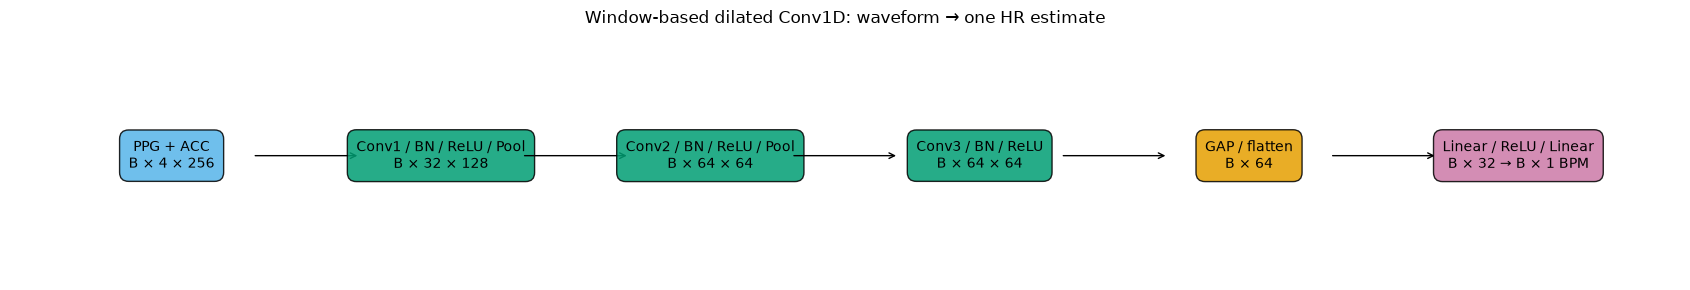

In [111]:
fig, ax = plt.subplots(figsize=(17, 3))
for i, (label, shape) in enumerate(MODEL_BLOCKS):
    ax.text(i, .5, label + "\n" + shape, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=.65", facecolor=MODEL_COLORS[i], alpha=.85))
    if i < len(MODEL_BLOCKS)-1: ax.annotate("", xy=(i+.7, .5), xytext=(i+.3, .5), arrowprops=dict(arrowstyle="->"))
ax.set(xlim=(-.6, 5.6), ylim=(0, 1), title="Window-based dilated Conv1D: waveform → one HR estimate"); ax.axis("off")
fig.tight_layout(); fig.savefig(FIGURE_DIR / "model_block_diagram.png", dpi=160); plt.show()


In [112]:
def describe_window_network(channels):
    model = build_network(channels).eval()
    rows, handles = [], []
    def observe(module, _inputs, output):
        mac = output.shape[-1]*module.weight.numel() if isinstance(module, nn.Conv1d) else (
              module.weight.numel() if isinstance(module, nn.Linear) else 0)
        rows.append({"layer": type(module).__name__, "tensor": tuple(output.shape), "Conv_Linear_MAC": mac})
    for module in model.modules():
        if isinstance(module, (nn.Conv1d, nn.MaxPool1d, nn.AdaptiveAvgPool1d, nn.Linear)):
            handles.append(module.register_forward_hook(observe))
    with torch.inference_mode(): model(torch.zeros(1, channels, 256))
    for handle in handles: handle.remove()
    rf, jump = 1, 1
    for k, d, stride in [(7,1,1), (2,1,2), (5,2,1), (2,1,2), (3,4,1)]:
        rf += (k-1)*d*jump; jump *= stride
    stats = {"channels": channels, "parameters": sum(p.numel() for p in model.parameters()),
             "Conv_Linear_MAC": sum(r["Conv_Linear_MAC"] for r in rows), "local_RF_samples": rf,
             "local_RF_seconds": rf/32, "GAP_window_seconds": 8}
    return stats, pd.DataFrame(rows)


In [113]:
MODEL_STRUCTURE = [describe_window_network(channels) for channels in (1, 4)]
display(pd.DataFrame([stats for stats, _ in MODEL_STRUCTURE]))
display(MODEL_STRUCTURE[1][1])


,channels,parameters,Conv_Linear_MAC,local_RF_samples,local_RF_seconds,GAP_window_seconds
0,1,25185,2156576,58,1.8125,8
1,4,25857,2328608,58,1.8125,8


,layer,tensor,Conv_Linear_MAC
0,Conv1d,"(1, 32, 256)",229376
1,MaxPool1d,"(1, 32, 128)",0
2,Conv1d,"(1, 64, 128)",1310720
3,MaxPool1d,"(1, 64, 64)",0
4,Conv1d,"(1, 64, 64)",786432
5,AdaptiveAvgPool1d,"(1, 64, 1)",0
6,Linear,"(1, 32)",2048
7,Linear,"(1, 1)",32


Kiểm tra tensor zero xác minh kích thước đầu ra, số tham số và MAC của kiến trúc;
accuracy được xác định riêng trên dữ liệu thật. MAC chỉ tính Conv/Linear, chưa bao gồm
BN, activation, pooling, GAP và DSP. Đây là chỉ số cấu trúc, khác với latency, RAM
và năng lượng đo trên một nền tảng thực thi cụ thể.


## 7. Huấn luyện và lựa chọn checkpoint

E2/E3 được tối ưu bằng AdamW, learning rate **1e−3**, weight decay **1e−4**,
L1 loss theo BPM và batch size **64**. Ngân sách tối đa là **80 epoch**, early
stopping patience **10**, không scheduler và không bỏ batch cuối.
Checkpoint được chọn bằng **Validation MAE macro theo người**; khi hai epoch
có cùng điểm, checkpoint sớm hơn được giữ. Tensor dự đoán và nhãn cùng dạng `(B,1)`.

Thực nghiệm sử dụng seed **42/123/999** cho Python, NumPy, PyTorch và thứ tự
shuffle Train. RNG, optimizer, epoch, lịch sử và checkpoint được lưu để truy vết
và phục hồi phiên huấn luyện. Các tensor Train/Validation được chuẩn bị theo
cùng manifest và giữ trong VRAM; AMP và TF32 không được sử dụng.

Pilot seed42 kiểm tra vòng Train/Validation trước sáu phiên đầy đủ.
E2 và E3 có cùng ngân sách, tiêu chí chọn checkpoint và giao thức dữ liệu.
Các đường loss/Validation và epoch được chọn cung cấp bằng chứng cho quá trình
học, trong khi Test được dành cho bộ cấu hình cuối đã khóa.


In [114]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.allow_tf32=False
    torch.backends.cuda.matmul.allow_tf32=False
    generator=torch.Generator(device="cpu"); generator.manual_seed(seed)
    return generator

In [115]:
def accelerator_info():
    info={"python":platform.python_version(),"torch":torch.__version__,"cuda_available":torch.cuda.is_available(),
          "torch_cuda_version":torch.version.cuda,"quantized_engines":list(torch.backends.quantized.supported_engines)}
    if torch.cuda.is_available():
        free,total=torch.cuda.mem_get_info()
        info.update(gpu=torch.cuda.get_device_name(0),free_vram_bytes=free,total_vram_bytes=total)
    return info

In [116]:
def materialize_split(ctx, split, device="cpu"):
    """Vectorized population z-score, preserving exactly the frozen manifest rows."""
    frame=ctx["manifest"].loc[ctx["manifest"].eligible &
            ((ctx["manifest"].split==split) if split!="all" else True)].reset_index(drop=True)
    if not len(frame): raise ValueError("No eligible windows")
    features=np.empty((len(frame),4,256),dtype=np.float32)
    offsets=np.arange(256)
    for subject,group in frame.groupby("subject_id",sort=False):
        arrays=cached_arrays(ctx,subject)
        indices=group.ppg_start_idx.to_numpy(dtype=np.int64)[:,None]+offsets
        ppg=arrays["ppg32"][indices]
        denominator=np.maximum(ppg.std(axis=1,ddof=0,keepdims=True),ctx["config"]["signal"]["normalization_epsilon"])
        ppg=((ppg-ppg.mean(axis=1,keepdims=True))/denominator).astype(np.float32)
        positions=group.index.to_numpy()
        features[positions,0,:]=ppg
        features[positions,1:,:]=arrays["acc32_normalized"][indices].transpose(0,2,1)
    target=frame.hr_ref_bpm.to_numpy(dtype=np.float32)[:,None]
    if not np.isfinite(features).all() or not np.isfinite(target).all(): raise ValueError("Non-finite tensors")
    return torch.from_numpy(features).to(device),torch.from_numpy(target).to(device),frame

In [117]:
def predict_tensor(model, features, batch_size=256):
    model.eval(); values=[]
    with torch.inference_mode():
        for begin in range(0,len(features),batch_size):
            prediction=model(features[begin:begin+batch_size])
            if prediction.shape!=(min(batch_size,len(features)-begin),1):
                raise ValueError("Expected (B,1), including B=1")
            values.append(prediction[:,0].detach().cpu().numpy())
    result=np.concatenate(values).astype(np.float64)
    if not np.isfinite(result).all(): raise ValueError("Non-finite network output")
    return result

In [118]:
def prediction_frame(frame, values, ecode, seed):
    if len(frame)!=len(values): raise ValueError("Missing prediction rows")
    result=frame.copy()
    result["hr_pred_bpm"]=values; result["prediction_valid"]=True
    result["prediction_reason"]="ok"; result["ecode"]=ecode; result["seed"]=seed
    return join_predictions(frame,result)

In [119]:
def train_epoch(model,optimizer,features,targets,generator,batch_size=64):
    model.train(); total=0.; n=0
    permutation=torch.randperm(len(features),generator=generator)
    for begin in range(0,len(features),batch_size):
        index=permutation[begin:begin+batch_size].to(features.device)
        x,y=features[index],targets[index]
        optimizer.zero_grad(set_to_none=True)
        prediction=model(x)
        if prediction.shape!=y.shape or y.ndim!=2 or y.shape[1]!=1:
            raise ValueError("Target broadcasting is forbidden")
        loss=nn.functional.l1_loss(prediction,y)
        if not torch.isfinite(loss): raise ValueError("Non-finite training loss")
        loss.backward(); optimizer.step()
        total+=float(loss.detach())*len(index); n+=len(index)
    return total/n

In [120]:
def capture_rng(generator):
    numpy_state=np.random.get_state()
    return {"python":random.getstate(),"numpy":numpy_state,
            "torch":torch.get_rng_state(),"cuda":torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
            "permutation":generator.get_state()}

In [121]:
def restore_rng(state,generator):
    random.setstate(state["python"]); np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if state["cuda"] and torch.cuda.is_available(): torch.cuda.set_rng_state_all(state["cuda"])
    generator.set_state(state["permutation"])

In [122]:
def save_inference_model(model,path,*,input_channels,quantized,backend="onednn"):
    """Same model-only state_dict envelope for FP32 and INT8, no optimizer state."""
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    packet={"format":"ppg-window-state-v1","input_channels":input_channels,
            "quantized":bool(quantized),"backend":backend,"state_dict":model.cpu().state_dict()}
    torch.save(packet,path)
    return {"path":path,"sha256":sha256_file(path),"bytes":path.stat().st_size,"format":packet["format"]}

In [123]:
def load_inference_model(path,expected_sha256=None):
    path=Path(path)
    if expected_sha256 is not None and sha256_file(path)!=expected_sha256:
        raise ValueError("Artifact checksum mismatch")
    packet=torch.load(path,map_location="cpu",weights_only=True)
    if packet.get("format")!="ppg-window-state-v1": raise ValueError("Unknown artifact format")
    model=build_network(packet["input_channels"]).eval()
    if packet["quantized"]:
        backend=packet["backend"]
        if backend not in torch.backends.quantized.supported_engines: raise ValueError("Backend unavailable")
        torch.backends.quantized.engine=backend; model.fuse_for_inference()
        model.qconfig=get_default_qconfig(backend)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            prepare(model,inplace=True); convert(model,inplace=True)
        # This reconstructs operator topology only; all calibrated qparams are loaded below.
    model.load_state_dict(packet["state_dict"],strict=True)
    return model.eval()

In [124]:
def accelerator_smoke(ctx,batches=10):
    if not torch.cuda.is_available(): raise RuntimeError("CUDA unavailable; use Colab GPU")
    generator=seed_everything(42)
    x,y,frame=materialize_split(ctx,"train","cuda")
    model=build_network(4).cuda()
    optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.0001)
    torch.cuda.synchronize(); start=time.perf_counter()
    n=min(len(x),batches*64)
    loss=train_epoch(model,optimizer,x[:n],y[:n],generator,64)
    torch.cuda.synchronize()
    result={"passed":True,"scope":"CUDA feasibility on real Train only, not final training/MAE",
            "n_train_windows":n,"batches":math.ceil(n/64),"loss_bpm":loss,
            "wall_seconds":time.perf_counter()-start,"runtime":accelerator_info(),
            "peak_cuda_memory_bytes":torch.cuda.max_memory_allocated(),
            "preprocess_hash":ctx["index"]["preprocess_hash"]}
    write_json(ctx["root"]/"results/accelerator_smoke.json",result)
    del model,optimizer,x,y; torch.cuda.empty_cache()
    return result

In [125]:
def _train_initialize(ctx,ecode,seed,data,kind,budget):
    channels=1 if ecode=="E2" else 4
    generator=seed_everything(seed)
    model=build_network(channels).to(data[0].device)
    policy=ctx["config"]["training"]
    optimizer=torch.optim.AdamW(model.parameters(),lr=policy["learning_rate"],
                               weight_decay=policy["weight_decay"])
    return {"model":model,"optimizer":optimizer,"generator":generator,
            "ecode":ecode,"seed":seed,"kind":kind,"budget":budget,"channels":channels,
            "history":[],"best":float("inf"),"best_epoch":0,"stale":0,
            "start_epoch":1,"best_state":None,"config_sha256":hash_object(ctx["config"]),
            "preprocess_hash":ctx["index"]["preprocess_hash"]}

In [126]:
def _train_resume(ctx,state,parent,expected_hash):
    if not parent.resolve().is_relative_to(ctx["root"].resolve()): raise ValueError("Resume checkpoint outside workspace")
    if sha256_file(parent)!=expected_hash: raise ValueError("Resume checkpoint changed")
    saved=torch.load(parent,map_location="cpu",weights_only=False)
    runtime=accelerator_info()
    if any(saved.get("runtime",{}).get(k)!=runtime[k] for k in ("python","torch","gpu")):
        raise ValueError("Resume runtime changed; start a fresh execution")
    for key in ("ecode","seed","kind","budget","config_sha256","preprocess_hash"):
        if saved[key]!=state[key]: raise ValueError(f"Resume mismatch: {key}")
    state["model"].load_state_dict(saved["model"])
    state["optimizer"].load_state_dict(saved["optimizer"])
    restore_rng(saved["rng"],state["generator"])
    for key in ("best","best_epoch","stale","history","best_state"): state[key]=saved[key]
    state["start_epoch"]=saved["epoch"]+1

In [127]:
def _train_validation(ctx,state,val_data):
    x,_,frame=val_data
    values=predict_tensor(state["model"],x[:,:state["channels"],:])
    joined=prediction_frame(frame,values,state["ecode"],state["seed"])
    metrics=compute_metrics(joined,expected_subjects=list(SPLITS["validation"]))
    score=metrics["overall"]["macro_subject"]["mae_bpm"]
    if score is None or not math.isfinite(score): raise ValueError("Invalid Validation macro")
    return score,metrics["overall"]["pooled_window"]["mae_bpm"]

In [128]:
def _train_update_best(state,score,epoch):
    improved=score<state["best"]
    if improved:
        state["best"]=score
        state["best_epoch"]=epoch
        state["stale"]=0
        state["best_state"]={k:v.detach().cpu().clone() for k,v in state["model"].state_dict().items()}
    else:
        state["stale"]+=1
    return improved

In [129]:
def _train_save_resume(ctx,state,run,pointer,epoch):
    saved={key:state[key] for key in ("best","best_epoch","stale","best_state","history",
           "config_sha256","preprocess_hash","ecode","seed","kind","budget")}
    saved.update(model=state["model"].state_dict(),optimizer=state["optimizer"].state_dict(),
                 rng=capture_rng(state["generator"]),epoch=epoch,runtime=accelerator_info())
    checkpoint=run.directory/"last.pt"; temporary=run.directory/"last.pt.tmp"
    torch.save(saved,temporary); temporary.replace(checkpoint)
    pd.DataFrame(state["history"]).to_csv(run.directory/"history.csv",index=False)
    write_json(pointer,{"checkpoint":checkpoint.relative_to(ctx["root"]).as_posix(),
                        "sha256":sha256_file(checkpoint)})

In [130]:
def _train_fit(ctx,state,run,pointer,train_data,val_data):
    x,y,_=train_data; policy=ctx["config"]["training"]
    if state["stale"]>=policy["patience"]: return
    for epoch in range(state["start_epoch"],state["budget"]+1):
        start=time.perf_counter()
        loss=train_epoch(state["model"],state["optimizer"],x[:,:state["channels"],:],y,
                         state["generator"],policy["batch_size"])
        score,pooled=_train_validation(ctx,state,val_data)
        improved=_train_update_best(state,score,epoch)
        state["history"].append({"epoch":epoch,"train_l1_bpm":loss,
            "val_macro_mae_bpm":score,"val_pooled_mae_bpm":pooled,"selected":improved,
            "wall_seconds":time.perf_counter()-start})
        _train_save_resume(ctx,state,run,pointer,epoch)
        print(f"{state['kind']} {state['ecode']} seed={state['seed']} epoch={epoch}: "
              f"Train={loss:.3f}, Val={score:.3f}, best={state['best']:.3f}",flush=True)
        if state["stale"]>=policy["patience"]: break

In [131]:
def _train_export_selected(ctx,state,run,val_data):
    if state["best_state"] is None: raise ValueError("No selected checkpoint")
    model=state["model"].cpu()
    model.load_state_dict(state["best_state"])
    path=run.directory/"model_fp32.pt"
    saved=save_inference_model(model,path,input_channels=state["channels"],quantized=False)
    reloaded=load_inference_model(path,saved["sha256"])
    x,_,frame=val_data; x=x[:,:state["channels"],:].cpu()
    before=predict_tensor(model,x); after=predict_tensor(reloaded,x)
    np.testing.assert_allclose(before,after,atol=0,rtol=0)
    predictions=prediction_frame(frame,after,state["ecode"],state["seed"])
    predictions.to_csv(run.directory/"validation_predictions.csv",index=False)
    metrics=compute_metrics(predictions,expected_subjects=list(SPLITS["validation"]))
    write_json(run.directory/"validation_metrics.json",metrics)
    return saved,metrics

In [132]:
def _train_finish(ctx,state,run,saved,metrics,decision):
    result={key:state[key] for key in ("ecode","seed","kind","best_epoch","preprocess_hash","config_sha256")}
    result.update(passed=True,n_epochs=len(state["history"]),budget_epochs=state["budget"],
        selection="validation_macro_subject_mae",decision=decision,
        val_macro_mae_bpm=metrics["overall"]["macro_subject"]["mae_bpm"],
        artifact=saved["path"].relative_to(ctx["root"]).as_posix(),
        artifact_sha256=saved["sha256"],artifact_bytes=saved["bytes"],
        history=(run.directory/"history.csv").relative_to(ctx["root"]).as_posix(),
        validation_predictions=(run.directory/"validation_predictions.csv").relative_to(ctx["root"]).as_posix(),
        runtime=accelerator_info(),run_id=run.record["run_id"])
    write_json(run.directory/"checks.json",result)
    names=("history.csv","last.pt","model_fp32.pt","validation_predictions.csv","validation_metrics.json","checks.json")
    run.finish(evidence={name:run.directory/name for name in names})
    return result

In [133]:
def _train_load_registry(ctx,kind):
    path=ctx["root"]/("results/training_index.json" if kind=="final" else "results/pilot_index.json")
    index=read_json(path) if path.exists() else {"schema_version":1,"kind":kind,"runs":{}}
    for key,expected in (("preprocess_hash",ctx["index"]["preprocess_hash"]),("config_sha256",hash_object(ctx["config"]))):
        if index.get(key,expected)!=expected: raise ValueError("Training registry belongs to another protocol")
    return path,index

In [134]:
def training_record_matches(ctx,previous,experiment,seed,kind):
    if not previous or not previous.get("passed"): return False
    expected={"ecode":experiment,"seed":seed,"kind":kind,
        "config_sha256":hash_object(ctx["config"]),"preprocess_hash":ctx["index"]["preprocess_hash"]}
    if any(previous.get(k)!=v for k,v in expected.items()): return False
    current=accelerator_info(); runtime=previous.get("runtime",{})
    if any(runtime.get(k)!=current[k] for k in ("python","torch")): return False
    artifact=(ctx["root"]/previous.get("artifact","")).resolve()
    return (artifact.is_relative_to(ctx["root"].resolve()) and artifact.is_file()
        and artifact.stat().st_size==previous.get("artifact_bytes")
        and sha256_file(artifact)==previous.get("artifact_sha256"))


In [135]:
def training_registry_complete(ctx,index,kind):
    expected={f"{e}_{s}" for e in ("E2","E3") for s in (42,123,999)}
    if kind!="final" or set(index["runs"])!=expected: return False
    return all(training_record_matches(ctx,index["runs"][f"{e}_{s}"],e,s,kind)
        for e in ("E2","E3") for s in (42,123,999))


In [136]:
def _train_run_registry(ctx,kind,experiments,seeds,train_data,val_data,resume):
    require_unlocked(ctx["root"])
    path,index=_train_load_registry(ctx,kind)
    if not resume:
        index={"schema_version":1,"kind":kind,"runs":{},"passed":False,
               "preprocess_hash":ctx["index"]["preprocess_hash"],
               "config_sha256":hash_object(ctx["config"])}
        write_json(path,index)
    for experiment in experiments:
        for seed in seeds:
            key=f"{experiment}_{seed}"; previous=index["runs"].get(key)
            if resume and training_record_matches(ctx,previous,experiment,seed,kind):
                print(f"Reuse completed {key} ({kind})",flush=True)
                continue
            result=train_one(ctx,experiment,seed,train_data,val_data,kind=kind,resume=resume)
            index["runs"][key]=result
            index.update(preprocess_hash=ctx["index"]["preprocess_hash"],config_sha256=hash_object(ctx["config"]))
            index["passed"]=training_registry_complete(ctx,index,kind)
            write_json(path,index)
    index["passed"]=training_registry_complete(ctx,index,kind)
    write_json(path,index)
    return index

In [137]:
def train_one(ctx,ecode,seed,train_data,val_data,*,kind="final",pilot_epochs=2,resume=False):
    require_unlocked(ctx["root"])
    if ecode not in ("E2","E3") or seed not in (42,123,999): raise ValueError("Unknown experiment")
    decision=require_training_gate(ctx)
    budget=ctx["config"]["training"]["max_epochs"] if kind=="final" else pilot_epochs
    state=_train_initialize(ctx,ecode,seed,train_data,kind,budget)
    pointer=ctx["root"]/f"models/{ecode}/seed_{seed}/resume_{kind}.json"
    previous=read_json(pointer) if resume and pointer.exists() else None
    parent=ctx["root"]/previous["checkpoint"] if previous else None
    run=RunRecorder(ctx["root"],ctx["root"]/f"results/training/{kind}",ctx["config"],
        ecode=ecode,kind=kind,seed=seed,parent_checkpoint=parent,
        inputs={"manifest":ctx["manifest_path"],"stats":ctx["root"]/"results/manifests/acc_stats.json"})
    try:
        if previous: _train_resume(ctx,state,parent,previous["sha256"])
        _train_fit(ctx,state,run,pointer,train_data,val_data)
        saved,metrics=_train_export_selected(ctx,state,run,val_data)
        return _train_finish(ctx,state,run,saved,metrics,decision)
    except BaseException as error:
        run.finish(error=str(error))
        raise

In [138]:
def training_stage(ctx,kind="final",experiments=("E2","E3"),seeds=(42,123,999),resume=True):
    require_unlocked(ctx["root"])
    require_training_gate(ctx)
    if sys.version_info[:2]!=(3,11) or torch.__version__.split("+")[0]!="2.10.0":
        raise RuntimeError("Training requires Python3.11 / PyTorch2.10.0")
    device="cuda" if torch.cuda.is_available() else "cpu"
    torch.set_num_threads(1)
    train_data=materialize_split(ctx,"train",device)
    val_data=materialize_split(ctx,"validation",device)
    result=_train_run_registry(ctx,kind,experiments,seeds,train_data,val_data,resume)
    del train_data,val_data
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return result

In [139]:
GPU_SMOKE = accelerator_smoke(CTX)

In [140]:
display(GPU_SMOKE)

{'passed': True,
 'scope': 'CUDA feasibility on real Train only, not final training/MAE',
 'n_train_windows': 640,
 'batches': 10,
 'loss_bpm': 70.01356811523438,
 'wall_seconds': 1.4434764000034193,
 'runtime': {'python': '3.11.15',
  'torch': '2.10.0+cu126',
  'cuda_available': True,
  'torch_cuda_version': '12.6',
  'quantized_engines': ['onednn'],
  'gpu': 'NVIDIA GeForce RTX 4050 Laptop GPU',
  'free_vram_bytes': 4958715904,
  'total_vram_bytes': 6438780928},
 'peak_cuda_memory_bytes': 264815104,
 'preprocess_hash': 'b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2abf9827eb885bfa543'}

In [141]:
def reset_stale_training_registry(kind: str):
    path = PROJECT_DIR / ("results/training_index.json" if kind == "final" else "results/pilot_index.json")
    if not path.exists():
        return
    try:
        index = read_json(path)
    except Exception:
        index = {}
    expected_hash = CTX["index"]["preprocess_hash"]
    expected_cfg = hash_object(CTX["config"])
    current = index.get("preprocess_hash"), index.get("config_sha256")
    if current != (expected_hash, expected_cfg):
        print(f"Resetting stale {kind} registry: {path.name}")
        path.unlink(missing_ok=True)

reset_stale_training_registry("pilot")
PILOT_RUN = run_stage("pilot")

pilot E2 seed=42 epoch=1: Train=25.672, Val=9.843, best=9.843
pilot E2 seed=42 epoch=2: Train=8.251, Val=10.219, best=9.843
pilot E3 seed=42 epoch=1: Train=26.563, Val=12.808, best=12.808
pilot E3 seed=42 epoch=2: Train=9.074, Val=12.037, best=12.037


In [142]:
display(pd.DataFrame(PILOT_RUN["runs"].values()))

,ecode,seed,kind,best_epoch,preprocess_hash,config_sha256,passed,n_epochs,budget_epochs,selection,decision,val_macro_mae_bpm,artifact,artifact_sha256,artifact_bytes,history,validation_predictions,runtime,run_id
0,E2,42,pilot,1,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,25e78c73858bbd2517aa5d1487a53bf28e2f56a15d0497...,True,2,2,validation_macro_subject_mae,"{'type': 'explicit_source_decision', 'decision...",9.843071,results/training/pilot/20261005T080851601588Z-...,32346522e8be93db3e8ec7e5e23f25e798dd9847fcbab3...,109685,results/training/pilot/20261005T080851601588Z-...,results/training/pilot/20261005T080851601588Z-...,"{'python': '3.11.15', 'torch': '2.10.0+cu126',...",20261005T080851601588Z-8f0b6a5973f8
1,E3,42,pilot,2,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,25e78c73858bbd2517aa5d1487a53bf28e2f56a15d0497...,True,2,2,validation_macro_subject_mae,"{'type': 'explicit_source_decision', 'decision...",12.037375,results/training/pilot/20261005T080917959528Z-...,a0ebb69b89dc6bb686ad2602f0f8f9a07d0f074702fd89...,112373,results/training/pilot/20261005T080917959528Z-...,results/training/pilot/20261005T080917959528Z-...,"{'python': '3.11.15', 'torch': '2.10.0+cu126',...",20261005T080917959528Z-ff90b7d2daa8


In [143]:
TRAINING_RUN = run_stage("train")

final E2 seed=42 epoch=1: Train=25.672, Val=9.843, best=9.843
final E2 seed=42 epoch=2: Train=8.251, Val=10.219, best=9.843
final E2 seed=42 epoch=3: Train=7.934, Val=9.740, best=9.740
final E2 seed=42 epoch=4: Train=7.713, Val=9.094, best=9.094
final E2 seed=42 epoch=5: Train=7.541, Val=9.420, best=9.094
final E2 seed=42 epoch=6: Train=7.476, Val=8.773, best=8.773
final E2 seed=42 epoch=7: Train=7.346, Val=10.058, best=8.773
final E2 seed=42 epoch=8: Train=7.276, Val=8.061, best=8.061
final E2 seed=42 epoch=9: Train=7.114, Val=8.216, best=8.061
final E2 seed=42 epoch=10: Train=7.013, Val=8.243, best=8.061
final E2 seed=42 epoch=11: Train=7.012, Val=8.414, best=8.061
final E2 seed=42 epoch=12: Train=6.881, Val=8.388, best=8.061
final E2 seed=42 epoch=13: Train=6.828, Val=8.388, best=8.061
final E2 seed=42 epoch=14: Train=6.735, Val=8.151, best=8.061
final E2 seed=42 epoch=15: Train=6.688, Val=8.418, best=8.061
final E2 seed=42 epoch=16: Train=6.633, Val=8.608, best=8.061
final E2 seed=

In [144]:
display(pd.DataFrame([{k: r.get(k) for k in ("ecode", "seed", "n_epochs", "best_epoch", "val_macro_mae_bpm", "artifact_bytes")} for r in TRAINING_RUN["runs"].values()]))

,ecode,seed,n_epochs,best_epoch,val_macro_mae_bpm,artifact_bytes
0,E2,42,18,8,8.060510,109685
1,E2,123,22,12,7.995136,109685
2,E2,999,27,17,7.773460,109685
3,E3,42,24,14,9.493156,112373
4,E3,123,28,18,9.429216,112373
5,E3,999,28,18,9.580764,112373


In [145]:
def plot_training_history(root):
    import matplotlib.pyplot as plt
    index = read_json(root / "results/training_index.json")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for key, run in index["runs"].items():
        history = read_frame(root / run["history"])
        style = {42: "-", 123: "--", 999: ":"}[run["seed"]]
        color = "#0072B2" if run["ecode"] == "E2" else "#D55E00"
        axes[0].plot(history.epoch, history.train_l1_bpm, linestyle=style, color=color, label=key)
        axes[1].plot(history.epoch, history.val_macro_mae_bpm, linestyle=style, color=color, label=key)
    axes[0].set(xlabel="Epoch", ylabel="Train L1 (BPM)")
    axes[1].set(xlabel="Epoch", ylabel="Validation macro MAE (BPM)")
    axes[1].legend(fontsize=7); fig.tight_layout()
    return fig

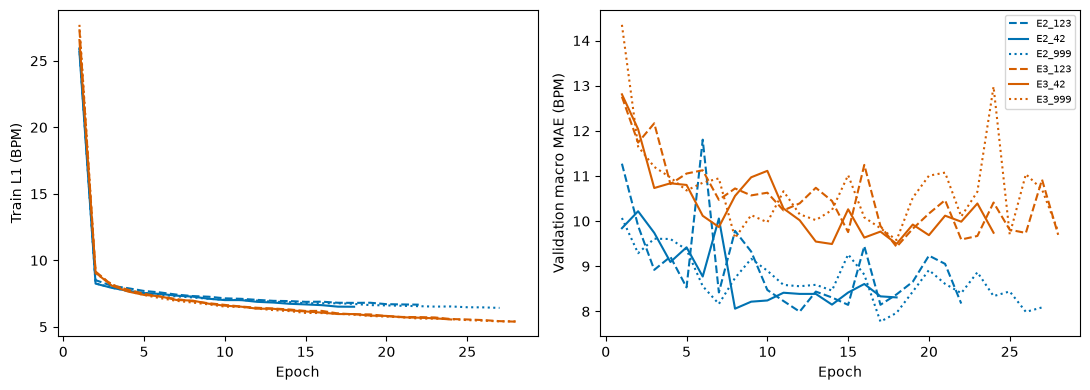

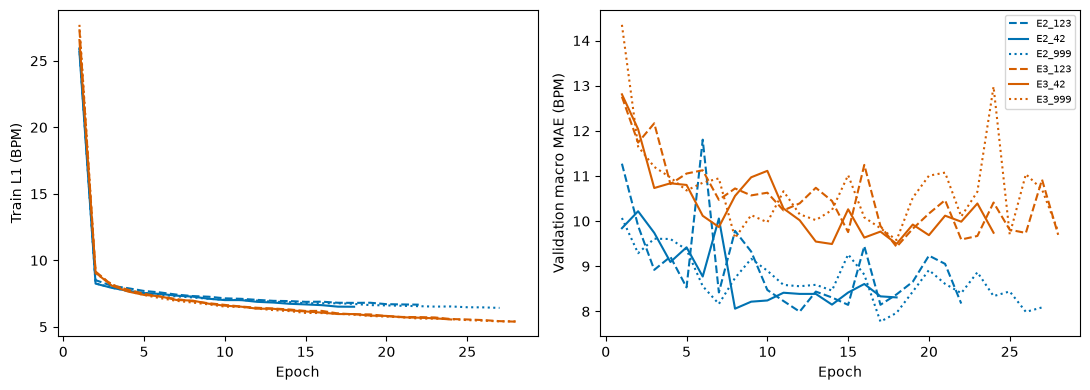

In [146]:
plot_training_history(PROJECT_DIR)

## 8. Lượng tử hóa tĩnh 8 bit

Calibration sử dụng **1.000 cửa sổ Train thật**, seed42, lấy mẫu không hoàn lại,
quota **100 cửa sổ/người**. Các hoạt động được phân tầng theo tỷ lệ và quy tắc
largest remainder; cửa sổ chuyển tiếp là một stratum riêng. Ba checkpoint E3
dùng cùng danh sách ID, thứ tự và batch calibration **32**.

Mỗi checkpoint được nạp ở chế độ eval, sao chép và fuse Conv–BN–ReLU cùng
Linear–ReLU ở head. Đầu ra FP32 trước/sau fusion được kiểm tra trên Validation
với `atol=1e−6`, `rtol=1e−5`. Mô hình được prepare, calibration bằng Train,
convert và audit toán tử/dtype trên backend oneDNN.

Artifact model-only được export rồi nạp lại để đối chiếu dự đoán chính xác.
FP32/INT8 có cùng phạm vi đóng gói state_dict; checkpoint optimizer được tách
khỏi phép so dung lượng. Kiểm tra sau convert lưu observer/qconfig, phần float
còn lại, checksum và sai số Validation của từng cặp seed.


### 8.1. Biểu diễn lượng tử hóa và phạm vi toán tử

Lượng tử hóa ánh xạ giá trị thực sang miền số nguyên và khôi phục xấp xỉ bằng:

$$q=\operatorname{clamp}(\operatorname{round}(x/s)+z,q_{min},q_{max}),\qquad
\widetilde{x}=s(q-z).$$

Scale $s$ và zero-point $z$ của activation được xác định từ calibration Train.
Ba Conv và hai Linear sau convert có trọng số **qint8**; activation trên đường
lượng tử hóa là **quint8** và đầu ra BPM sau DeQuant trở về float32.
Bias, DSP và miền đầu vào/đầu ra ngoài Quant/DeQuant vẫn dùng float.
Tên INT8 biểu thị đường suy luận 8 bit với các biên chuyển dtype này.

E4 được tạo riêng từ từng checkpoint E3 đã chọn bằng Validation. Do đó phép so
E3/E4 theo cùng seed phản ánh tác động PTQ trên cùng trọng số FP32 nguồn,
khác với huấn luyện một kiến trúc hoặc bài toán mới.


In [147]:
def largest_remainder(counts,total):
    if total<0 or total>sum(counts.values()): raise ValueError("Insufficient strata capacity")
    keys=sorted(counts); capacity=sum(counts.values())
    exact={key:total*counts[key]/capacity for key in keys}
    quotas={key:int(math.floor(exact[key])) for key in keys}
    remaining=total-sum(quotas.values())
    for key in sorted(keys,key=lambda key:(-(exact[key]-quotas[key]),key))[:remaining]:
        quotas[key]+=1
    return quotas

In [148]:
def _cal_subject_quotas(train):
    capacities={subject:int(sum(train.subject_id==subject)) for subject in SPLITS["train"]}
    quotas={subject:min(100,capacity) for subject,capacity in capacities.items()}
    while sum(quotas.values())<1000:
        for subject in SPLITS["train"]:
            if quotas[subject]<capacities[subject] and sum(quotas.values())<1000:
                quotas[subject]+=1
    return quotas

In [149]:
def _cal_sample_strata(train,quotas):
    rng=np.random.default_rng(42); selected=[]; audit=[]
    train["stratum"]=[f"activity_{int(a)}" if status=="assigned" else status
                     for a,status in zip(train.activity_id,train.activity_status)]
    for subject in SPLITS["train"]:
        frame=train.loc[train.subject_id==subject]
        counts=frame.groupby("stratum").size().to_dict()
        for stratum,n in largest_remainder(counts,quotas[subject]).items():
            population=frame.loc[frame.stratum==stratum].sort_values("window_id")
            positions=rng.choice(len(population),size=n,replace=False)
            selected.append(population.iloc[positions])
            audit.append({"subject_id":subject,"stratum":stratum,"capacity":int(counts[stratum]),"selected":n})
    return pd.concat(selected).iloc[rng.permutation(1000)].reset_index(drop=True),audit

In [150]:
def calibration_manifest(ctx):
    require_unlocked(ctx["root"])
    train=ctx["manifest"].loc[ctx["manifest"].eligible&(ctx["manifest"].split=="train")].copy()
    if len(train)<1000: raise ValueError("Need 1000 unique real Train windows")
    quotas=_cal_subject_quotas(train); sample,audit=_cal_sample_strata(train,quotas)
    if sample.window_id.duplicated().any() or set(sample.split)!={"train"}: raise ValueError("Calibration leakage")
    path=ctx["root"]/"results/manifests/calibration.csv"
    if path.exists() and read_frame(path).window_id.tolist()!=sample.window_id.tolist():
        raise ValueError("Shared calibration IDs changed")
    sample.to_csv(path,index=False)
    recipe={"passed":True,"n_windows":1000,"seed":42,"replacement":False,"split":"train",
        "subject_quota":quotas,"strata":audit,"window_ids_sha256":hash_object(sample.window_id.tolist()),
        "calibration_sha256":sha256_file(path),"preprocess_hash":ctx["index"]["preprocess_hash"],
        "manifest_sha256":sha256_file(ctx["manifest_path"]),"batch_size":32}
    write_json(path.with_suffix(".json"),recipe)
    return sample,recipe

In [151]:
def audit_quantized_model(model,window):
    modules=[]; observed=[]; handles=[]
    for name,module in model.named_modules():
        if name in ("quant","conv1","conv2","conv3","gap","fc1","fc2","dequant"):
            def hook(_module,_inputs,output,label=name):
                observed.append({"name":label,"dtype":str(output.dtype),"quantized":output.is_quantized})
            handles.append(module.register_forward_hook(hook))
        weight=getattr(module,"weight",None)
        if callable(weight):
            tensor=weight()
            if isinstance(tensor,torch.Tensor):
                modules.append({"name":name,"class":type(module).__name__,"dtype":str(tensor.dtype),
                                "is_quantized":tensor.is_quantized,"qscheme":str(tensor.qscheme()) if tensor.is_quantized else None})
    with torch.inference_mode(): model(window)
    for handle in handles: handle.remove()
    quantized=[row for row in modules if row["is_quantized"] and row["dtype"]=="torch.qint8"]
    if len(quantized)!=5 or not any(row["name"]=="quant" and row["quantized"] for row in observed):
        raise ValueError("Expected 3 quantized convolutions, 2 linears and activation Quant")
    if observed[-1]["quantized"]: raise ValueError("Final BPM must be dequantized")
    return {"weights":modules,"activations":observed,
            "remaining_float":"Input/output, float bias and host DSP; GAP preserves quantized activation"}

In [152]:
def _ptq_fuse_and_check(original,validation):
    fused=copy.deepcopy(original).eval()
    fused.fuse_for_inference()
    before=predict_tensor(original,validation[:100])
    after=predict_tensor(fused,validation[:100])
    np.testing.assert_allclose(after,before,atol=1e-6,rtol=1e-5)
    return fused

In [153]:
def _ptq_calibrate(fused,windows,backend,batch_size):
    fused.qconfig=get_default_qconfig(backend)
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always")
        prepare(fused,inplace=True)
        with torch.inference_mode():
            for begin in range(0,len(windows),batch_size):
                fused(windows[begin:begin+batch_size])
        quantized=convert(fused,inplace=False)
    return quantized,sorted(set(str(item.message) for item in captured)),str(fused.qconfig)

In [154]:
def _ptq_export_validate(ctx,run,model,validation,frame,seed,backend):
    predicted=predict_tensor(model,validation)
    path=run.directory/"model_int8.pt"
    saved=save_inference_model(model,path,input_channels=4,quantized=True,backend=backend)
    reloaded=load_inference_model(path,saved["sha256"])
    roundtrip=predict_tensor(reloaded,validation)
    np.testing.assert_allclose(roundtrip,predicted,atol=0,rtol=0)
    joined=prediction_frame(frame,roundtrip,"E4",seed)
    joined.to_csv(run.directory/"validation_predictions.csv",index=False)
    metrics=compute_metrics(joined,expected_subjects=list(SPLITS["validation"]))
    write_json(run.directory/"validation_metrics.json",metrics)
    return saved,metrics

In [155]:
def _ptq_finish(ctx,run,seed,source,saved,metrics,calibration,audit,qconfig,warning_text):
    score=metrics["overall"]["macro_subject"]["mae_bpm"]
    result={"passed":True,"ecode":"E4","seed":seed,"config_sha256":hash_object(ctx["config"]),
        "artifact":saved["path"].relative_to(ctx["root"]).as_posix(),
        "artifact_sha256":saved["sha256"],"artifact_bytes":saved["bytes"],
        "source_artifact":source["artifact"],"source_sha256":source["artifact_sha256"],
        "calibration":calibration,"backend":ctx["config"]["quantization"]["backend"],
        "qconfig":qconfig,"warnings":warning_text,"audit":audit,"roundtrip_exact":True,
        "fusion_atol":1e-6,"fusion_rtol":1e-5,"val_macro_mae_bpm":score,
        "val_delta_vs_fp32_bpm":score-source["val_macro_mae_bpm"],
        "preprocess_hash":ctx["index"]["preprocess_hash"],"runtime":accelerator_info()}
    write_json(run.directory/"checks.json",result)
    names=("model_int8.pt","validation_predictions.csv","validation_metrics.json","checks.json")
    run.finish(evidence={name:run.directory/name for name in names})
    print(f"PTQ seed={seed}: Val={score:.3f}; bytes={saved['bytes']}",flush=True)
    return result

In [156]:
def _ptq_one(ctx,seed,source,calibration,cx,vx,frame):
    backend=ctx["config"]["quantization"]["backend"]
    run=RunRecorder(ctx["root"],ctx["root"]/"results/ptq/runs",ctx["config"],
        ecode="E4",kind="final",seed=seed,
        inputs={"calibration":ctx["root"]/"results/manifests/calibration.csv"},
        parent_checkpoint=ctx["root"]/source["artifact"])
    try:
        original=load_inference_model(ctx["root"]/source["artifact"],source["artifact_sha256"])
        fused=_ptq_fuse_and_check(original,vx)
        quantized,text,qconfig=_ptq_calibrate(fused,cx,backend,ctx["config"]["quantization"]["calibration_batch_size"])
        audit=audit_quantized_model(quantized,vx[:1])
        saved,metrics=_ptq_export_validate(ctx,run,quantized,vx,frame,seed,backend)
        return _ptq_finish(ctx,run,seed,source,saved,metrics,calibration,audit,qconfig,text)
    except BaseException as error:
        run.finish(error=str(error))
        raise

In [157]:
def ptq_record_matches(ctx,previous,source,calibration,seed):
    if not previous or not previous.get("passed"): return False
    expected={"ecode":"E4","seed":seed,"source_artifact":source["artifact"],
        "source_sha256":source["artifact_sha256"],"config_sha256":hash_object(ctx["config"]),
        "preprocess_hash":ctx["index"]["preprocess_hash"],"calibration":calibration,
        "backend":ctx["config"]["quantization"]["backend"]}
    if calibration.get("split")!="train" or any(previous.get(k)!=v for k,v in expected.items()): return False
    current=accelerator_info(); runtime=previous.get("runtime",{})
    if any(runtime.get(k)!=current[k] for k in ("python","torch")): return False
    parent=(ctx["root"]/source["artifact"]).resolve()
    artifact=(ctx["root"]/previous.get("artifact","")).resolve()
    return (parent.is_relative_to(ctx["root"].resolve()) and parent.is_file()
        and sha256_file(parent)==source["artifact_sha256"]
        and artifact.is_relative_to(ctx["root"].resolve()) and artifact.is_file()
        and artifact.stat().st_size==previous.get("artifact_bytes")
        and sha256_file(artifact)==previous.get("artifact_sha256"))


In [158]:
def ptq_registry_complete(ctx,index,training,calibration):
    if set(index["runs"])!={f"E4_{s}" for s in (42,123,999)}: return False
    if not all(f"E3_{s}" in training["runs"] for s in (42,123,999)): return False
    return all(ptq_record_matches(ctx,index["runs"][f"E4_{s}"],
        training["runs"][f"E3_{s}"],calibration,s) for s in (42,123,999))


In [159]:
def _ptq_run_registry(ctx,training,calibration,cx,vx,frame,seeds):
    require_unlocked(ctx["root"])
    path=ctx["root"]/"results/ptq_index.json"
    index=read_json(path) if path.exists() else {"schema_version":1,"runs":{}}
    for seed in seeds:
        key=f"E4_{seed}"; previous=index["runs"].get(key)
        source=training["runs"][f"E3_{seed}"]
        if ptq_record_matches(ctx,previous,source,calibration,seed):
            print(f"Reuse verified {key}",flush=True)
        else:
            index["runs"][key]=_ptq_one(ctx,seed,source,calibration,cx,vx,frame)
        index.update(passed=ptq_registry_complete(ctx,index,training,calibration),calibration=calibration)
        write_json(path,index)
    return index


In [160]:
def ptq_stage(ctx,seeds=(42,123,999)):
    require_unlocked(ctx["root"])
    training=read_json(ctx["root"]/"results/training_index.json")
    if not training.get("passed"): raise ValueError("Six final FP32 runs required")
    sample,calibration=calibration_manifest(ctx)
    tx,_,frame=materialize_split(ctx,"train","cpu")
    positions=pd.Series(np.arange(len(frame)),index=frame.window_id).loc[sample.window_id].to_numpy()
    cx=tx[torch.as_tensor(positions)]
    vx,_,validation=materialize_split(ctx,"validation","cpu")
    backend=ctx["config"]["quantization"]["backend"]
    if backend not in torch.backends.quantized.supported_engines: raise ValueError("Backend unavailable")
    torch.backends.quantized.engine=backend
    torch.set_num_threads(1)
    return _ptq_run_registry(ctx,training,calibration,cx,vx,validation,seeds)

In [161]:
PTQ_RUN = run_stage("ptq")

C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\3266216309.py:8: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  cx=tx[torch.as_tensor(positions)]
C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\386673514.py:2: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  fused.qconfig=get_default_qconfig(backend)
d:\IoT_DACK\.venv-gpu\Lib\site-packages\torch\_utils.py:466: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the

PTQ seed=42: Val=9.477; bytes=39925


C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\386673514.py:2: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  fused.qconfig=get_default_qconfig(backend)
C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\2829711774.py:12: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  model.qconfig=get_default_qconfig(backend)


PTQ seed=123: Val=9.435; bytes=39925


C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\386673514.py:2: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  fused.qconfig=get_default_qconfig(backend)
C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\2829711774.py:12: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  model.qconfig=get_default_qconfig(backend)


PTQ seed=999: Val=9.569; bytes=39925


In [162]:
show_table("results/manifests/calibration.csv", limit=10)

,window_id,subject_id,split,label_index,start_s,end_s,ppg_start_idx,ppg_end_idx,acc_start_idx,acc_end_idx,...,activity_id,activity_fraction,activity_status,dominant_activity_code,eligible,exclusion_reason,ppg_flat,source_sha256,preprocess_hash,stratum
0,final_32hz_v1:S10:000197,S10,train,197,394,402,12608,12864,12608,12864,...,NaN,1.0,mixed_transition,0,True,NaN,False,bed48c8e38bdaed8fbd5e3f662b49d240119a98dfe4619...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,mixed_transition
1,final_32hz_v1:S5:000821,S5,train,821,1642,1650,52544,52800,52544,52800,...,3.0,1.0,assigned,3,True,NaN,False,e9593717aa524e4c0ab37ba5603f7e6190fff1385251d5...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,activity_3
2,final_32hz_v1:S8:003838,S8,train,3838,7676,7684,245632,245888,245632,245888,...,8.0,1.0,assigned,8,True,NaN,False,4072e197ff7ddbd184d721b6643215dd7101af93e1a9c0...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,activity_8
3,final_32hz_v1:S8:002634,S8,train,2634,5268,5276,168576,168832,168576,168832,...,6.0,1.0,assigned,6,True,NaN,False,4072e197ff7ddbd184d721b6643215dd7101af93e1a9c0...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,activity_6
4,final_32hz_v1:S6:002498,S6,train,2498,4996,5004,159872,160128,159872,160128,...,5.0,1.0,assigned,5,True,NaN,False,c9fece7217d0ffd648e55ec9d139237bfb37b9958efb6c...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,activity_5
5,final_32hz_v1:S8:002070,S8,train,2070,4140,4148,132480,132736,132480,132736,...,NaN,1.0,mixed_transition,0,True,NaN,False,4072e197ff7ddbd184d721b6643215dd7101af93e1a9c0...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,mixed_transition
6,final_32hz_v1:S3:000352,S3,train,352,704,712,22528,22784,22528,22784,...,NaN,1.0,mixed_transition,0,True,NaN,False,0fe923d3a7e7fd60e5245e655a9c1d0a1c2c106ea3128e...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,mixed_transition
7,final_32hz_v1:S7:002911,S7,train,2911,5822,5830,186304,186560,186304,186560,...,6.0,1.0,assigned,6,True,NaN,False,ea669d42137d1a90127bb7be3c5c5613f636a00814cd04...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,activity_6
8,final_32hz_v1:S10:003737,S10,train,3737,7474,7482,239168,239424,239168,239424,...,6.0,1.0,assigned,6,True,NaN,False,bed48c8e38bdaed8fbd5e3f662b49d240119a98dfe4619...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,activity_6
9,final_32hz_v1:S3:000609,S3,train,609,1218,1226,38976,39232,38976,39232,...,2.0,1.0,assigned,2,True,NaN,False,0fe923d3a7e7fd60e5245e655a9c1d0a1c2c106ea3128e...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,activity_2


In [163]:
show_json("results/manifests/calibration.json")

{'batch_size': 32,
 'calibration_sha256': '0fc39516cb538d83690c35f824b08b97081d5cab3dc417569241f41c38e406af',
 'manifest_sha256': '1a89dcdaccd8be309080460178673905b20fcbfa5a8d9c9a2acc75f341a663cb',
 'n_windows': 1000,
 'passed': True,
 'preprocess_hash': 'b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2abf9827eb885bfa543',
 'replacement': False,
 'seed': 42,
 'split': 'train',
 'strata': [{'capacity': 347,
   'selected': 8,
   'stratum': 'activity_1',
   'subject_id': 'S1'},
  {'capacity': 141,
   'selected': 3,
   'stratum': 'activity_2',
   'subject_id': 'S1'},
  {'capacity': 170,
   'selected': 4,
   'stratum': 'activity_3',
   'subject_id': 'S1'},
  {'capacity': 203,
   'selected': 4,
   'stratum': 'activity_4',
   'subject_id': 'S1'},
  {'capacity': 442,
   'selected': 10,
   'stratum': 'activity_5',
   'subject_id': 'S1'},
  {'capacity': 1175,
   'selected': 25,
   'stratum': 'activity_6',
   'subject_id': 'S1'},
  {'capacity': 375,
   'selected': 8,
   'stratum': 'activity_7',
   

In [164]:
display(pd.DataFrame([{k: r.get(k) for k in ("seed", "artifact_bytes", "val_macro_mae_bpm", "val_delta_vs_fp32_bpm", "backend", "roundtrip_exact")} for r in PTQ_RUN["runs"].values()]))

,seed,artifact_bytes,val_macro_mae_bpm,val_delta_vs_fp32_bpm,backend,roundtrip_exact
0,42,39925,9.477321,-0.015836,onednn,True
1,123,39925,9.434915,0.005699,onednn,True
2,999,39925,9.568882,-0.011881,onednn,True


## 9. Giao thức đánh giá và chỉ số

Cấu hình, nguồn dữ liệu, manifest, chuẩn hóa, calibration và artifacts được
ghi nhận trong protocol lock trước đánh giá cuối. Lịch sử truy cập Test được
lưu để phản ánh đúng bản chất Test kế thừa. Việc lựa chọn checkpoint và PTQ
dựa trên Train/Validation; phân tích Test sau khóa có vai trò đánh giá và mô tả.

Với $N_s$ cửa sổ hợp lệ của người $s$, chỉ số được tính từng người rồi lấy macro:

$$MAE_s=\frac1{N_s}\sum_{i=1}^{N_s}|\hat y_i-y_i|,\qquad
MAE_{macro}=\frac1S\sum_{s=1}^{S}MAE_s.$$
$$RMSE_s=\sqrt{\frac1{N_s}\sum_{i=1}^{N_s}(\hat y_i-y_i)^2},\qquad
RMSE_{macro}=\frac1S\sum_{s=1}^{S}RMSE_s.$$
$$P10_s=\frac{100}{N_s}\sum_{i=1}^{N_s}\mathbf1(|\hat y_i-y_i|>10),\qquad
P10_{macro}=\frac1S\sum_{s=1}^{S}P10_s.$$
$$MAE_{pooled}=\frac1{N_{valid}}\sum_{i=1}^{N_{valid}}|\hat y_i-y_i|.$$

Macro theo người là chỉ số chính; pooled theo cửa sổ là bổ sung.
RMSE macro là trung bình RMSE từng người. Nhóm hoạt động không có dữ liệu được
ghi NA cùng mẫu số. Coverage là tỷ lệ cửa sổ có dự đoán hợp lệ trong miền đánh giá.

Với $M_k$ là chỉ số macro của một seed và $K=3$, mean và sample std được tính bởi:

$$\overline{M}=\frac1K\sum_{k=1}^{K}M_k,\qquad
s_{seed}=\sqrt{\frac1{K-1}\sum_{k=1}^{K}(M_k-\overline{M})^2}.$$

$s_{seed}$ mô tả biến thiên huấn luyện; ba seed không tạo thêm người Test độc lập.
Bảng đủ 15 người được gắn nhãn Train/Validation/Test; chỉ S13–S15 được sử dụng
cho kết luận kiểm thử của mạng.


In [165]:
def notebook_source_hash(path):
    notebook=read_json(path)
    return hash_object([{"cell_type":cell["cell_type"],"source":cell["source"]} for cell in notebook["cells"]])

In [166]:
def _lock_collect_paths(ctx,training,ptq,decision):
    paths=["configs/default.toml","uv.lock","results/data_sources.json","results/data_inventory.json",
        "results/alignment.json","results/manifests/windows.csv","results/manifests/acc_stats.json",
        "results/manifests/preprocessing.json","results/manifests/calibration.csv","results/manifests/calibration.json",
        "results/baselines/index.json","results/benchmark_review.json","results/training_index.json","results/ptq_index.json"]
    if decision["type"]=="explicit_source_decision": paths.append("results/benchmark_source_decision.json")
    for record in list(training["runs"].values())+list(ptq["runs"].values()):
        if not record["passed"] or sha256_file(ctx["root"]/record["artifact"])!=record["artifact_sha256"]:
            raise ValueError("Artifact checksum/gate mismatch")
        paths.append(record["artifact"])
    for record in read_json(ctx["root"]/"results/baselines/index.json")["methods"].values():
        paths.extend([record["predictions"],record["metrics"]])
    return sorted(set(paths))

In [167]:
def lock_protocol(ctx):
    if (ctx["root"]/"results/protocol_lock.json").exists(): return verify_lock(ctx)
    decision=require_training_gate(ctx)
    training=read_json(ctx["root"]/"results/training_index.json")
    ptq=read_json(ctx["root"]/"results/ptq_index.json")
    if not training.get("passed") or not ptq.get("passed"): raise ValueError("G07/G08 incomplete")
    paths=_lock_collect_paths(ctx,training,ptq,decision)
    content={"schema_version":1,"passed":True,"created_at":now_utc(),"decision":decision,
        "preprocess_hash":ctx["index"]["preprocess_hash"],
        "files":{p:sha256_file(ctx["root"]/p) for p in paths},"code":code_snapshot(ctx["root"])["files"],
        "notebook_source_sha256":notebook_source_hash(ctx["root"]/"DinhLeHoangDanh_DoAn_PPG_DaLiA.ipynb"),
        "selection":"Train/Val only; Val macro checkpoint; default PTQ",
        "metrics":{"primary":"subject_macro","large_error":"abs(error)>10","seed_std_ddof":1},
        "test_history":"results/test_access.jsonl; inherited Test"}
    content["protocol_sha256"]=hash_object(content)
    write_json(ctx["root"]/"results/protocol_lock.json",content)
    return content

In [168]:
def verify_lock(ctx):
    lock=read_json(ctx["root"]/"results/protocol_lock.json")
    if not lock["passed"] or lock["preprocess_hash"]!=ctx["index"]["preprocess_hash"]:
        raise ValueError("Protocol lock unavailable/stale")
    copy_lock=dict(lock); claimed=copy_lock.pop("protocol_sha256")
    if hash_object(copy_lock)!=claimed: raise ValueError("Lock content corrupted")
    for relative,checksum in lock["files"].items():
        if sha256_file(ctx["root"]/relative)!=checksum: raise ValueError(f"Locked file changed: {relative}")
    if code_snapshot(ctx["root"])["files"]!=lock["code"]: raise ValueError("Code changed after lock")
    if notebook_source_hash(ctx["root"]/"DinhLeHoangDanh_DoAn_PPG_DaLiA.ipynb")!=lock["notebook_source_sha256"]:
        raise ValueError("Notebook code/markdown changed after lock")
    return lock

In [169]:
def _eval_predictions(ctx,frame,x):
    predictions={}; baseline=read_json(ctx["root"]/"results/baselines/index.json")
    for name,record in baseline["methods"].items():
        all_pred=read_frame(ctx["root"]/record["predictions"])
        current=all_pred.loc[all_pred.window_id.isin(frame.window_id)].reset_index(drop=True)
        predictions[name]=join_predictions(frame,current,allow_invalid=name=="E1_pure")
    training=read_json(ctx["root"]/"results/training_index.json")
    ptq=read_json(ctx["root"]/"results/ptq_index.json")
    for key,record in {**training["runs"],**ptq["runs"]}.items():
        model=load_inference_model(ctx["root"]/record["artifact"],record["artifact_sha256"])
        channels=1 if key.startswith("E2") else 4
        values=predict_tensor(model,x[:,:channels,:])
        predictions[key]=prediction_frame(frame,values,record["ecode"],record["seed"])
        print(f"Evaluation {key}: {len(values)} windows",flush=True)
    return predictions

In [170]:
def _eval_save_methods(ctx,run,predictions,expected):
    methods={}; metrics={}; evidence={}
    for key,joined in predictions.items():
        path=run.directory/f"{key}_predictions.csv"
        joined.to_csv(path,index=False)
        metrics[key]=compute_metrics(joined,expected_subjects=expected)
        metric_path=run.directory/f"{key}_metrics.json"; write_json(metric_path,metrics[key])
        evidence[f"{key}_predictions"]=path; evidence[f"{key}_metrics"]=metric_path
        methods[key]={"predictions":path.relative_to(ctx["root"]).as_posix(),
            "metrics":metric_path.relative_to(ctx["root"]).as_posix(),"prediction_sha256":sha256_file(path)}
    return methods,metrics,evidence

In [171]:
def _eval_seed_summary(metrics):
    summary={}
    for experiment in ("E2","E3","E4"):
        summary[experiment]={name:summarize_seeds({
            seed:metrics[f"{experiment}_{seed}"]["overall"]["macro_subject"][name]
            for seed in (42,123,999)}) for name in ("mae_bpm","rmse_bpm","error_gt_10_percent")}
    for left,right in (("E3","E2"),("E4","E3")):
        summary[f"delta_{left}_minus_{right}"]=summarize_seeds({
            seed:metrics[f"{left}_{seed}"]["overall"]["macro_subject"]["mae_bpm"]-
                 metrics[f"{right}_{seed}"]["overall"]["macro_subject"]["mae_bpm"]
            for seed in (42,123,999)})
    return summary

In [172]:
def _eval_finish(ctx,run,out,split,lock,predictions,expected):
    methods,metrics,evidence=_eval_save_methods(ctx,run,predictions,expected)
    write_json(run.directory/"seed_summary.json",_eval_seed_summary(metrics))
    write_json(run.directory/"ibi_paired_subset.json",paired_subset_metrics(predictions))
    index={"passed":True,"split":split,"diagnostic":split=="all","methods":methods,
        "protocol_sha256":lock["protocol_sha256"],
        "summary":(run.directory/"seed_summary.json").relative_to(ctx["root"]).as_posix(),
        "paired_subset":(run.directory/"ibi_paired_subset.json").relative_to(ctx["root"]).as_posix()}
    write_json(out/"index.json",index); evidence["index"]=out/"index.json"
    evidence["summary"]=run.directory/"seed_summary.json"; evidence["paired"]=run.directory/"ibi_paired_subset.json"
    run.finish(evidence=evidence)
    return index

In [173]:
def evaluation_stage(ctx,split="test"):
    lock=verify_lock(ctx)
    if split not in ("test","all"): raise ValueError("Test or labeled all-subject diagnostic")
    out=ctx["root"]/("results/final_test" if split=="test" else "results/all_subject_diagnostics")
    run=RunRecorder(ctx["root"],out/"runs",ctx["config"],ecode="G09",kind="final",
                    inputs={"lock":ctx["root"]/"results/protocol_lock.json"})
    log_test_access(ctx,"locked_network_evaluation",detail={"run_id":run.record["run_id"],"split":split})
    try:
        x,_,frame=materialize_split(ctx,split,"cpu")
        expected=list(SPLITS["test"] if split=="test" else SUBJECTS)
        if set(frame.subject_id)!=set(expected): raise ValueError("Missing eligible subject")
        torch.set_num_threads(1)
        predictions=_eval_predictions(ctx,frame,x)
        index=_eval_finish(ctx,run,out,split,lock,predictions,expected)
        log_test_access(ctx,"locked_network_evaluation",status="complete")
        return index
    except BaseException as error:
        run.finish(error=str(error))
        log_test_access(ctx,"locked_network_evaluation",status="failed",detail=str(error))
        raise

In [174]:
PROTOCOL_LOCK = run_stage("lock")

In [175]:
FINAL_TEST = run_stage("evaluate")

Evaluation E2_123: 13007 windows
Evaluation E2_42: 13007 windows
Evaluation E2_999: 13007 windows
Evaluation E3_123: 13007 windows
Evaluation E3_42: 13007 windows
Evaluation E3_999: 13007 windows


C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\2829711774.py:12: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  model.qconfig=get_default_qconfig(backend)


Evaluation E4_123: 13007 windows


C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\2829711774.py:12: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  model.qconfig=get_default_qconfig(backend)


Evaluation E4_42: 13007 windows


C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\2829711774.py:12: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  model.qconfig=get_default_qconfig(backend)


Evaluation E4_999: 13007 windows


In [176]:
ALL_SUBJECT_DIAGNOSTIC = run_stage("diagnostic")

Evaluation E2_123: 64697 windows
Evaluation E2_42: 64697 windows
Evaluation E2_999: 64697 windows
Evaluation E3_123: 64697 windows
Evaluation E3_42: 64697 windows
Evaluation E3_999: 64697 windows


C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\2829711774.py:12: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  model.qconfig=get_default_qconfig(backend)


Evaluation E4_123: 64697 windows


C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\2829711774.py:12: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  model.qconfig=get_default_qconfig(backend)


Evaluation E4_42: 64697 windows


C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\2829711774.py:12: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  model.qconfig=get_default_qconfig(backend)


Evaluation E4_999: 64697 windows


In [177]:
show_json("results/protocol_lock.json")

{'code': {'scripts/check_setup.py': 'deca7eb621d115870c3d7be482fc2e8310041f9d66b5ec8a7b6dd4a70fa27942',
  'scripts/demo_pipeline.py': '4b40b2eec1129bd1234ef7d65a6095c723980f0045d732478875cf0d2d823b28',
  'scripts/download_dataset.py': '837faa6a9ffa354f13fef5c3f40d9f9c73da5c975e4b0cfbbd96b88172e7d1e4',
  'scripts/execute_notebook.py': 'af0dc63acc3f678180f4ed8f1a2d9d77c601d66c5172173d556873f84b20dc31',
  'scripts/export_public_artifacts.py': '8cb7e8e70c680dc0835a120724db9a67ddee99307b74e1ddc9cef3a83bedc459',
  'scripts/inspect_dataset.py': '4284e430ace1ee02df9652a8c3828a810a3115e4a9783d96b7e375e4ab5bb8fd',
  'scripts/prepare_data.py': 'f53ef89629bf96f9bb56791d14942f70cf502c5de0a80cc96089d554df94a501',
  'scripts/prepare_demo.py': 'b67e73b39da74e7575a27991c536698d2015ec659d4521832da183a9d476aae4',
  'scripts/setup_accelerator.py': 'e1d8fdcfa5d9a023e401abfd88ce4ffcff25bfc2901dcee8837bfdf11af59f02',
  'scripts/smoke_ptq.py': 'cb1c47c49bbb746f3da242262725ba9ca182085b89a3b1865b48026f96b55f24'

In [178]:
display(read_json(PROJECT_DIR / FINAL_TEST["summary"]))
display(read_json(PROJECT_DIR / FINAL_TEST["paired_subset"]))

{'E2': {'error_gt_10_percent': {'mean': 12.203572900061383,
   'seeds': [42, 123, 999],
   'std': 0.6817165232450295,
   'std_ddof': 1,
   'values': [11.53931289122144, 12.901498473832953, 12.169907335129759]},
  'mae_bpm': {'mean': 4.768397154257927,
   'seeds': [42, 123, 999],
   'std': 0.08014104984186841,
   'std_ddof': 1,
   'values': [4.7099907172104, 4.859762290008533, 4.735438455554848]},
  'rmse_bpm': {'mean': 7.579428253121343,
   'seeds': [42, 123, 999],
   'std': 0.13812059639384933,
   'std_ddof': 1,
   'values': [7.4790070379918, 7.736942093685507, 7.522335627686719]}},
 'E3': {'error_gt_10_percent': {'mean': 12.41950363730651,
   'seeds': [42, 123, 999],
   'std': 0.5748385637557859,
   'std_ddof': 1,
   'values': [11.815315805308131, 12.483569882373013, 12.959625224238385]},
  'mae_bpm': {'mean': 4.81617996757689,
   'seeds': [42, 123, 999],
   'std': 0.11917098607032417,
   'std_ddof': 1,
   'values': [4.701688096817187, 4.807316655733444, 4.939535150180038]},
  'rmse_

{'coverage': 1.0,
 'methods': {'E0': {'by_activity': [{'activity': 'sitting',
     'activity_id': 1,
     'by_subject': [{'coverage': 1.0,
       'error_gt_10_percent': 0.0,
       'mae_bpm': 1.1126373517269244,
       'n_total': 300,
       'n_valid': 300,
       'rmse_bpm': 1.5274938422952502,
       'subject_id': 'S13'},
      {'coverage': 1.0,
       'error_gt_10_percent': 0.6644518272425249,
       'mae_bpm': 0.7520899091154603,
       'n_total': 301,
       'n_valid': 301,
       'rmse_bpm': 1.4478045719105395,
       'subject_id': 'S14'},
      {'coverage': 1.0,
       'error_gt_10_percent': 1.9736842105263157,
       'mae_bpm': 1.4039545186687605,
       'n_total': 304,
       'n_valid': 304,
       'rmse_bpm': 2.715509173028417,
       'subject_id': 'S15'}],
     'macro_subject': {'error_gt_10_percent': 0.8793786792562802,
      'mae_bpm': 1.0895605931703818,
      'n_subjects_with_data': 3,
      'rmse_bpm': 1.896935862411402},
     'pooled_window': {'coverage': 1.0,
      'e

## 10. Dung lượng tệp và thời gian suy luận CPU

Dung lượng được đo bằng số byte của artifact suy luận sau kiểm tra nạp lại.
Benchmark sử dụng CPU, eval/inference mode, batch **1**, thread **1**,
**100 lượt warm-up** và **1.000 lượt đo/artifact**. Các duration thô được lưu
để tổng hợp mean, median và p95 cùng thông tin CPU, OS, runtime và backend.

Thời gian mạng bao gồm Quant/DeQuant, tách khỏi nạp dữ liệu, tiền xử lý và vẽ.
Chi phí DSP được đo riêng trên chuỗi liên tục S11 và các cửa sổ chuẩn hóa.
Chi phí phân bổ từ toàn bản ghi là amortized offline cost, khác với latency
thu nhận và xử lý tín hiệu trực tiếp trên thiết bị.

$$R_{size}=\frac{bytes_{FP32}}{bytes_{INT8}},\qquad
speedup_{median}=\frac{median(t_{FP32})}{median(t_{INT8})}.$$

Tệp suy luận, RAM, Flash toàn chương trình và năng lượng là các đại lượng khác
nhau. Phép đo CPU/file size trong nghiên cứu này phản ánh hai đại lượng đầu ra
cụ thể là thời gian mạng trên host và số byte artifact, chưa xác lập tài nguyên MCU.


In [179]:
def measure_latency(model,windows,warmup=100,iterations=1000):
    if warmup<100 or iterations<1000 or windows.ndim!=3 or windows.device.type!="cpu":
        raise ValueError("CPU benchmark requires >=100 warmups, >=1000 measurements")
    if torch.get_num_threads()!=1: raise ValueError("Benchmark requires one CPU thread")
    model.eval(); times=[]
    with torch.inference_mode():
        for index in range(warmup): model(windows[index%len(windows):index%len(windows)+1])
        for index in range(iterations):
            tensor=windows[index%len(windows):index%len(windows)+1]
            start=time.perf_counter_ns(); model(tensor); stop=time.perf_counter_ns()
            times.append((stop-start)/1e6)
    values=np.asarray(times)
    return values,{"n":iterations,"warmup":warmup,"batch_size":1,"cpu_threads":1,
                  "mean_ms":float(values.mean()),"median_ms":float(np.median(values)),
                  "p95_ms":float(np.quantile(values,.95)),"scope":"network including Quant/DeQuant; DSP/load/plot excluded"}

In [180]:
def _bench_models(ctx,windows):
    training=read_json(ctx["root"]/"results/training_index.json")
    ptq=read_json(ctx["root"]/"results/ptq_index.json")
    rows=[]; raw=[]; policy=ctx["config"]["evaluation"]
    for key,record in {**training["runs"],**ptq["runs"]}.items():
        path=ctx["root"]/record["artifact"]
        model=load_inference_model(path,record["artifact_sha256"])
        channels=1 if key.startswith("E2") else 4
        times,stats=measure_latency(model,windows[:,:channels,:],
            policy["warmup_iterations"],policy["measurement_iterations"])
        rows.append({"method":key,"seed":record["seed"],"artifact_bytes":path.stat().st_size,
                     "artifact_sha256":record["artifact_sha256"],**stats})
        raw.extend({"method":key,"iteration":i,"latency_ms":float(value)} for i,value in enumerate(times))
    return pd.DataFrame(rows),pd.DataFrame(raw)

In [181]:
def _bench_pairs(table):
    rows=[]
    for seed in (42,123,999):
        fp=table.loc[table.method==f"E3_{seed}"].iloc[0]
        q=table.loc[table.method==f"E4_{seed}"].iloc[0]
        rows.append({"seed":seed,"fp32_bytes":int(fp.artifact_bytes),"int8_bytes":int(q.artifact_bytes),
            "compression_ratio":float(fp.artifact_bytes/q.artifact_bytes),
            "speedup_median":float(fp.median_ms/q.median_ms),"speedup_mean":float(fp.mean_ms/q.mean_ms)})
    return pd.DataFrame(rows)

In [182]:
def _bench_dsp(ctx):
    sources=read_json(ctx["root"]/"results/data_sources.json")
    record=load_subject("S11",dataset_root(),sources["subjects"]["S11"])
    start=time.perf_counter()
    filtered=filter_continuous(record,ctx["config"])
    normalize_acc(record.acc32,ctx["stats"])
    continuous_ms=(time.perf_counter()-start)*1000
    frame=ctx["manifest"].loc[(ctx["manifest"].subject_id=="S11")&ctx["manifest"].eligible]
    start=time.perf_counter()
    for row in frame.itertuples(): normalize_ppg(filtered[row.ppg_start_idx:row.ppg_end_idx])
    normalization_ms=(time.perf_counter()-start)*1000
    return {"subject_id":"S11","n_samples_native_ppg":len(record.ppg64),"n_windows":len(frame),
        "continuous_filter_resample_acc_ms":continuous_ms,"all_window_ppg_zscore_ms":normalization_ms,
        "amortized_ms_per_window":(continuous_ms+normalization_ms)/len(frame),
        "scope":"offline record cost; amortized cost is not streaming latency"}

In [183]:
def _bench_targets(ctx,pairs):
    final=read_json(ctx["root"]/"results/final_test/index.json")
    summary=read_json(ctx["root"]/final["summary"])
    accuracy=summary["E3"]["mae_bpm"]["mean"]; delta=summary["delta_E4_minus_E3"]["mean"]
    rows=[{"target":"E3 Test macro MAE mean3seed <=6 BPM","value":accuracy,"limit":6,"achieved":accuracy<=6},
          {"target":"mean3seed E4-E3 MAE <=0.5 BPM","value":delta,"limit":.5,"achieved":delta<=.5}]
    for pair in pairs.to_dict("records"):
        seed=pair["seed"]; size=pair["fp32_bytes"]; ratio=pair["compression_ratio"]
        rows.append({"target":f"FP32 seed {seed} <150000 bytes","value":size,"limit":150000,"achieved":size<150000})
        rows.append({"target":f"Compression seed {seed} >=2.5","value":ratio,"limit":2.5,"achieved":ratio>=2.5})
    for seed,value in zip((42,123,999),summary["delta_E4_minus_E3"]["values"]):
        rows.append({"target":f"E4-E3 seed {seed} <=0.5 BPM","value":value,"limit":.5,"achieved":value<=.5})
    return pd.DataFrame(rows)

In [184]:
def _bench_save(ctx,run,lock,table,raw,pairs,targets,dsp,frame):
    names=environment_names()
    runtime={"benchmark_device":"cpu",**names,"platform":names["os"],"python":platform.python_version(),
        "torch":torch.__version__,"backend":ctx["config"]["quantization"]["backend"],
        "threads":torch.get_num_threads(),"protocol_sha256":lock["protocol_sha256"],
        "window_ids_sha256":hash_object(frame.window_id.iloc[:1000].tolist())}
    tables={"model_benchmark.csv":table,"latency_raw.csv":raw,
            "paired_benchmark.csv":pairs,"target_status.csv":targets}
    for name,data in tables.items(): data.to_csv(run.directory/name,index=False)
    write_json(run.directory/"runtime.json",runtime)
    write_json(run.directory/"dsp_timing.json",dsp)
    index={"passed":True,"tables":{name:(run.directory/name).relative_to(ctx["root"]).as_posix() for name in tables},
           "runtime":runtime,"dsp":dsp,"scope":"host CPU; no MCU/energy claims"}
    path=ctx["root"]/"results/benchmark/index.json"; write_json(path,index)
    evidence={name:run.directory/name for name in (*tables,"runtime.json","dsp_timing.json")}
    evidence["index"]=path; run.finish(evidence=evidence)
    return index

In [185]:
def benchmark_stage(ctx):
    lock=verify_lock(ctx); torch.set_num_threads(1)
    x,_,frame=materialize_split(ctx,"validation","cpu")
    run=RunRecorder(ctx["root"],ctx["root"]/"results/benchmark/runs",ctx["config"],
        ecode="G10",kind="final",inputs={"lock":ctx["root"]/"results/protocol_lock.json"})
    try:
        table,raw=_bench_models(ctx,x[:1000])
        pairs=_bench_pairs(table)
        targets=_bench_targets(ctx,pairs)
        dsp=_bench_dsp(ctx)
        return _bench_save(ctx,run,lock,table,raw,pairs,targets,dsp,frame)
    except BaseException as error:
        run.finish(error=str(error))
        raise

In [186]:
CPU_BENCHMARK = run_stage("benchmark")

C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\2829711774.py:12: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  model.qconfig=get_default_qconfig(backend)
C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\2829711774.py:12: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  model.qconfig=get_default_qconfig(backend)
C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\2829711774.py:12: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  model.qconfig=get_default_qconfig(backend)


In [187]:
show_table(CPU_BENCHMARK["tables"]["model_benchmark.csv"])

,method,seed,artifact_bytes,artifact_sha256,n,warmup,batch_size,cpu_threads,mean_ms,median_ms,p95_ms,scope
0,E2_123,123,109685,8b4479eab6d4ee49842baa59910e7712a730603fc944ed...,1000,100,1,1,0.414310,0.34585,0.754785,network including Quant/DeQuant; DSP/load/plot...
1,E2_42,42,109685,2c54b1c4bad42959e529d1fb40c7d3d19190c961715039...,1000,100,1,1,0.423503,0.35890,0.792915,network including Quant/DeQuant; DSP/load/plot...
2,E2_999,999,109685,2d8ff30089bd607891964287f97612299c1af7e65741ff...,1000,100,1,1,0.463143,0.37080,0.982295,network including Quant/DeQuant; DSP/load/plot...
3,E3_123,123,112373,3341aa6ff32b5ea7a8a7ed37ddb91a1f643fa82415d114...,1000,100,1,1,0.429891,0.35920,0.829775,network including Quant/DeQuant; DSP/load/plot...
4,E3_42,42,112373,a14ffe6005edffab60cf091e4f8d15846ac0b761d32894...,1000,100,1,1,0.421216,0.34975,0.837085,network including Quant/DeQuant; DSP/load/plot...
5,E3_999,999,112373,1adc6cf018c536e9f8cc18983723e6d9aa179e044ac0d5...,1000,100,1,1,0.425739,0.35585,0.822830,network including Quant/DeQuant; DSP/load/plot...
6,E4_123,123,39925,bcf60fed1339b2da755022e7a8b68519a87e9fcc06c6c9...,1000,100,1,1,0.470820,0.31715,1.040740,network including Quant/DeQuant; DSP/load/plot...
7,E4_42,42,39925,1e1124c5d3ff0f98d7168699d5f76a5a20f9e2d208f23f...,1000,100,1,1,0.377299,0.29350,0.786245,network including Quant/DeQuant; DSP/load/plot...
8,E4_999,999,39925,eac2692be31a5e432044dbba41e48e216adc801998462b...,1000,100,1,1,0.378705,0.29920,0.836815,network including Quant/DeQuant; DSP/load/plot...


In [188]:
show_table(CPU_BENCHMARK["tables"]["paired_benchmark.csv"])

,seed,fp32_bytes,int8_bytes,compression_ratio,speedup_median,speedup_mean
0,42,112373,39925,2.814602,1.191652,1.116400
1,123,112373,39925,2.814602,1.132587,0.913068
2,999,112373,39925,2.814602,1.189338,1.124197


In [189]:
show_table(CPU_BENCHMARK["tables"]["target_status.csv"])

,target,value,limit,achieved
0,E3 Test macro MAE mean3seed <=6 BPM,4.816180,6.0,True
1,mean3seed E4-E3 MAE <=0.5 BPM,0.009996,0.5,True
2,FP32 seed 42 <150000 bytes,112373.000000,150000.0,True
3,Compression seed 42 >=2.5,2.814602,2.5,True
4,FP32 seed 123 <150000 bytes,112373.000000,150000.0,True
5,Compression seed 123 >=2.5,2.814602,2.5,True
6,FP32 seed 999 <150000 bytes,112373.000000,150000.0,True
7,Compression seed 999 >=2.5,2.814602,2.5,True
8,E4-E3 seed 42 <=0.5 BPM,-0.003918,0.5,True
9,E4-E3 seed 123 <=0.5 BPM,0.022339,0.5,True


## 11. Phân tích sai số và trường hợp thất bại

Bảng kết quả được tổng hợp từ predictions, metrics và benchmark có nguồn:
ba seed, 15 người kèm split, tám hoạt động, mixed/unknown, coverage IBI và
các chênh lệch E3−E2/E4−E3. Timeline thể hiện HR tham chiếu và dự đoán thô.

Các trường hợp minh họa được xác định bằng quy tắc công khai trên E3 seed42:
người Test có MAE thấp/cao nhất, cửa sổ có lỗi thấp/cao nhất và cửa sổ ACC/PTQ
làm sai số tăng nhiều nhất. Cách chọn này bao gồm cả kết quả thuận lợi và bất lợi.
Phân bố sai số và Bland–Altman mô tả các cửa sổ chồng lấn trong giao thức này;
chúng không cung cấp kiểm chứng lâm sàng hoặc giả thiết mẫu độc lập.

**Đính chính đơn vị hình minh họa cửa sổ:** đường PPG ở các hình failure case
là tín hiệu liên tục đã lọc và hạ mẫu, theo **đơn vị biên độ của dữ liệu nguồn**.
Nhãn “PPG z-score” trong các ảnh lưu của lần 05/10/2026 chưa phản ánh đúng
đại lượng được vẽ. PPG chỉ được z-score theo từng cửa sổ khi tạo tensor đầu
vào mô hình; ACC trong hình đã được chuẩn hóa bằng thống kê Train.
Đính chính này không thay đổi tín hiệu đầu vào, dự đoán hoặc sai số báo cáo.


In [190]:
def plot_signal_case(ctx,row,predictions,path,title):
    arrays=cached_arrays(ctx,row["subject_id"]); p0,p1=int(row["ppg_start_idx"]),int(row["ppg_end_idx"])
    t=float(row["start_s"])+np.arange(256)/32
    fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True)
    axes[0].plot(t,arrays["ppg32"][p0:p1],color="#0072B2",linewidth=1.7,label="Filtered PPG"); axes[0].set_ylabel("Filtered PPG")
    for axis,(style,color) in enumerate(zip(("-","--",":"),("#0072B2","#E69F00","#009E73"))):
        axes[1].plot(t,arrays["acc32_normalized"][p0:p1,axis],style,color=color,label=f"ACC {axis}")
    axes[0].legend(); axes[1].legend(); axes[1].set_ylabel("Train z-score ACC"); axes[1].set_xlabel("Time (s)")
    text="; ".join(f"{key}={value:.2f}" for key,value in predictions.items())
    fig.suptitle(f"{title}\n{row['window_id']} | {row['split']} | ECG={row['hr_ref_bpm']:.2f} | {text}")
    return save_figure(fig,path)

In [191]:
def _report_tables(ctx,index,diagnostic,out):
    summary=read_json(ctx["root"]/index["summary"]); rows=[]
    for name,values in summary.items():
        if name.startswith("delta"): continue
        for metric,data in values.items(): rows.append({"experiment":name,"metric":metric,**data})
    pd.DataFrame(rows).drop(columns=["seeds","values"]).to_csv(out/"three_seed_summary.csv",index=False)
    subjects=[]; activities=[]
    for method,record in diagnostic["methods"].items():
        metrics=read_json(ctx["root"]/record["metrics"])
        subjects.extend(dict(method=method,**row) for row in metrics["by_subject"])
    pd.DataFrame(subjects).to_csv(out/"fifteen_subjects.csv",index=False)
    for method,record in index["methods"].items():
        metrics=read_json(ctx["root"]/record["metrics"])
        for row in metrics["by_activity"]:
            activities.append({"method":method,"activity":row["activity"],"n_windows":row["pooled_window"]["n_total"],
                "coverage":row["pooled_window"]["coverage"],"n_subjects":row["macro_subject"]["n_subjects_with_data"],
                "macro_mae_bpm":row["macro_subject"]["mae_bpm"],"pooled_mae_bpm":row["pooled_window"]["mae_bpm"]})
    pd.DataFrame(activities).to_csv(out/"activities_test.csv",index=False)

In [192]:
def _report_error_plot(ctx,primary,out):
    residual=primary.hr_pred_bpm-primary.hr_ref_bpm
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    axes[0].hist(residual,bins=50,facecolor="#56B4E9",edgecolor="white")
    axes[0].set_xlabel("E3 seed42 prediction - ECG HR (BPM)"); axes[0].set_ylabel("Test windows")
    mean=(primary.hr_pred_bpm+primary.hr_ref_bpm)/2
    axes[1].scatter(mean,residual,s=5,c="#0072B2",alpha=.3)
    bias=float(residual.mean()); sd=float(residual.std(ddof=1))
    for value,style,color in ((bias,"-","#D55E00"),(bias-1.96*sd,"--","#009E73"),(bias+1.96*sd,"--","#009E73")):
        axes[1].axhline(value,color=color,linestyle=style)
    axes[1].set_xlabel("Mean prediction / ECG HR (BPM)"); axes[1].set_ylabel("Difference (BPM)")
    return save_figure(fig,out/"errors_bland_altman.png").relative_to(ctx["root"]).as_posix()

In [193]:
def _report_timeline(ctx,predictions,out):
    primary=predictions["E3_42"]
    error=abs(primary.hr_pred_bpm-primary.hr_ref_bpm)
    scores=primary.assign(error=error).groupby("subject_id").error.mean(); figures=[]
    for label,subject in (("easy",scores.idxmin()),("hard",scores.idxmax())):
        fig,ax=plt.subplots(figsize=(12,4))
        palette=plt.get_cmap("tab10").colors
        for j,((name,frame),style) in enumerate(zip(predictions.items(),("-","--",":","-.",(0,(3,1,1,1))))):
            selected=frame.loc[frame.subject_id==subject].sort_values("start_s")
            ax.plot(selected.start_s/60,selected.hr_pred_bpm,linestyle=style,color=palette[j%len(palette)],linewidth=1,label=name)
        reference=primary.loc[primary.subject_id==subject].sort_values("start_s")
        ax.plot(reference.start_s/60,reference.hr_ref_bpm,color="#222222",linewidth=1.8,label="ECG reference")
        ax.legend(ncol=3); ax.set_xlabel("Time (min)"); ax.set_ylabel("BPM")
        ax.set_title(f"Post-lock illustrative {label} Test subject {subject}; seed42; unsmoothed")
        figures.append(save_figure(fig,out/f"timeline_{label}.png").relative_to(ctx["root"]).as_posix())
    return figures

In [194]:
def _report_failure_rules(predictions):
    primary=predictions["E3_42"]; error=abs(primary.hr_pred_bpm-primary.hr_ref_bpm)
    e2error=abs(predictions["E2_42"].hr_pred_bpm-primary.hr_ref_bpm)
    qerror=abs(predictions["E4_42"].hr_pred_bpm-primary.hr_ref_bpm)
    rules={"smallest_E3_error":error.idxmin(),"largest_E3_error":error.idxmax(),
        "largest_ACC_minus_PPG_error":(error-e2error).idxmax(),
        "largest_INT8_minus_FP32_error":(qerror-error).idxmax()}
    return rules,error,error-e2error,qerror-error

In [195]:
def _report_failure_plots(ctx,predictions,out):
    rules,error,acc_delta,q_delta=_report_failure_rules(predictions); cases=[]; figures=[]
    primary=predictions["E3_42"]
    for label,window_id in rules.items():
        row=primary.loc[window_id].to_dict(); row["window_id"]=window_id
        values={name:float(frame.loc[window_id].hr_pred_bpm) for name,frame in predictions.items()}
        path=plot_signal_case(ctx,row,values,out/f"failure_{label}.png",label)
        figures.append(path.relative_to(ctx["root"]).as_posix())
        cases.append({"rule":label,"window_id":window_id,"subject_id":row["subject_id"],"split":row["split"],
            "hr_ref_bpm":row["hr_ref_bpm"],"predictions":values,"e3_error_bpm":float(error.loc[window_id]),
            "acc_minus_ppg_error_bpm":float(acc_delta.loc[window_id]),
            "int8_minus_fp32_error_bpm":float(q_delta.loc[window_id])})
    write_json(out/"failure_cases.json",cases)
    return rules,figures

In [196]:
def _report_history_plot(ctx,out):
    registry=read_json(ctx["root"]/"results/training_index.json")
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    palette={"E2":"#0072B2","E3":"#D55E00"}; seed_style={42:"-",123:"--",999:":"}
    for name,record in registry["runs"].items():
        history=read_frame(ctx["root"]/record["history"])
        style={42:"-",123:"--",999:":"}[record["seed"]]
        width=.8 if name.startswith("E2") else 1.5
        color=palette[record["ecode"]]
        axes[0].plot(history.epoch,history.train_l1_bpm,style,color=color,linewidth=width,label=name)
        axes[1].plot(history.epoch,history.val_macro_mae_bpm,style,color=color,linewidth=width,label=name)
    for ax,label in zip(axes,("Train L1 BPM","Validation macro MAE BPM")):
        ax.set_xlabel("Epoch"); ax.set_ylabel(label)
    axes[1].legend(fontsize=7)
    return save_figure(fig,out/"training_history.png").relative_to(ctx["root"]).as_posix()

In [197]:
def report_assets_stage(ctx):
    verify_lock(ctx); out=ctx["root"]/"results/report"; out.mkdir(parents=True,exist_ok=True)
    index=read_json(ctx["root"]/"results/final_test/index.json")
    diagnostic=read_json(ctx["root"]/"results/all_subject_diagnostics/index.json")
    _report_tables(ctx,index,diagnostic,out)
    names=("E0","E1","E2_42","E3_42","E4_42")
    predictions={name:read_frame(ctx["root"]/index["methods"][name]["predictions"]).set_index("window_id") for name in names}
    figures=[_report_error_plot(ctx,predictions["E3_42"],out)]
    figures.extend(_report_timeline(ctx,predictions,out))
    rules,cases=_report_failure_plots(ctx,predictions,out); figures.extend(cases)
    figures.append(_report_history_plot(ctx,out))
    result={"passed":True,"figures":figures,
        "tables":["results/report/three_seed_summary.csv","results/report/fifteen_subjects.csv","results/report/activities_test.csv"],
        "failure_cases":"results/report/failure_cases.json","selection_rules":rules,
        "limitations":["Correlated-window Bland–Altman is descriptive, not clinical validation.",
                      "Train/Val rows are not independent Test.","ACC improvement does not prove waveform denoising."]}
    write_json(out/"index.json",result)
    return result

In [198]:
REPORT_ASSETS = run_stage("report_assets")

In [199]:
show_table("results/report/three_seed_summary.csv", limit=20)

,experiment,metric,mean,std,std_ddof
0,E2,error_gt_10_percent,12.203573,0.681717,1
1,E2,mae_bpm,4.768397,0.080141,1
2,E2,rmse_bpm,7.579428,0.138121,1
3,E3,error_gt_10_percent,12.419504,0.574839,1
4,E3,mae_bpm,4.816180,0.119171,1
5,E3,rmse_bpm,7.320939,0.149064,1
6,E4,error_gt_10_percent,12.417443,0.573205,1
7,E4,mae_bpm,4.826176,0.126702,1
8,E4,rmse_bpm,7.325916,0.158178,1


In [200]:
show_table("results/report/fifteen_subjects.csv", limit=45)

,method,coverage,error_gt_10_percent,mae_bpm,n_total,n_valid,rmse_bpm,split,subject_id
0,E0,1.0,34.825114,11.136167,4603,4603,18.013015,train,S1
1,E0,1.0,33.764333,12.894414,4099,4099,21.797166,train,S2
2,E0,1.0,36.730021,15.865712,4367,4367,25.712138,train,S3
3,E0,1.0,52.121610,18.564092,4572,4572,26.003041,train,S4
4,E0,1.0,57.324156,39.759924,4649,4649,55.591619,train,S5
5,E0,1.0,33.905416,23.381260,2622,2622,40.660987,train,S6
6,E0,1.0,18.187661,8.112888,4668,4668,16.162755,train,S7
7,E0,1.0,49.046322,14.832380,4037,4037,21.541033,train,S8
8,E0,1.0,59.995324,22.685055,4277,4277,31.826130,train,S9
9,E0,1.0,30.426612,12.975841,5321,5321,24.492564,train,S10


In [201]:
show_table("results/report/activities_test.csv", limit=30)

,method,activity,n_windows,coverage,n_subjects,macro_mae_bpm,pooled_mae_bpm
0,E0,sitting,905,1.0,3,1.089561,1.090577
1,E0,stairs,678,1.0,3,26.013793,25.825644
2,E0,table_soccer,478,1.0,3,17.621214,17.759509
3,E0,cycling,696,1.0,3,15.237149,14.360237
4,E0,driving,1312,1.0,3,7.189841,7.166274
5,E0,lunch,2593,1.0,3,9.257825,9.347879
6,E0,walking,984,1.0,3,21.808485,21.341876
7,E0,working,1810,1.0,3,4.297257,4.287660
8,E0,mixed_transition,3551,1.0,3,12.905581,12.785117
9,E0,unknown,0,NaN,0,NaN,NaN


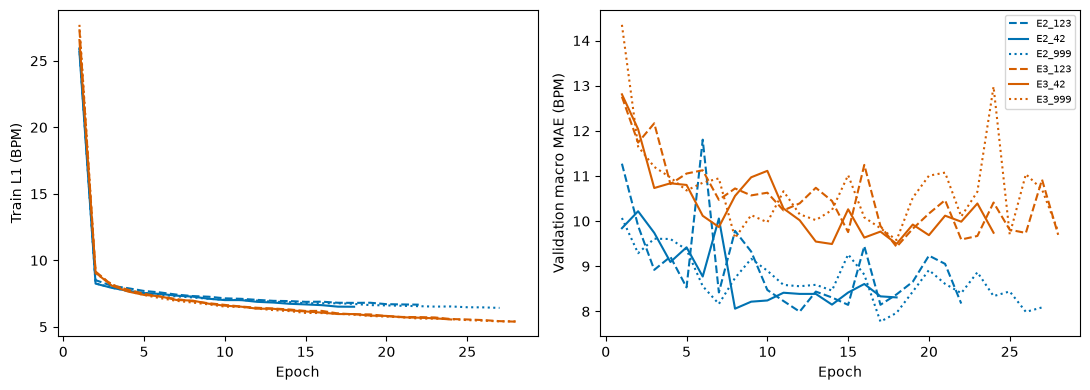

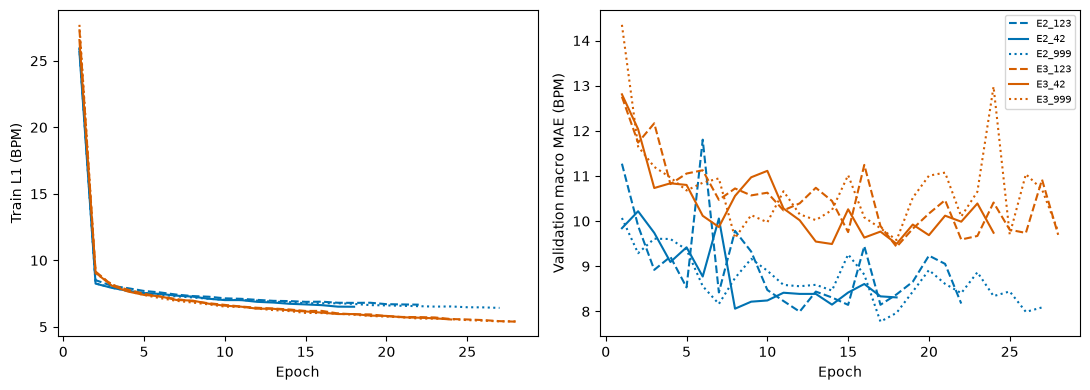

In [202]:
plot_training_history(PROJECT_DIR)

In [203]:
def plot_test_errors(frame):
    import matplotlib.pyplot as plt
    error = frame.hr_pred_bpm - frame.hr_ref_bpm
    average = (frame.hr_pred_bpm + frame.hr_ref_bpm) / 2
    bias, spread = float(error.mean()), float(error.std(ddof=1))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].hist(error, bins=50, color="#56B4E9", edgecolor="white")
    axes[0].set(xlabel="Predicted − ECG HR (BPM)", ylabel="Test windows")
    axes[1].scatter(average, error, s=7, alpha=.3, color="#0072B2")
    for value in (bias, bias-1.96*spread, bias+1.96*spread): axes[1].axhline(value, linestyle="--")
    axes[1].set(xlabel="Mean BPM", ylabel="Predicted − ECG HR (BPM)")
    fig.tight_layout()
    return fig

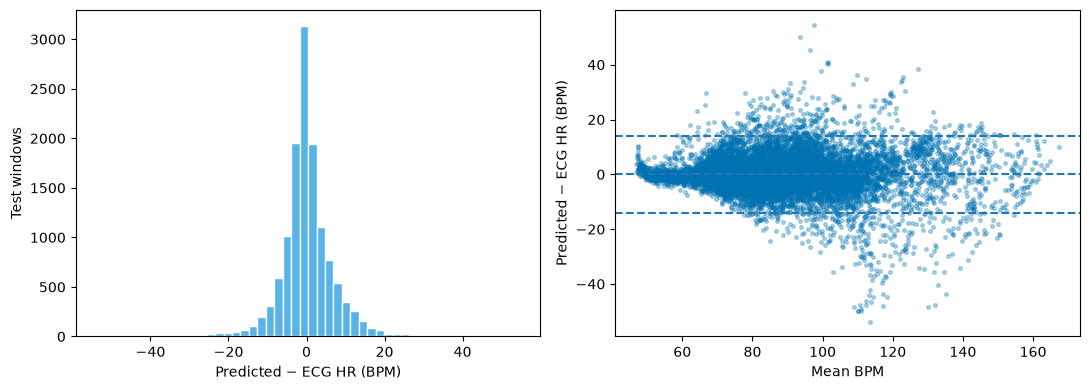

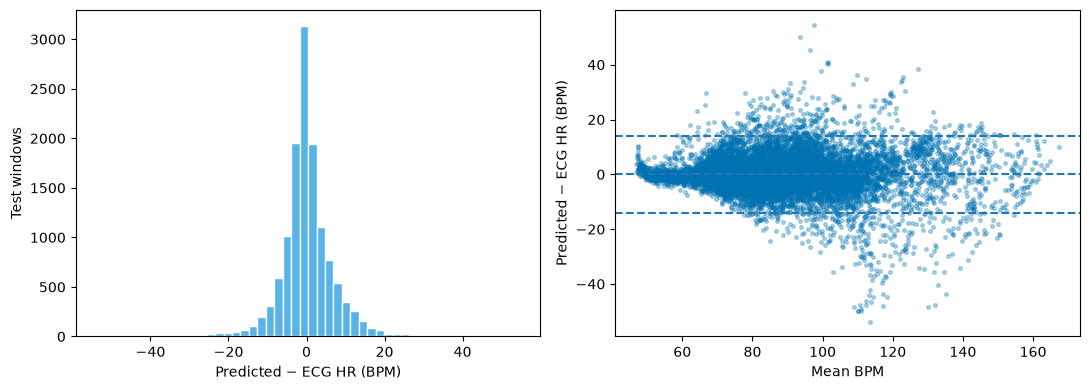

In [204]:
plot_test_errors(read_frame(PROJECT_DIR / read_json(PROJECT_DIR / 'results/final_test/index.json')['methods']['E3_42']['predictions']))

In [205]:
def plot_test_timeline(choice, index, root):
    import matplotlib.pyplot as plt
    frames = {key: read_frame(root / value["predictions"]) for key, value in index["methods"].items()}
    primary = frames.get("E3_42", next(iter(frames.values())))
    errors = primary.assign(error=abs(primary.hr_pred_bpm-primary.hr_ref_bpm))
    scores = errors.groupby("subject_id").error.mean()
    subject = scores.idxmin() if choice == "easy" else scores.idxmax()
    fig, ax = plt.subplots(figsize=(12, 4))
    palette = plt.get_cmap("tab10").colors
    for i, (key, frame) in enumerate(frames.items()):
        rows = frame.loc[frame.subject_id == subject].sort_values("start_s")
        ax.plot(rows.start_s/60, rows.hr_pred_bpm, label=key, color=palette[i%len(palette)], linewidth=.9)
    reference = primary.loc[primary.subject_id == subject].sort_values("start_s")
    ax.plot(reference.start_s/60, reference.hr_ref_bpm, label="ECG HR", color="#222222", linewidth=1.4)
    ax.set(xlabel="Time (min)", ylabel="BPM", title=f"{choice} observed Test subject {subject}")
    ax.legend(ncol=3)
    fig.tight_layout()
    return fig


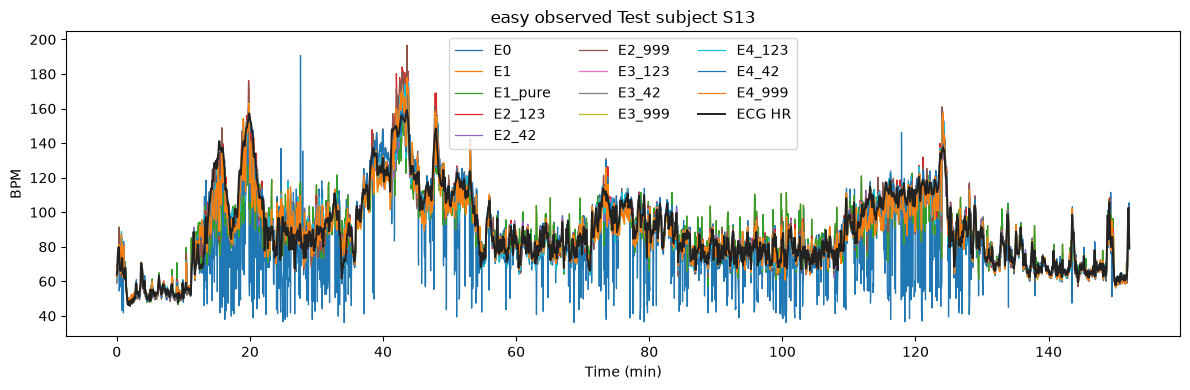

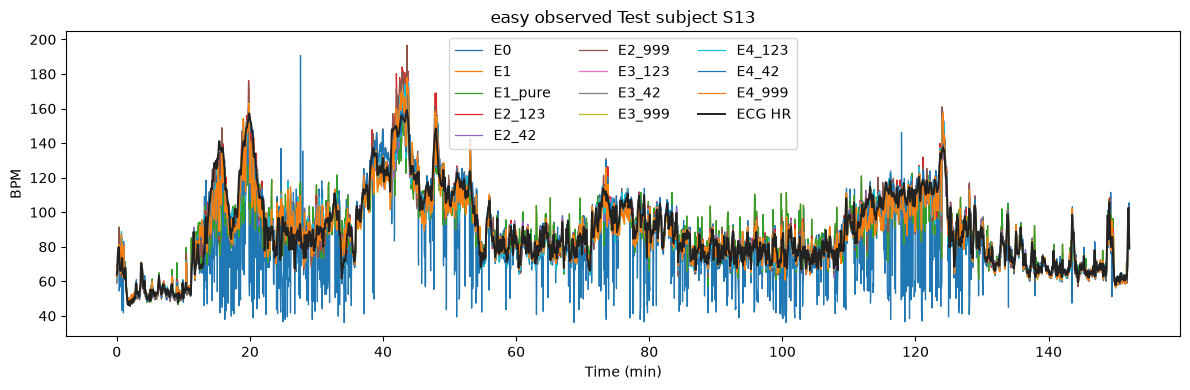

In [206]:
plot_test_timeline("easy", FINAL_TEST, PROJECT_DIR)


In [207]:
def plot_hard_test_timeline(index, root):
    return plot_test_timeline("hard", index, root)

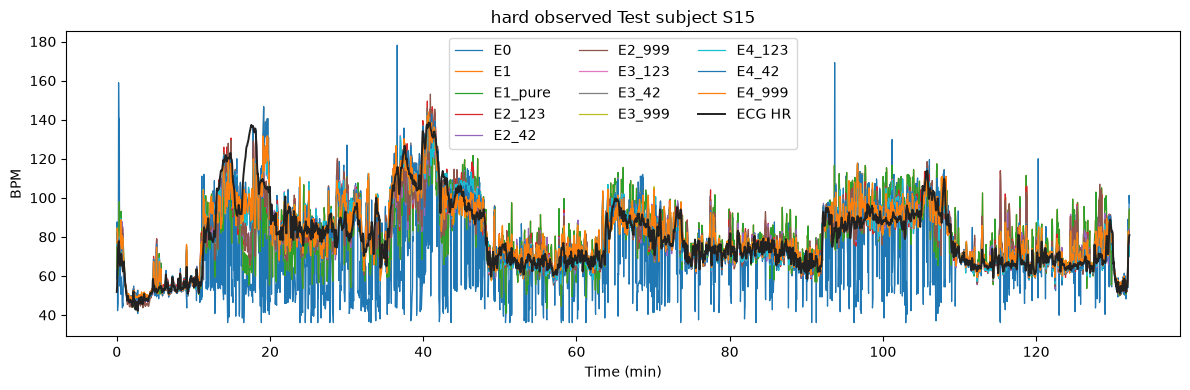

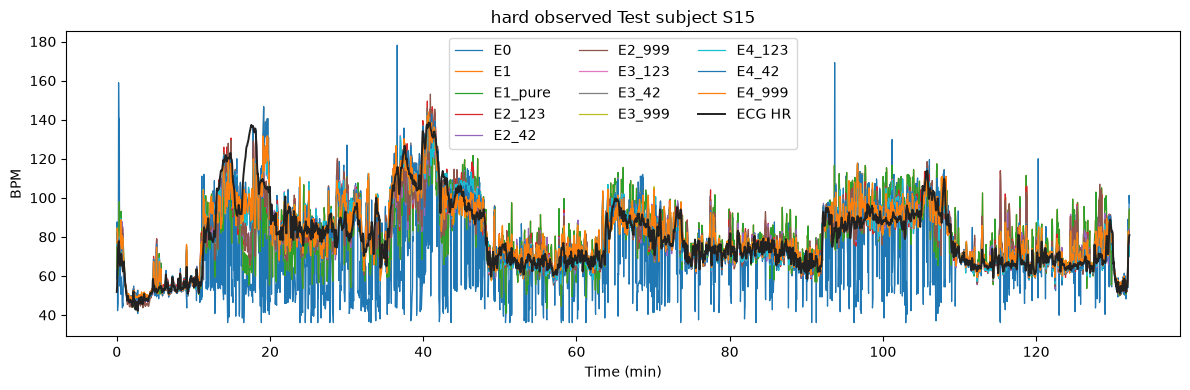

In [208]:
plot_test_timeline("hard", FINAL_TEST, PROJECT_DIR)


In [209]:
def plot_failure_case(case, ctx, predictions):
    import matplotlib.pyplot as plt
    row = ctx["manifest"].loc[ctx["manifest"].window_id == case["window_id"]].iloc[0]
    arrays = cached_arrays(ctx, row.subject_id); p0, p1 = int(row.ppg_start_idx), int(row.ppg_end_idx)
    times = row.start_s + np.arange(256)/32
    fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    axes[0].plot(times, arrays["ppg32"][p0:p1], color="#0072B2", label="filtered PPG")
    for axis, color in zip(range(3), ("#0072B2", "#E69F00", "#009E73")):
        axes[1].plot(times, arrays["acc32_normalized"][p0:p1, axis], color=color, label=f"ACC {axis}")
    axes[1].legend(); axes[0].legend()
    axes[1].set_xlabel("Time (s)"); axes[0].set_ylabel("Filtered PPG (source units)"); axes[1].set_ylabel("ACC Train z-score")
    axes[0].set_title(f"{case['rule']} · {row.subject_id}/{row.window_id} · ECG HR {row.hr_ref_bpm:.1f} BPM")
    fig.tight_layout()
    return fig

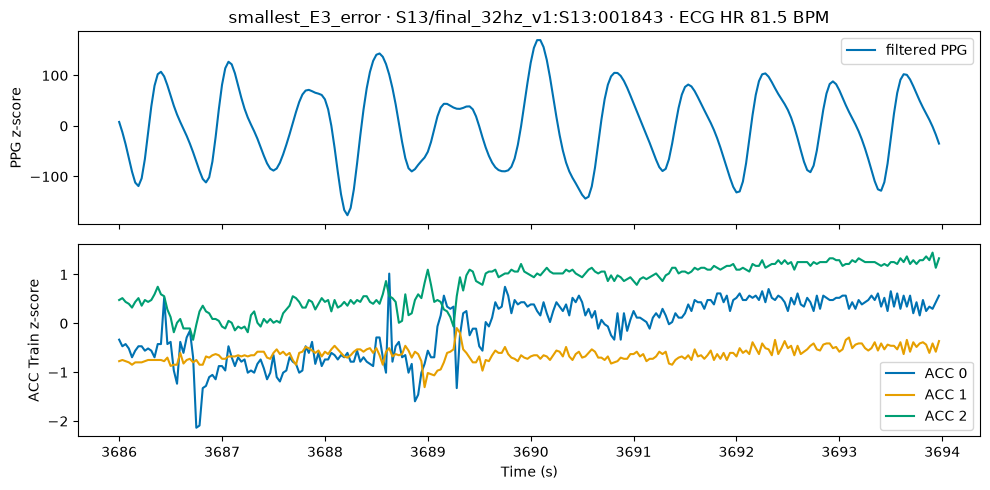

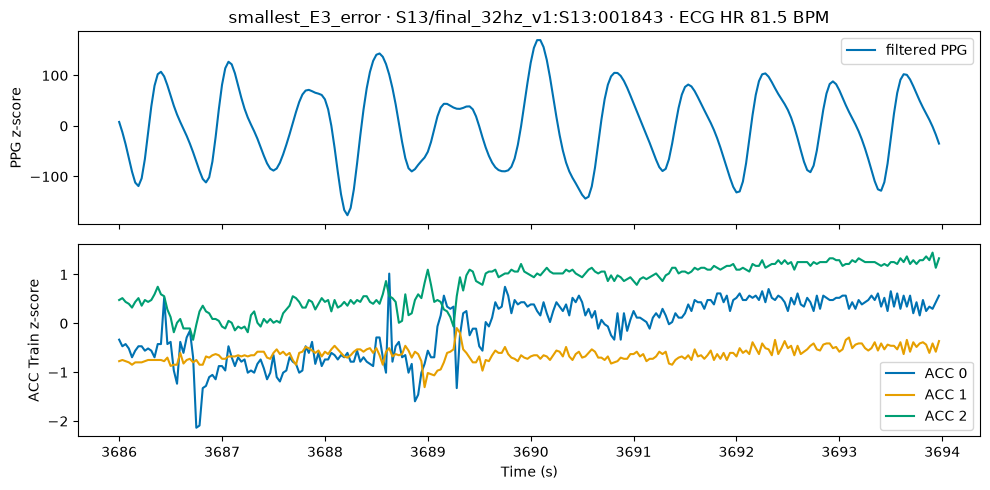

In [210]:
plot_failure_case(read_json(PROJECT_DIR / 'results/report/failure_cases.json')[0], CTX, None)

In [211]:
def plot_largest_error_case(report, ctx):
    return plot_failure_case(report[1], ctx, None)

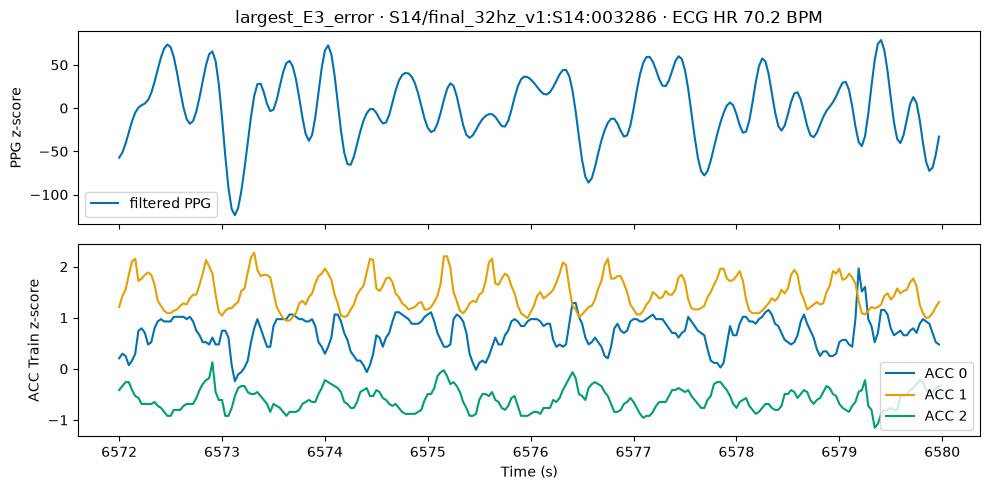

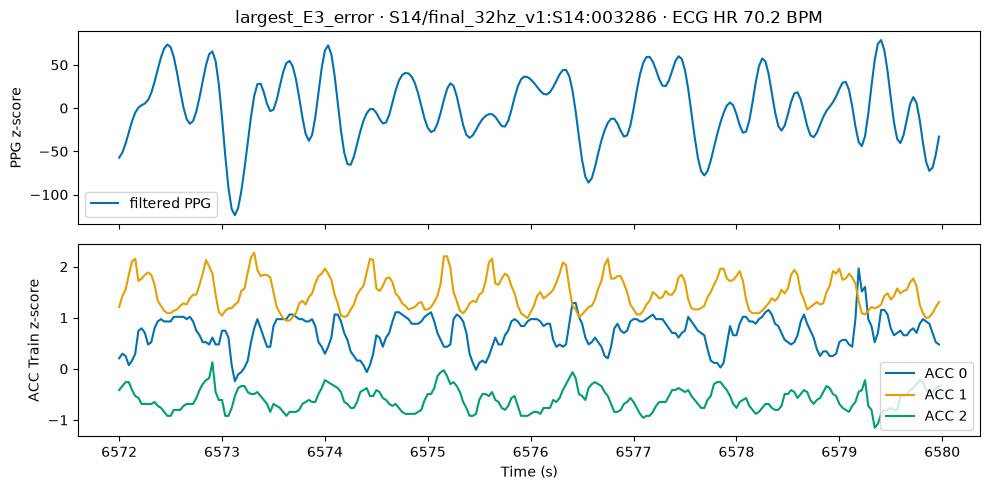

In [212]:
plot_largest_error_case(read_json(PROJECT_DIR / 'results/report/failure_cases.json'), CTX)

In [213]:
def plot_acc_failure_case(report, ctx):
    return plot_failure_case(report[2], ctx, None)

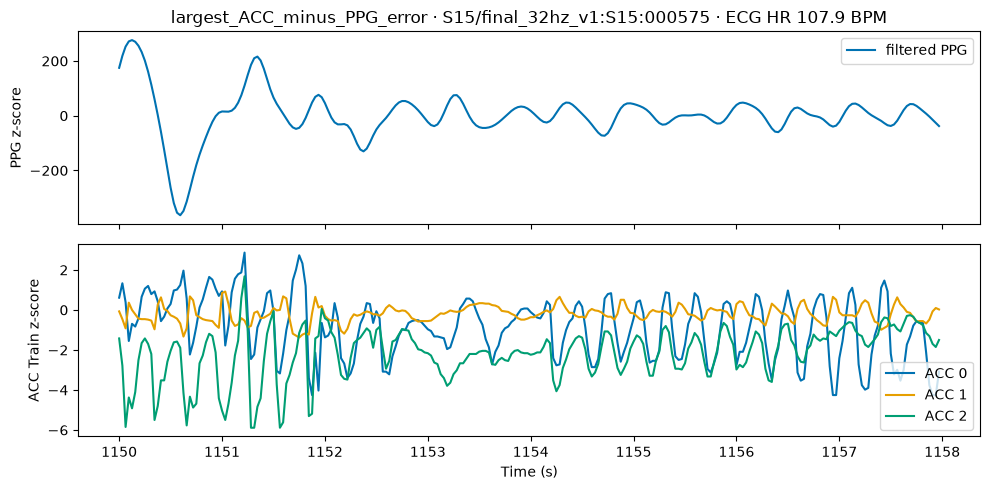

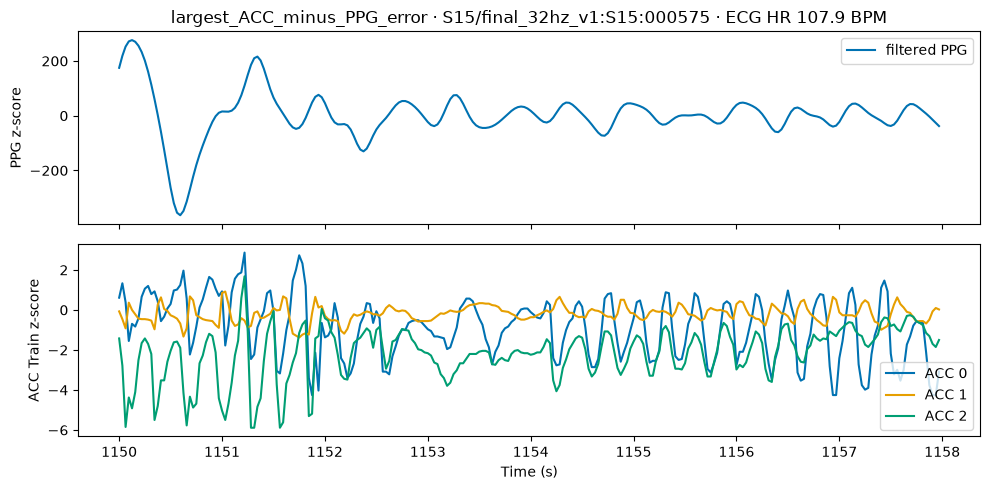

In [214]:
plot_acc_failure_case(read_json(PROJECT_DIR / 'results/report/failure_cases.json'), CTX)

In [215]:
def plot_ptq_failure_case(report, ctx):
    return plot_failure_case(report[3], ctx, None)

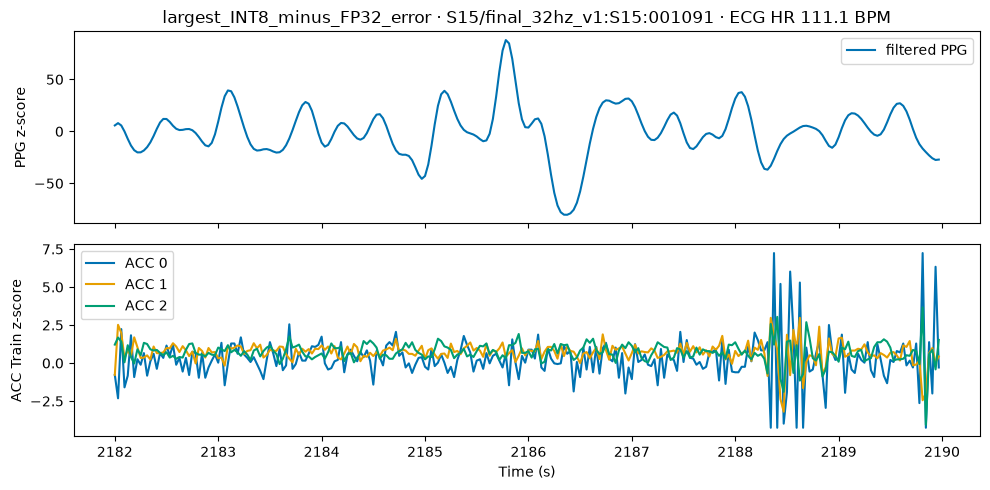

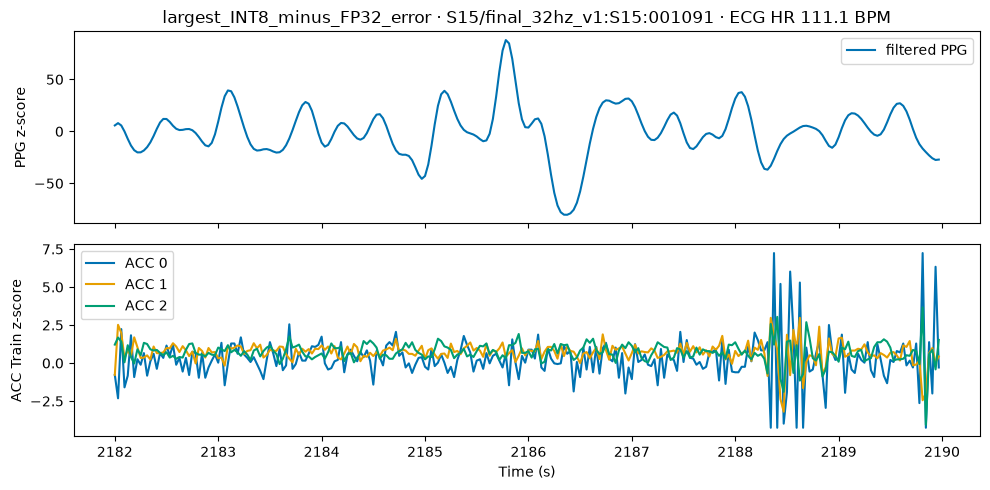

In [216]:
plot_ptq_failure_case(read_json(PROJECT_DIR / 'results/report/failure_cases.json'), CTX)

In [217]:
show_json("results/report/failure_cases.json")

[{'acc_minus_ppg_error_bpm': -3.4299850463867188,
  'e3_error_bpm': 0.0004596426927463426,
  'hr_ref_bpm': 81.4661541268385,
  'int8_minus_fp32_error_bpm': 0.4575920671535698,
  'predictions': {'E0': 79.6875,
   'E1': 83.11688311688312,
   'E2_42': 84.89659881591797,
   'E3_42': 81.46661376953125,
   'E4_42': 81.00810241699219},
  'rule': 'smallest_E3_error',
  'split': 'test',
  'subject_id': 'S13',
  'window_id': 'final_32hz_v1:S13:001843'},
 {'acc_minus_ppg_error_bpm': -1.3276519775390625,
  'e3_error_bpm': 54.55756050050469,
  'hr_ref_bpm': 70.24596733152656,
  'int8_minus_fp32_error_bpm': -0.17568206787109375,
  'predictions': {'E0': 51.5625,
   'E1': 121.08108108108108,
   'E2_42': 126.13117980957031,
   'E3_42': 124.80352783203125,
   'E4_42': 124.62784576416016},
  'rule': 'largest_E3_error',
  'split': 'test',
  'subject_id': 'S14',
  'window_id': 'final_32hz_v1:S14:003286'},
 {'acc_minus_ppg_error_bpm': 31.930694580078125,
  'e3_error_bpm': 38.46397310268779,
  'hr_ref_bpm': 

## 12. Trình diễn pipeline và firmware giả lập

### 12.1. Replay nội bộ của thực nghiệm notebook

Các bảng/hình bên dưới giữ kết quả **24 cửa sổ Validation S11** ngồi/đi bộ,
được tạo trong lần Run All05/10/2026. Replay dùng E3/E4 của run chính
`20261005T080438565912Z-f1bf0c7c` để kiểm luồng tín hiệu → tensor → BPM.
Kết quả Validation này tách khỏi đánh giá Test toàn tập và demo UI bên ngoài.

### 12.2. Demo Test dùng đúng model của kết quả chính

Giao diện Streamlit nạp artifact FP32/E3 hoặc INT8/E4 theo seed42/123/999,
kiểm SHA/parent checkpoint và thực hiện suy luận mới trên CPU.
Bundle giữ đủ **13.007 cửa sổ Test S13–S15**, tám hoạt động và các khoảng
chuyển tiếp. UI chọn người/hoạt động/đoạn/vị trí/model/seed, phát/dừng,
vẽ PPG/ACC/BPM bằng Matplotlib màu và hiển thị metrics/CPU benchmark cùng run.
HR từ ECG, hoạt động và ID chỉ phục vụ đối chiếu/truy vết, không đưa vào mạng.

Kiểm chứng ngoài notebook ngày05/10/2026 đối chiếu toàn bộ waveform với
continuous source: sai khác **0**. Quy tắc đầu/giữa/cuối mỗi đoạn người–hoạt động
chọn **153 cửa sổ**, tương ứng **918 lượt suy luận mới** qua6model.
FP32 lệch tối đa **0,00001526 BPM**, INT8 lệch **0 BPM** so với predictions
Test đã khóa, trong dung sai1e-4 BPM. **18/18 bài kiểm** đạt;
trọng số và phép đánh giá khoa học không thay đổi.

BPM vừa tính được truyền qua UART tới firmware ESP32 chạy trên Wokwi0.28.0.
Sáu cửa sổ Test E4seed42, ngồi/đi bộ của mỗi người S13–S15, đạt **6/6 ACK**
khớp window/split/model/seed/BPM/HR tham chiếu; LCD ILI9341 màu hiển thị
giá trị tương ứng. Browser Edge thật xác nhận SHA model mới, replay/seek,
chọn S13/S14/S15, các trang kết quả/phương pháp và gửi thêm một cửa sổ
S15/INT8 tới LCD. Ảnh UI/LCD lấy từ browser/simulator thực.

Bằng chứng mới nằm trong workspace chính, dưới `results/demo_final/`
và `results/demo_ui/firmware/`; bộ ảnh/tóm tắt chọn lọc tại `results/published/`
ở source repo. Bộ demo/model lịch sử được archive ngoài repo, không gộp
với kiểm chứng mới. Replay Test minh họa đánh giá đã khóa, không tạo tập
kiểm định độc lập mới hoặc thay MAE toàn Test bằng sai số đoạn đang xem.

AI thực thi trên CPU host; ESP32 chỉ parser/UART/LCD, chưa chạy mạng AI.
Lọc ngoại tuyến hai chiều và mạng cửa sổ padding đối xứng không là pipeline
streaming nhân quả. Simulator/CPU không cung cấp số đo latency, điện năng
hay bộ nhớ AI trên board thật.


In [218]:
def _demo_select_windows(frame,n_windows):
    indices=[]
    for activity in (1,7):
        positions=frame.index[frame.activity_id==activity].tolist()
        indices.extend(positions[:max(1,n_windows//2)])
    indices=list(dict.fromkeys(indices))
    if not indices: indices=list(range(min(n_windows,len(frame))))
    return indices[:n_windows]

In [219]:
def _demo_predict(ctx,selected,tensor,seed):
    training=read_json(ctx["root"]/"results/training_index.json")
    ptq=read_json(ctx["root"]/"results/ptq_index.json"); artifacts={}
    for experiment,registry in (("E3",training),("E4",ptq)):
        entry=registry["runs"][f"{experiment}_{seed}"]
        model=load_inference_model(ctx["root"]/entry["artifact"],entry["artifact_sha256"])
        selected[f"{experiment}_bpm"]=predict_tensor(model,tensor)
        selected[f"{experiment}_error_bpm"]=selected[f"{experiment}_bpm"]-selected.hr_ref_bpm
        artifacts[experiment]=entry["artifact_sha256"]
    return artifacts

In [220]:
def _demo_record_waveforms(selected,tensor):
    records=[]
    for index,row in enumerate(selected.to_dict("records")):
        records.append({"window_id":row["window_id"],"subject_id":row["subject_id"],"start_s":row["start_s"],
            "activity_id":None if pd.isna(row["activity_id"]) else int(row["activity_id"]),
            "hr_ref_bpm":row["hr_ref_bpm"],"E3_bpm":row["E3_bpm"],"E4_bpm":row["E4_bpm"],
            "ppg":tensor[index,0].tolist(),"acc":tensor[index,1:].tolist()})
    return records

In [221]:
def _demo_figures(ctx,selected,out,seed,speed):
    figures=[]
    for row in (selected.iloc[0],selected.iloc[-1]):
        values={name:float(row[f"{name}_bpm"]) for name in ("E3","E4")}
        title=f"Recorded Validation | CPU | seed={seed} | {speed}x | offline"
        path=plot_signal_case(ctx,row.to_dict(),values,out/f"replay_{row.label_index}.png",title)
        figures.append(path.relative_to(ctx["root"]).as_posix())
    return figures

In [222]:
def demo_stage(ctx,seed=42,n_windows=24,speed=1):
    x,_,frame=materialize_split(ctx,"validation","cpu")
    torch.set_num_threads(1)
    indices=_demo_select_windows(frame,n_windows)
    selected=frame.iloc[indices].copy(); tensor=x[indices]
    artifacts=_demo_predict(ctx,selected,tensor,seed)
    out=ctx["root"]/"results/demo"; out.mkdir(parents=True,exist_ok=True)
    selected.to_csv(out/"replay.csv",index=False)
    figures=_demo_figures(ctx,selected,out,seed,speed)
    write_json(out/"replay_windows.json",_demo_record_waveforms(selected,tensor))
    info={"passed":True,"split":"validation","seed":seed,"n_windows":len(selected),"speed":speed,
        "mode":"offline recorded replay","inference_platform":platform.platform(),
        "csv":"results/demo/replay.csv","data":"results/demo/replay_windows.json","figures":figures,
        "preprocess_hash":ctx["index"]["preprocess_hash"],"artifacts":artifacts}
    write_json(out/"index.json",info)
    return info

In [223]:
DEMO_RESULT = run_stage("demo")

C:\Users\GIGABYTE\AppData\Local\Temp\ipykernel_2180\2829711774.py:12: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  model.qconfig=get_default_qconfig(backend)


In [224]:
show_table("results/demo/replay.csv", limit=24)

,window_id,subject_id,split,label_index,start_s,end_s,ppg_start_idx,ppg_end_idx,acc_start_idx,acc_end_idx,...,dominant_activity_code,eligible,exclusion_reason,ppg_flat,source_sha256,preprocess_hash,E3_bpm,E3_error_bpm,E4_bpm,E4_error_bpm
0,final_32hz_v1:S11:000022,S11,validation,22,44,52,1408,1664,1408,1664,...,1,True,NaN,False,5c5c4c0308478df56e2f464810fa949abbf25450c9c934...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,89.754318,21.783732,89.316620,21.346033
1,final_32hz_v1:S11:000023,S11,validation,23,46,54,1472,1728,1472,1728,...,1,True,NaN,False,5c5c4c0308478df56e2f464810fa949abbf25450c9c934...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,82.889702,15.115127,82.392853,14.618278
2,final_32hz_v1:S11:000024,S11,validation,24,48,56,1536,1792,1536,1792,...,1,True,NaN,False,5c5c4c0308478df56e2f464810fa949abbf25450c9c934...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,78.295761,11.467704,78.238594,11.410536
3,final_32hz_v1:S11:000025,S11,validation,25,50,58,1600,1856,1600,1856,...,1,True,NaN,False,5c5c4c0308478df56e2f464810fa949abbf25450c9c934...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,70.745033,2.846135,70.622444,2.723546
4,final_32hz_v1:S11:000026,S11,validation,26,52,60,1664,1920,1664,1920,...,1,True,NaN,False,5c5c4c0308478df56e2f464810fa949abbf25450c9c934...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,70.499084,2.673884,70.622444,2.797243
5,final_32hz_v1:S11:000027,S11,validation,27,54,62,1728,1984,1728,1984,...,1,True,NaN,False,5c5c4c0308478df56e2f464810fa949abbf25450c9c934...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,69.076805,-0.713040,69.237694,-0.552151
6,final_32hz_v1:S11:000028,S11,validation,28,56,64,1792,2048,1792,2048,...,1,True,NaN,False,5c5c4c0308478df56e2f464810fa949abbf25450c9c934...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,67.352921,-4.364325,67.160561,-4.556685
7,final_32hz_v1:S11:000029,S11,validation,29,58,66,1856,2112,1856,2112,...,1,True,NaN,False,5c5c4c0308478df56e2f464810fa949abbf25450c9c934...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,68.735779,-0.198896,68.545311,-0.389364
8,final_32hz_v1:S11:000030,S11,validation,30,60,68,1920,2176,1920,2176,...,1,True,NaN,False,5c5c4c0308478df56e2f464810fa949abbf25450c9c934...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,66.423256,0.335506,66.468185,0.380435
9,final_32hz_v1:S11:000031,S11,validation,31,62,70,1984,2240,1984,2240,...,1,True,NaN,False,5c5c4c0308478df56e2f464810fa949abbf25450c9c934...,b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2...,62.755226,-1.800184,63.006298,-1.549113


In [225]:
show_json("results/demo/index.json")

{'artifacts': {'E3': 'a14ffe6005edffab60cf091e4f8d15846ac0b761d3289444cd26a89058286abf',
  'E4': '1e1124c5d3ff0f98d7168699d5f76a5a20f9e2d208f23faf7ea1c6c849d57a75'},
 'csv': 'results/demo/replay.csv',
 'data': 'results/demo/replay_windows.json',
 'figures': ['results/demo/replay_22.png', 'results/demo/replay_3436.png'],
 'inference_platform': 'Windows-10-10.0.26300-SP0',
 'mode': 'offline recorded replay',
 'n_windows': 24,
 'passed': True,
 'preprocess_hash': 'b8ddd18b640b2f2b5795baabb8b92ea5b8a1783001b0d2abf9827eb885bfa543',
 'seed': 42,
 'speed': 1,
 'split': 'validation'}

In [226]:
DEMO_WINDOWS = read_json(PROJECT_DIR / DEMO_RESULT["data"])

In [227]:
def plot_replay_window(windows, position):
    import matplotlib.pyplot as plt
    item = windows[position]; times = item["start_s"] + np.arange(256)/32
    fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    axes[0].plot(times, item["ppg"], color="#0072B2", label="PPG")
    for axis, color in zip(range(3), ("#0072B2", "#E69F00", "#009E73")):
        axes[1].plot(times, item["acc"][axis], color=color, label=f"ACC {axis}")
    axes[0].legend(); axes[1].legend()
    axes[0].set_title(f"{item['window_id']} · ECG {item['hr_ref_bpm']:.1f}, E3 {item['E3_bpm']:.1f}, E4 {item['E4_bpm']:.1f} BPM")
    axes[1].set_xlabel("Time (s)"); fig.tight_layout()
    return fig

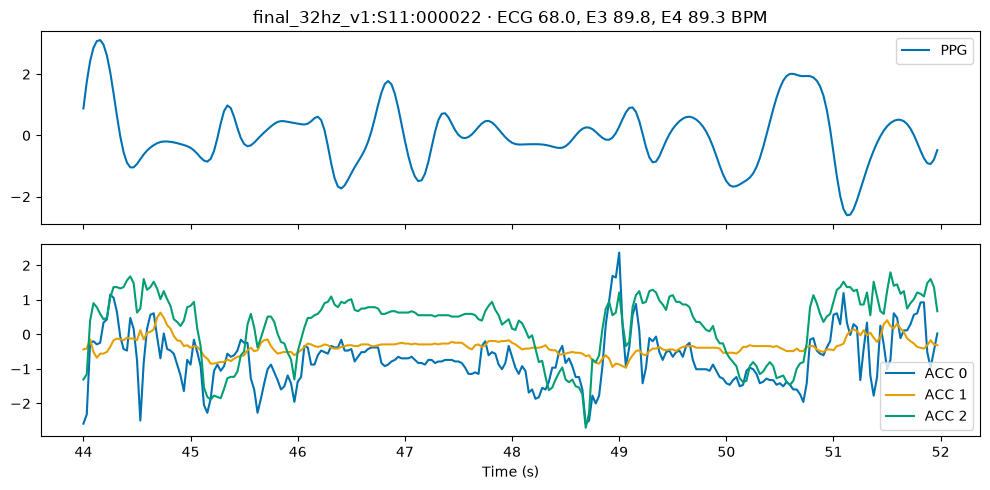

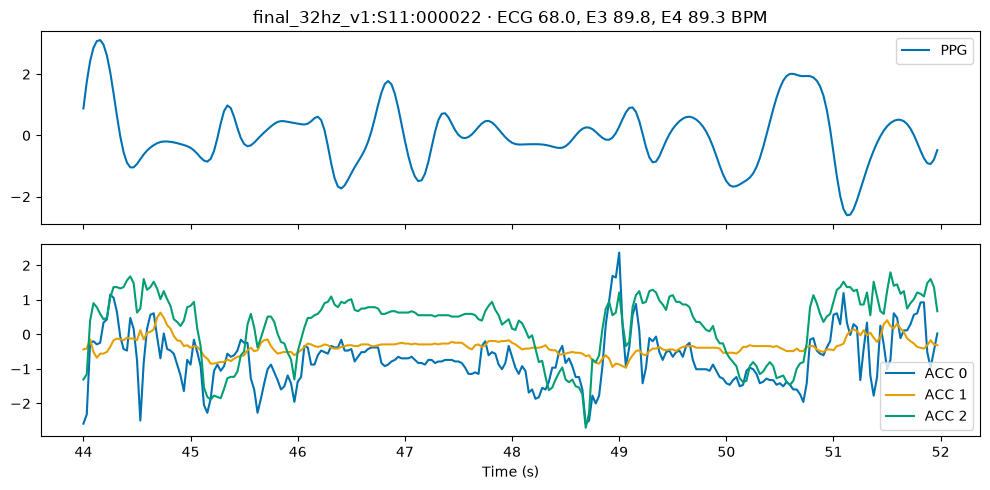

In [228]:
plot_replay_window(DEMO_WINDOWS, 0)

## 13. Kết quả, thảo luận và giới hạn nghiên cứu

Kết quả được xem xét theo ba nội dung nghiên cứu: khả năng ước lượng HR của
mạng nhỏ so với DSP, tác động của ACC và đánh đổi sau PTQ. Các phép so dùng
cùng cửa sổ Test, cùng nhãn tham chiếu và các cặp seed tương ứng.

Các bảng tổng hợp, biểu đồ theo hoạt động và trường hợp thất bại cung cấp
bằng chứng cho mức đạt chỉ tiêu thiết kế cũng như những giới hạn còn tồn tại.
Đặc biệt, đạt MAE mục tiêu không đồng nghĩa mọi hoạt động hoặc mọi cửa sổ
đều đạt cùng ngưỡng sai số, và tệp nhỏ không tự chứng minh khả năng chạy trên MCU.

Trong lần Run All 05/10/2026, năm ngưỡng thiết kế được đáp ứng: MAE E3
≤6,0 BPM; 25.000–35.000 tham số; tệp FP32 <150.000 byte; tỷ số dung lượng
FP32/INT8 ≥2,5; ΔMAE sau PTQ ≤0,5 BPM. Đóng góp được chứng minh trong
giao thức này là mạng nhỏ có MAE tổng thấp hơn FFT/IBI final32 và PTQ giảm
dung lượng với thay đổi MAE nhỏ. Lợi ích của ACC và tăng tốc INT8 không
nhất quán theo mọi seed/chỉ số; đạt ngưỡng tổng không chứng minh tất cả
hoạt động đều đạt 6,0 BPM. Benchmark Đ01 cùng giao thức vẫn chưa xác minh.


In [229]:
def project_status(ctx):
    files={"data":"results/data_inventory.json","preprocessing":"results/manifests/checks.json",
           "eda":"results/eda/index.json","baseline":"results/baselines/index.json",
           "training":"results/training_index.json","ptq":"results/ptq_index.json",
           "test":"results/final_test/index.json","benchmark":"results/benchmark/index.json",
           "figures":"results/report/index.json","demo":"results/demo/index.json"}
    rows=[]
    for phase,relative in files.items():
        path=ctx["root"]/relative; data=read_json(path) if path.exists() else {}
        rows.append({"phase":phase,"status":"verified" if data.get("passed") else "pending",
                     "evidence":relative if path.exists() else None})
    return pd.DataFrame(rows)

In [230]:
display(project_status(CTX))

,phase,status,evidence
0,data,verified,results/data_inventory.json
1,preprocessing,verified,results/manifests/checks.json
2,eda,verified,results/eda/index.json
3,baseline,verified,results/baselines/index.json
4,training,verified,results/training_index.json
5,ptq,verified,results/ptq_index.json
6,test,verified,results/final_test/index.json
7,benchmark,verified,results/benchmark/index.json
8,figures,verified,results/report/index.json
9,demo,verified,results/demo/index.json


In [231]:
status = read_json(PROJECT_DIR / "results/benchmark/index.json")
show_table(status["tables"]["target_status.csv"])
persist_outputs()

,target,value,limit,achieved
0,E3 Test macro MAE mean3seed <=6 BPM,4.816180,6.0,True
1,mean3seed E4-E3 MAE <=0.5 BPM,0.009996,0.5,True
2,FP32 seed 42 <150000 bytes,112373.000000,150000.0,True
3,Compression seed 42 >=2.5,2.814602,2.5,True
4,FP32 seed 123 <150000 bytes,112373.000000,150000.0,True
5,Compression seed 123 >=2.5,2.814602,2.5,True
6,FP32 seed 999 <150000 bytes,112373.000000,150000.0,True
7,Compression seed 999 >=2.5,2.814602,2.5,True
8,E4-E3 seed 42 <=0.5 BPM,-0.003918,0.5,True
9,E4-E3 seed 123 <=0.5 BPM,0.022339,0.5,True


### 13.1. Hiệu năng ước lượng HR trên Test

Bảng tổng hợp trình bày MAE, RMSE, tỷ lệ lỗi >10 BPM, coverage và số cửa sổ.
E2/E3/E4 báo mean ± sample std giữa ba seed; FFT/IBI là thuật toán xác định,
chỉ có một kết quả và không có std theo seed. Các số đo thuộc cùng bộ Test
S13–S15 của giao thức final32, với 13.007 cửa sổ mỗi lần chạy.

Biểu đồ so sánh phản ánh accuracy tổng thể và vị trí tương đối với mục tiêu
6,0 BPM. Đối chứng ACC và lượng tử hóa được phân tích riêng để xác định phần
đóng góp của từng thay đổi, thay vì quy toàn bộ cải thiện so DSP cho ACC.


In [232]:
def build_final_result_table(final, root):
    rows = []
    for method in ("E0", "E1", "E2", "E3", "E4"):
        keys = [method] if method in ("E0", "E1") else [f"{method}_{s}" for s in (42,123,999)]
        metrics = [read_json(root/final["methods"][key]["metrics"])["overall"] for key in keys]
        counts = [m["pooled_window"]["n_total"] for m in metrics]
        if len(set(counts)) != 1: raise ValueError("Seed window populations differ")
        row = {"method": method, "n_seeds": len(keys) if method not in ("E0","E1") else None,
               "Test_windows_per_run": counts[0], "coverage": min(m["pooled_window"]["coverage"] for m in metrics)}
        for name in ("mae_bpm", "rmse_bpm", "error_gt_10_percent"):
            values = [m["macro_subject"][name] for m in metrics]
            row[name+"_mean"] = float(np.mean(values))
            row[name+"_sample_std"] = float(np.std(values, ddof=1)) if len(values)>1 else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


In [233]:
FINAL_RESULT_TABLE = build_final_result_table(FINAL_TEST, PROJECT_DIR)
FINAL_SEED_SUMMARY = read_json(PROJECT_DIR / FINAL_TEST["summary"])
display(FINAL_RESULT_TABLE.round(3))


,method,n_seeds,Test_windows_per_run,coverage,mae_bpm_mean,mae_bpm_sample_std,rmse_bpm_mean,rmse_bpm_sample_std,error_gt_10_percent_mean,error_gt_10_percent_sample_std
0,E0,NaN,13007,1.0,11.191,NaN,20.698,NaN,26.709,NaN
1,E1,NaN,13007,1.0,6.970,NaN,10.988,NaN,23.553,NaN
2,E2,3.0,13007,1.0,4.768,0.080,7.579,0.138,12.204,0.682
3,E3,3.0,13007,1.0,4.816,0.119,7.321,0.149,12.420,0.575
4,E4,3.0,13007,1.0,4.826,0.127,7.326,0.158,12.417,0.573


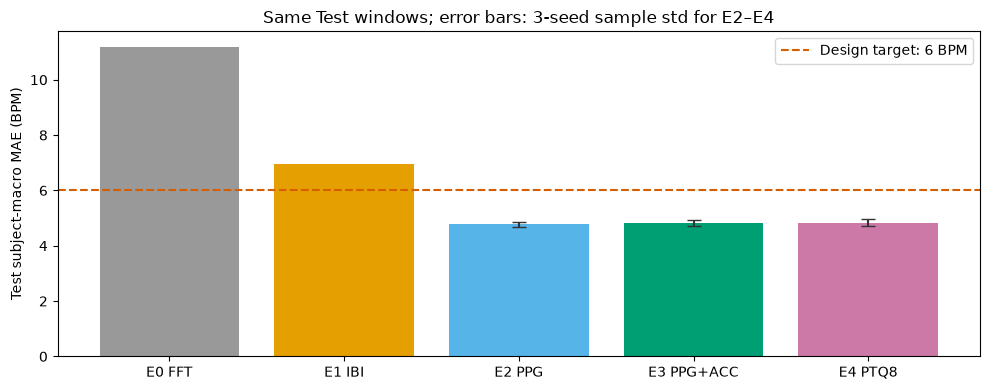

In [234]:
fig, ax = plt.subplots(figsize=(10, 4)); positions = np.arange(5)
ax.bar(positions, FINAL_RESULT_TABLE.mae_bpm_mean, color=["#999999", "#E69F00", "#56B4E9", "#009E73", "#CC79A7"])
ax.errorbar(positions[2:], FINAL_RESULT_TABLE.mae_bpm_mean.iloc[2:], yerr=FINAL_RESULT_TABLE.mae_bpm_sample_std.iloc[2:], fmt="none", ecolor="#333333", capsize=5)
ax.axhline(6, color="#D55E00", linestyle="--", label="Design target: 6 BPM")
ax.set(xticks=positions, xticklabels=["E0 FFT", "E1 IBI", "E2 PPG", "E3 PPG+ACC", "E4 PTQ8"], ylabel="Test subject-macro MAE (BPM)", title="Same Test windows; error bars: 3-seed sample std for E2–E4")
ax.legend(); fig.tight_layout(); fig.savefig(FIGURE_DIR / "final_method_mae.png", dpi=160); plt.show()


### 13.2. Đánh giá đóng góp của ACC

$$\Delta_{ACC}=MAE(E3)-MAE(E2).$$

Giá trị âm phản ánh PPG+ACC tốt hơn PPG-only; giá trị dương phản ánh sai số tăng.
Các chênh lệch theo seed và hoạt động cho biết mức nhất quán của dung hợp.
ACC có thể cung cấp thông tin về cường độ hoạt động, nên đối chứng sai số HR
chưa tách riêng cơ chế khử nhiễu dạng sóng khỏi lợi ích dự đoán nhờ ngữ cảnh chuyển động.


In [235]:
SENSOR_DELTA = pd.DataFrame({"seed": [42,123,999], "E2_mae_bpm": FINAL_SEED_SUMMARY["E2"]["mae_bpm"]["values"],
                           "E3_mae_bpm": FINAL_SEED_SUMMARY["E3"]["mae_bpm"]["values"], "E3_minus_E2_bpm": FINAL_SEED_SUMMARY["delta_E3_minus_E2"]["values"]})
PTQ_DELTA = pd.DataFrame({"seed": [42,123,999], "E4_mae_bpm": FINAL_SEED_SUMMARY["E4"]["mae_bpm"]["values"],
                        "E4_minus_E3_bpm": FINAL_SEED_SUMMARY["delta_E4_minus_E3"]["values"]})
display(SENSOR_DELTA.merge(PTQ_DELTA, on="seed").round(4))


,seed,E2_mae_bpm,E3_mae_bpm,E3_minus_E2_bpm,E4_mae_bpm,E4_minus_E3_bpm
0,42,4.7100,4.7017,-0.0083,4.6978,-0.0039
1,123,4.8598,4.8073,-0.0524,4.8297,0.0223
2,999,4.7354,4.9395,0.2041,4.9511,0.0116


In [236]:
def build_activity_result_table(final, root):
    rows = []
    names = ["E0", "E1"] + [f"{e}_{s}" for e in ("E2","E3","E4") for s in (42,123,999)]
    for name in names:
        method = name.split("_")[0]
        for activity in read_json(root/final["methods"][name]["metrics"])["by_activity"]:
            if activity["activity_id"] is None: continue
            rows.append({"method": method, "activity": activity["activity"],
                "mae_bpm": activity["macro_subject"]["mae_bpm"],
                "n_windows": activity["pooled_window"]["n_total"],
                "n_subjects": activity["macro_subject"]["n_subjects_with_data"]})
    grouped = pd.DataFrame(rows).groupby(["method","activity"], sort=False)
    return grouped.agg(mae_mean=("mae_bpm","mean"), mae_sample_std=("mae_bpm","std"),
        n_windows_per_run=("n_windows","min"), n_subjects=("n_subjects","min")).reset_index()


In [237]:
ACTIVITY_RESULT_TABLE = build_activity_result_table(FINAL_TEST, PROJECT_DIR)
ACTIVITY_ORDER = ["sitting", "stairs", "table_soccer", "cycling", "driving", "lunch", "walking", "working"]
ACTIVITY_MAE = ACTIVITY_RESULT_TABLE.pivot(index="method", columns="activity", values="mae_mean").reindex(columns=ACTIVITY_ORDER)
display(ACTIVITY_RESULT_TABLE.round(3))
display((ACTIVITY_MAE.loc["E3"] - ACTIVITY_MAE.loc["E2"]).rename("mean_E3_minus_E2_bpm").to_frame().round(3))


,method,activity,mae_mean,mae_sample_std,n_windows_per_run,n_subjects
0,E0,sitting,1.090,NaN,905,3
1,E0,stairs,26.014,NaN,678,3
2,E0,table_soccer,17.621,NaN,478,3
3,E0,cycling,15.237,NaN,696,3
4,E0,driving,7.190,NaN,1312,3
5,E0,lunch,9.258,NaN,2593,3
6,E0,walking,21.808,NaN,984,3
7,E0,working,4.297,NaN,1810,3
8,E1,sitting,1.550,NaN,905,3
9,E1,stairs,17.765,NaN,678,3


,mean_E3_minus_E2_bpm
activity,
sitting,-0.036
stairs,0.921
table_soccer,0.810
cycling,-1.419
driving,0.434
lunch,0.157
walking,0.400
working,-0.932


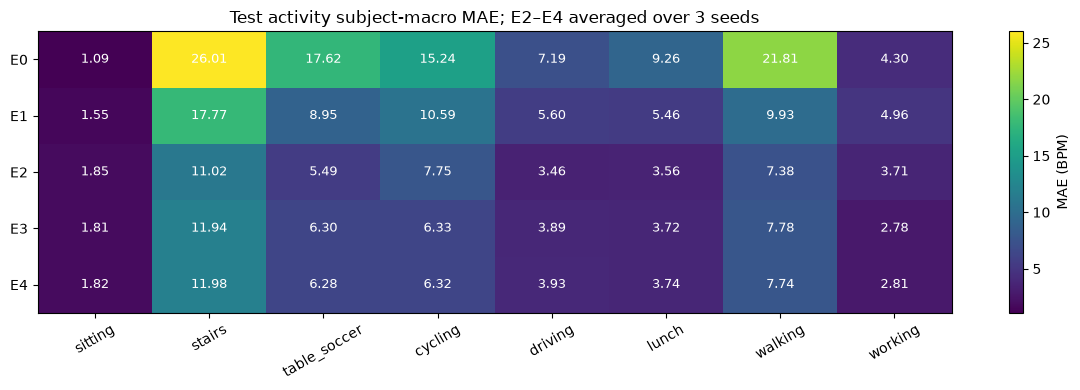

In [238]:
fig, ax = plt.subplots(figsize=(12, 4)); image = ax.imshow(ACTIVITY_MAE.values, aspect="auto", cmap="viridis")
ax.set(xticks=np.arange(8), xticklabels=ACTIVITY_ORDER, yticks=np.arange(5), yticklabels=ACTIVITY_MAE.index, title="Test activity subject-macro MAE; E2–E4 averaged over 3 seeds")
for row, column in np.ndindex(ACTIVITY_MAE.shape):
    ax.text(column, row, f"{ACTIVITY_MAE.iloc[row,column]:.2f}", ha="center", va="center", color="white", fontsize=9)
ax.tick_params(axis="x", rotation=30); fig.colorbar(image, ax=ax, label="MAE (BPM)")
fig.tight_layout(); fig.savefig(FIGURE_DIR / "final_activity_mae.png", dpi=160); plt.show()


Ngưỡng 6,0 BPM áp dụng cho macro tổng trên Test, không áp dụng riêng cho mọi
hoạt động. Mỗi nhóm có số cửa sổ và số người thực tế; mixed/transition và
unknown vẫn nằm trong overall. Phân rã hoạt động là phân tích mô tả sau đánh
giá cuối, với cấu hình và checkpoint giữ nguyên.


In [239]:
ACTIVITY_ACC_DELTA = ACTIVITY_MAE.loc["E3"] - ACTIVITY_MAE.loc["E2"]
ACTIVITY_ACC_BETTER = ", ".join(ACTIVITY_ACC_DELTA.index[ACTIVITY_ACC_DELTA < 0])
ACTIVITY_ACC_WORSE = ", ".join(ACTIVITY_ACC_DELTA.index[ACTIVITY_ACC_DELTA > 0])
display(Markdown(f"""**Theo hoạt động:** mean E3 tốt hơn E2 ở **{ACTIVITY_ACC_BETTER}**, kém hơn ở **{ACTIVITY_ACC_WORSE}**.
Cầu thang: FFT **{ACTIVITY_MAE.loc['E0','stairs']:.2f}** → E3 **{ACTIVITY_MAE.loc['E3','stairs']:.2f} BPM**; đi bộ: FFT **{ACTIVITY_MAE.loc['E0','walking']:.2f}** → E3 **{ACTIVITY_MAE.loc['E3','walking']:.2f} BPM**.
Khi ngồi, FFT **{ACTIVITY_MAE.loc['E0','sitting']:.2f}** vẫn tốt hơn E3 **{ACTIVITY_MAE.loc['E3','sitting']:.2f} BPM** ở lần chạy này. Mạng tốt hơn về MAE tổng không có nghĩa tốt hơn DSP ở mọi hoạt động.
Các số này là phân rã mô tả sau Test; không dùng để chọn lại kiến trúc/checkpoint hoặc chứng minh ACC khử nhiễu."""))


**Theo hoạt động:** mean E3 tốt hơn E2 ở **sitting, cycling, working**, kém hơn ở **stairs, table_soccer, driving, lunch, walking**.
Cầu thang: FFT **26.01** → E3 **11.94 BPM**; đi bộ: FFT **21.81** → E3 **7.78 BPM**.
Khi ngồi, FFT **1.09** vẫn tốt hơn E3 **1.81 BPM** ở lần chạy này. Mạng tốt hơn về MAE tổng không có nghĩa tốt hơn DSP ở mọi hoạt động.
Các số này là phân rã mô tả sau Test; không dùng để chọn lại kiến trúc/checkpoint hoặc chứng minh ACC khử nhiễu.

### 13.3. Đánh đổi accuracy–dung lượng–latency sau PTQ

$$\Delta_{PTQ}=MAE(E4)-MAE(E3).$$

Phép so accuracy được ghép theo seed trên cùng Test. Tỷ số byte sử dụng hai tệp
suy luận model-only tương ứng. Speedup mean/median được tính bằng thời gian
FP32 chia thời gian INT8: giá trị >1 phản ánh INT8 nhanh hơn, <1 phản ánh chậm hơn.
Các kết quả mean, median và p95 cung cấp góc nhìn riêng về biến thiên thời gian
thay vì suy ra tăng tốc đồng đều từ một chỉ số duy nhất.


In [240]:
PTQ_RESOURCE_PAIRS = read_frame(PROJECT_DIR / CPU_BENCHMARK["tables"]["paired_benchmark.csv"])
PTQ_RESULT_TABLE = PTQ_RESOURCE_PAIRS.merge(PTQ_DELTA, on="seed")
PTQ_RESULT_TABLE["fp32_KB"] = PTQ_RESULT_TABLE.fp32_bytes / 1000
PTQ_RESULT_TABLE["int8_KB"] = PTQ_RESULT_TABLE.int8_bytes / 1000
display(PTQ_RESULT_TABLE.round(4))
display(CPU_BENCHMARK["runtime"])


,seed,fp32_bytes,int8_bytes,compression_ratio,speedup_median,speedup_mean,E4_mae_bpm,E4_minus_E3_bpm,fp32_KB,int8_KB
0,42,112373,39925,2.8146,1.1917,1.1164,4.6978,-0.0039,112.373,39.925
1,123,112373,39925,2.8146,1.1326,0.9131,4.8297,0.0223,112.373,39.925
2,999,112373,39925,2.8146,1.1893,1.1242,4.9511,0.0116,112.373,39.925


{'benchmark_device': 'cpu',
 'cpu': '12th Gen Intel(R) Core(TM) i5-12450H',
 'os': 'Microsoft Windows 11 Home Single Language',
 'processor_identifier': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel',
 'platform_python': 'Windows-10-10.0.26300-SP0',
 'platform': 'Microsoft Windows 11 Home Single Language',
 'python': '3.11.15',
 'torch': '2.10.0+cu126',
 'backend': 'onednn',
 'threads': 1,
 'protocol_sha256': 'bd5fe15f95ff09b790867ff7488010809091ffb20a9e67efef67917cb72d7714',
 'window_ids_sha256': '8d763042ed83819a3d7f17f853f9c83d0b7f85bd54ef77be6ca16530dab3a401'}

In [241]:
def describe_final_results(table, sensor, quantization, pairs):
        scores = table.set_index("method")
        e3, e4 = scores.loc["E3"], scores.loc["E4"]
        fft_reduction = 100*(1-e3.mae_bpm_mean/scores.loc["E0","mae_bpm_mean"])
        ibi_reduction = 100*(1-e3.mae_bpm_mean/scores.loc["E1","mae_bpm_mean"])
        better = int((sensor.E3_minus_E2_bpm < 0).sum())
        slower = pairs.loc[pairs.speedup_mean < 1,"seed"].astype(str).tolist()
        timing_note = "INT8 chậm hơn theo mean ở seed " + ", ".join(slower) if slower else "INT8 nhanh hơn theo mean ở cả ba seed trong phép đo này"
        return Markdown(f"""
**Mạng nhẹ:** E3 đạt **{e3.mae_bpm_mean:.3f} ± {e3.mae_bpm_sample_std:.3f} BPM**, E4 đạt **{e4.mae_bpm_mean:.3f} ± {e4.mae_bpm_sample_std:.3f} BPM** (Test macro, sample std giữa 3 seed).
Mục tiêu 6 BPM: **{'đạt' if e3.mae_bpm_mean <= 6 else 'không đạt'}** cho mean E3 trong giao thức này; coverage {e3.coverage:.1%}, {int(e3.Test_windows_per_run):,} cửa sổ/seed.
E3 RMSE macro **{e3.rmse_bpm_mean:.3f} BPM**, tỷ lệ lỗi >10 BPM macro trung bình **{e3.error_gt_10_percent_mean:.2f}%**. MAE là trung bình, không là chặn trên sai số từng cửa sổ.

**So DSP cùng giao thức:** E3 giảm MAE tổng **{fft_reduction:.2f}%** so FFT E0 và **{ibi_reduction:.2f}%** so IBI E1.
Đây là so baseline final32 mới, **không xác nhận tái lập benchmark Đ01 cũ**; từng hoạt động có thể bất lợi cho mạng.

**Tác động ACC:** mean E3−E2 = **{sensor.E3_minus_E2_bpm.mean():+.4f} BPM**, E3 tốt hơn E2 ở **{better}/3 seed**.
Lợi ích ACC chưa nhất quán giữa các seed; đối chứng sai số HR chưa xác lập cơ chế khử nhiễu PPG hoặc ý nghĩa thống kê trên quần thể.

**PTQ:** mean E4−E3 = **{quantization.E4_minus_E3_bpm.mean():+.4f} BPM**; mọi cặp seed {'đạt' if (quantization.E4_minus_E3_bpm <= .5).all() else 'không cùng đạt'} ngưỡng tăng 0,5 BPM.
FP32 **{int(pairs.fp32_bytes.iloc[0]):,} byte**, INT8 **{int(pairs.int8_bytes.iloc[0]):,} byte**, tỷ số **{pairs.compression_ratio.min():.3f}–{pairs.compression_ratio.max():.3f} lần**.
Median speedup **{pairs.speedup_median.min():.3f}–{pairs.speedup_median.max():.3f} lần**; **{timing_note}**. Kết quả mean và median cho thấy tăng tốc chưa đồng đều.

**Giá trị đạt được:** một mạng nhỏ hồi quy HR từ PPG/ACC và đánh giá PTQ8 bằng accuracy, byte và timing thực, bao gồm các trường hợp bất lợi.
Đây là benchmark host CPU với DSP ngoại tuyến; chưa là bằng chứng triển khai AI/latency/RAM/Flash/năng lượng trên MCU, LOSO hay hiệu quả chẩn đoán.
""")


In [242]:
display(describe_final_results(FINAL_RESULT_TABLE, SENSOR_DELTA, PTQ_DELTA, PTQ_RESOURCE_PAIRS))
show_table(CPU_BENCHMARK["tables"]["target_status.csv"])



**Mạng nhẹ:** E3 đạt **4.816 ± 0.119 BPM**, E4 đạt **4.826 ± 0.127 BPM** (Test macro, sample std giữa 3 seed).
Mục tiêu 6 BPM: **đạt** cho mean E3 trong giao thức này; coverage 100.0%, 13,007 cửa sổ/seed.
E3 RMSE macro **7.321 BPM**, tỷ lệ lỗi >10 BPM macro trung bình **12.42%**. MAE là trung bình, không là chặn trên sai số từng cửa sổ.

**So DSP cùng giao thức:** E3 giảm MAE tổng **56.96%** so FFT E0 và **30.91%** so IBI E1.
Đây là so baseline final32 mới, **không xác nhận tái lập benchmark Đ01 cũ**; từng hoạt động có thể bất lợi cho mạng.

**Tác động ACC:** mean E3−E2 = **+0.0478 BPM**, E3 tốt hơn E2 ở **2/3 seed**.
Lợi ích ACC chưa nhất quán giữa các seed; đối chứng sai số HR chưa xác lập cơ chế khử nhiễu PPG hoặc ý nghĩa thống kê trên quần thể.

**PTQ:** mean E4−E3 = **+0.0100 BPM**; mọi cặp seed đạt ngưỡng tăng 0,5 BPM.
FP32 **112,373 byte**, INT8 **39,925 byte**, tỷ số **2.815–2.815 lần**.
Median speedup **1.133–1.192 lần**; **INT8 chậm hơn theo mean ở seed 123**. Kết quả mean và median cho thấy tăng tốc chưa đồng đều.

**Giá trị đạt được:** một mạng nhỏ hồi quy HR từ PPG/ACC và đánh giá PTQ8 bằng accuracy, byte và timing thực, bao gồm các trường hợp bất lợi.
Đây là benchmark host CPU với DSP ngoại tuyến; chưa là bằng chứng triển khai AI/latency/RAM/Flash/năng lượng trên MCU, LOSO hay hiệu quả chẩn đoán.


,target,value,limit,achieved
0,E3 Test macro MAE mean3seed <=6 BPM,4.816180,6.0,True
1,mean3seed E4-E3 MAE <=0.5 BPM,0.009996,0.5,True
2,FP32 seed 42 <150000 bytes,112373.000000,150000.0,True
3,Compression seed 42 >=2.5,2.814602,2.5,True
4,FP32 seed 123 <150000 bytes,112373.000000,150000.0,True
5,Compression seed 123 >=2.5,2.814602,2.5,True
6,FP32 seed 999 <150000 bytes,112373.000000,150000.0,True
7,Compression seed 999 >=2.5,2.814602,2.5,True
8,E4-E3 seed 42 <=0.5 BPM,-0.003918,0.5,True
9,E4-E3 seed 123 <=0.5 BPM,0.022339,0.5,True


### 13.4. Phân tích trường hợp bất lợi

Các case gồm cửa sổ E3 lỗi thấp/cao nhất và cửa sổ ACC/PTQ làm sai số tăng nhiều
nhất. Chênh lệch MAE trung bình nhỏ sau PTQ có thể đồng thời tồn tại với biến
động lớn hơn ở một số cửa sổ. Sai số theo hoạt động, đặc biệt ở cầu thang và
đi bộ, phản ánh những khó khăn còn lại sau cải thiện so với FFT.

PPG/ACC và HR tham chiếu trong các hình cung cấp bằng chứng quan sát cho từng
ca. Nhiễu chuyển động hoặc nhầm thành phần phổ là các giả thuyết giải thích,
chưa được xác nhận là cơ chế gây lỗi riêng của mạng bởi đối chứng hiện tại.


In [243]:
FAILURE_RESULTS = pd.DataFrame(read_json(PROJECT_DIR / "results/report/failure_cases.json"))
display(FAILURE_RESULTS[["rule", "window_id", "subject_id", "hr_ref_bpm", "e3_error_bpm",
                         "acc_minus_ppg_error_bpm", "int8_minus_fp32_error_bpm"]].round(3))


,rule,window_id,subject_id,hr_ref_bpm,e3_error_bpm,acc_minus_ppg_error_bpm,int8_minus_fp32_error_bpm
0,smallest_E3_error,final_32hz_v1:S13:001843,S13,81.466,0.000,-3.430,0.458
1,largest_E3_error,final_32hz_v1:S14:003286,S14,70.246,54.558,-1.328,-0.176
2,largest_ACC_minus_PPG_error,final_32hz_v1:S15:000575,S15,107.931,38.464,31.931,0.389
3,largest_INT8_minus_FP32_error,final_32hz_v1:S15:001091,S15,111.069,0.310,-11.373,2.055


### 13.5. Giới hạn và hướng phát triển

Nghiên cứu sử dụng 15 người trong PPG-DaLiA, với ba người Test của split kế
thừa. Các cửa sổ chồng lấn không độc lập; biến thiên giữa ba seed phản ánh quá
trình học, không thay thế đánh giá trên quần thể lớn hoặc LOSO trên 15 người.

Tiền xử lý zero-phase trên toàn bản ghi là ngoại tuyến. Kích thước artifact
và thời gian mạng trên CPU chưa mô tả RAM đỉnh, Flash toàn chương trình,
năng lượng hoặc độ trễ end-to-end trên MCU. Benchmark Đ01 cùng giao thức
chưa được xác minh; các kết luận accuracy dựa trên baseline final32 mới.

Hướng phát triển gồm khảo sát thêm người/split độc lập, chuyển tiền xử lý sang
dạng nhân quả và kiểm chứng model/runtime trên firmware giả lập hoặc board.
Các kết quả hiện tại đóng góp một đánh giá định lượng mạng nhẹ và PTQ cho HR
estimation trong giao thức môn học, chưa cung cấp bằng chứng hiệu quả lâm sàng.


In [244]:
_ = export_notebook_functions()
persist_outputs()


## 14. Tài liệu tham khảo

**Bài nghiên cứu:**

[1] A. Reiss, I. Indlekofer, P. Schmidt, and K. Van Laerhoven, “Deep PPG: Large-Scale Heart Rate Estimation with Convolutional Neural Networks,” *Sensors*, vol. 19, no. 14, 3079, 2019, doi: 10.3390/s19143079. [Bài gốc](https://www.mdpi.com/1424-8220/19/14/3079).

[2] A. Burrello, D. J. Pagliari, M. Risso, S. Benatti, E. Macii, L. Benini, and M. Poncino, “Q-PPG: Energy-Efficient PPG-based Heart Rate Monitoring on Wearable Devices,” *IEEE Transactions on Biomedical Circuits and Systems*, 2021, doi: 10.1109/TBCAS.2021.3122017. [Bản tác giả](https://arxiv.org/abs/2203.14907).

[3] B. Jacob et al., “Quantization and Training of Neural Networks for Efficient Integer-Arithmetic-Only Inference,” in *CVPR*, 2018, pp. 2704–2713. [Bản tác giả](https://arxiv.org/abs/1712.05877).

[4] P. Kasnesis et al., “Multi-Head Cross-Attentional PPG and Motion Signal Fusion for Heart Rate Estimation,” *arXiv:2210.11415*, 2022. [Bản tiền ấn phẩm](https://arxiv.org/abs/2210.11415).

[5] V. Bieri, P. Streli, B. U. Demirel, and C. Holz, “BeliefPPG: Uncertainty-aware heart rate estimation from PPG signals via belief propagation,” in *UAI*, PMLR vol. 216, pp. 173–183, 2023. [Kỷ yếu chính thức](https://proceedings.mlr.press/v216/bieri23a.html).

**Nguồn dữ liệu và tài liệu phần mềm:**

- [UCI PPG-DaLiA](https://archive.ics.uci.edu/dataset/495/ppg%2Bdalia), [author dataset + README](https://ubi29.informatik.uni-siegen.de/usi/data_ppgdalia.html): schema, sampling rates, nguồn HR tham chiếu và timeline; hashes dữ liệu/README được lưu trong `results/data_sources.json`.
- PyTorch **2.10**: [static/eager quantization](https://docs.pytorch.org/docs/2.10/quantization.html), [official wheels](https://pytorch.org/get-started/previous-versions/); backend/runtime thực được lưu cùng artifacts.
- SciPy: [sosfiltfilt](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.sosfiltfilt.html), [resample_poly](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.resample_poly.html), [find_peaks](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html).